# 🇧🇩 Bangla Word Sense Disambiguation (WSD) — Corrected Experimental Setup

**Thesis:** *Bangla Word Sense Disambiguation Using Transformer-Based Language Models*

## What changed in this corrected version

This notebook is a direct correction of the original benchmark. The scientific comparison between
TF-IDF / Word2Vec / fastText / XLM-R / mBERT / BanglaBERT is now methodologically valid:

1. **ONE fixed 70/15/15 train/validation/test split** (`RANDOM_SEED = 42`) is created once and the
   exact same row indices are reused for *every* embedding and *every* model. No 5-fold CV, no 5
   repeated splits, no averaging over multiple runs.
2. **Word2Vec and fastText are no longer trained from scratch** on the ~7,400-row WSD dataset (which
   produced degenerate embeddings). They now load **pretrained Bengali vectors**
   (`sagorsarker/bangla_word2vec` and the official fastText `cc.bn.300` Bengali vectors).
3. **Target-aware representations**: for Word2Vec/fastText classical-ML features, we build
   `[left-context-mean ; target-word-vector ; right-context-mean]` instead of a single sentence-mean
   vector — a genuine WSD-appropriate representation.
4. **Real sequence models**: LSTM/GRU/BiLSTM/BiGRU consume genuine `(seq_len, embedding_dim)` token
   sequences (Word2Vec/fastText only) — never a sentence vector reshaped to sequence length 1.
5. **Frozen transformer embeddings** use `[TGT]`/`[/TGT]` registered as real special tokens (with
   `resize_token_embeddings`), and pool `[CLS] ⊕ mean(target-span hidden states)` instead of `[CLS]`
   alone.
6. **Fine-tuned transformers** (BanglaBERT, mBERT, XLM-R) use the same fixed split, the same special
   tokens, and an explicit debugging section that investigates the reported XLM-R failure
   (≈0.16% accuracy / 0.00% F1 in the original run).
7. **Two evaluation regimes** for every experiment: **Global** (predict over the full ~650-class
   sense inventory) and **Target-Word-Constrained** (restrict prediction to the senses valid for
   that example's target word, using the *same* trained model — no per-word retraining).
8. No POS tagging, no stemming, no lemmatization, no stopword removal, no translation, no synthetic
   data — preprocessing stays exactly as contextual-information-preserving as before.

## ⚠️ Practical execution note (read before running)

This notebook downloads large pretrained resources (`sagorsarker/bangla_word2vec` from Hugging Face
and the official fastText Bengali `cc.bn.300.bin`, ~4.5 GB) and fine-tunes three transformer models
end-to-end. **Run this on Kaggle with GPU + internet enabled**, exactly like the original notebook.
The fastText `.bin` download is large — the loader caches it to disk and skips re-downloading on
subsequent runs (Step 11.3).


## 📦 Step 1: Install & Import Libraries

In [65]:
# Install required libraries.
# Kaggle has most pre-installed; we add the few needed for the corrected
# pretrained-embedding pipeline (huggingface_hub for Word2Vec download,
# fasttext-wheel for the official Bengali fastText .bin loader,
# sentencepiece/protobuf for the XLM-R tokenizer).
!pip install -q "transformers>=4.36.0"
!pip install -q scikit-learn
!pip install -q openpyxl
!pip install -q gensim
!pip install -q fasttext-wheel
!pip install -q huggingface_hub
!pip install -q sentencepiece
!pip install -q protobuf
!pip install -q tqdm
!pip install -q joblib
!pip install -q python-docx

import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('Libraries installed!')


Libraries installed!


In [66]:
# -----------------------------------------------------------------
# CORE IMPORTS
# -----------------------------------------------------------------
import os
import re
import gc
import json
import time
import pickle
import random
import unicodedata
import warnings
import traceback
import threading
from typing import Optional, List, Dict, Tuple, Any

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.cuda.amp import autocast, GradScaler

from transformers import (
    AutoTokenizer,
    AutoModel,
    get_linear_schedule_with_warmup,
)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    matthews_corrcoef,
    cohen_kappa_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    auc,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize, normalize as sk_normalize

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('All libraries imported successfully!')
print(f'   PyTorch version:      {torch.__version__}')
print(f'   CUDA available:       {torch.cuda.is_available()}')


All libraries imported successfully!
   PyTorch version:      2.10.0+cu128
   CUDA available:       True


## 🎲 Step 2: Reproducibility, Device & Mixed Precision Setup

In [67]:
# Fix all random seeds for full reproducibility. Without this, PyTorch
# initializes weights differently each run, so results differ between runs --
# bad for a research benchmark where every experiment must be comparable.
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


RANDOM_SEED = 42
SEED = RANDOM_SEED
set_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = torch.cuda.is_available()   # Mixed precision only makes sense on GPU

print(f'Random seed: {RANDOM_SEED}')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    print('   Mixed precision (AMP): ENABLED')
else:
    print('   WARNING: No GPU found -- training will be slow. Enable GPU in Kaggle settings.')
    print('   Mixed precision (AMP): disabled (CPU-only)')


Random seed: 42
Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB
   Mixed precision (AMP): ENABLED


## ⚙️ Step 3: Configuration (All Hyperparameters in One Place)

In [68]:
# -----------------------------------------------------------------
# CONFIGURATION CLASS
# CRITICAL CHANGE vs. the original notebook: exactly ONE fixed
# train/validation/test split (RANDOM_SEED = 42) is used everywhere.
# No N_SPLITS, no SPLIT_SEEDS, no repeated runs, no cross-validation.
# -----------------------------------------------------------------
class CFG:
    # -- Model (transformer fine-tuning default) ---------------------
    MODEL_NAME    = 'sagorsarker/bangla-bert-base'
    MAX_LEN       = 128

    # -- Training ------------------------------------------------------
    EPOCHS        = 15
    BATCH_SIZE    = 16
    LEARNING_RATE = 2e-5
    WEIGHT_DECAY  = 0.01
    WARMUP_RATIO  = 0.1
    MAX_GRAD_NORM = 1.0

    # -- Regularization --------------------------------------------------
    DROPOUT_RATE  = 0.3
    PATIENCE      = 4

    # -- Data: ONE fixed 70/15/15 split, seed 42. NO repeated splits. ------
    VAL_SIZE      = 0.15
    TEST_SIZE     = 0.15
    SEED          = RANDOM_SEED
    N_SPLITS      = 1                 # exactly one split -- see sanity check at the end
    MIN_SAMPLES   = 3                 # drop senses with fewer than this many samples

    # -- Target-aware context window (Word2Vec / fastText classical features) --
    CONTEXT_WINDOW = 5

    # -- Paths --------------------------------------------------------
    DATA_PATH        = '/kaggle/input/datasets/provapaul/bangla-wsd-dataset-final/wsd_dataset.xlsx'
    WORKING_DIR      = '/kaggle/working'
    MODEL_SAVE_PATH  = '/kaggle/working/best_wsd_model'
    ARTIFACT_DIR     = '/kaggle/working/artifacts'
    EMBED_CACHE_DIR  = '/kaggle/working/artifacts/embedding_cache'
    PRETRAINED_CACHE_DIR = '/kaggle/working/artifacts/pretrained_embeddings'
    SAVED_MODELS_DIR = '/kaggle/working/saved_models'
    PLOTS_DIR        = '/kaggle/working/plots'
    CM_DIR           = '/kaggle/working/confusion_matrices'
    REPORTS_DIR      = '/kaggle/working/classification_reports'
    RESULTS_CSV          = '/kaggle/working/bangla_wsd_results_corrected.csv'
    RESULTS_DETAILED_CSV = '/kaggle/working/bangla_wsd_results_detailed.csv'
    RESULTS_XLSX     = '/kaggle/working/results.xlsx'
    RESULTS_MD       = '/kaggle/working/results.md'
    RESULTS_TEX      = '/kaggle/working/results.tex'

    # -- [TGT] Marker Tokens --------------------------------------------
    # CRITICAL FIX vs. the original notebook: these ARE now registered as
    # real tokenizer special tokens for every transformer (frozen-embedding
    # AND fine-tuned), and model.resize_token_embeddings(len(tokenizer)) is
    # called after adding them. See Step 11.4-11.6 and Step 15 for why this
    # matters for the XLM-R failure specifically.
    TGT_START = '[TGT]'
    TGT_END   = '[/TGT]'

    # -- Embeddings to benchmark ---------------------------------------
    EMBEDDINGS = ['TF-IDF', 'Word2Vec', 'fastText', 'XLM-R', 'mBERT', 'BanglaBERT']

    # Embeddings that have a genuine per-token sequence structure and are
    # therefore valid inputs for LSTM/GRU/BiLSTM/BiGRU. TF-IDF and frozen
    # transformer CLS-style embeddings are single pooled vectors -- feeding
    # them into a recurrent model at sequence length 1 is NOT genuine
    # sequence modeling, so (per the methodology fix) those combinations
    # are excluded from the sequence-model experiments entirely instead of
    # being kept as an invalid comparison point.
    SEQUENCE_CAPABLE_EMBEDDINGS = ['Word2Vec', 'fastText']

    # -- Classical / DL models trained on top of every embedding --------
    CLASSICAL_MODELS = ['NaiveBayes', 'LogisticRegression', 'LinearSVM']
    SEQUENCE_MODELS  = ['LSTM', 'GRU', 'BiLSTM', 'BiGRU']

    # -- Transformer checkpoints to fine-tune end-to-end -----------------
    FINETUNE_MODELS = {
        'mBERT-FineTuned':      'bert-base-multilingual-cased',
        'BanglaBERT-FineTuned': 'sagorsarker/bangla-bert-base',
        'XLM-R-FineTuned':      'xlm-roberta-base',
    }

    # -- Frozen embedding backbones (used for the XLM-R / mBERT / BanglaBERT
    #    rows of the main embedding x model grid) --------------------------
    CLS_EMBEDDING_BACKBONES = {
        'XLM-R':      'xlm-roberta-base',
        'mBERT':      'bert-base-multilingual-cased',
        'BanglaBERT': 'sagorsarker/bangla-bert-base',
    }

    # -- Pretrained static-embedding sources (NEW -- replaces from-scratch
    #    training) ---------------------------------------------------------
    W2V_HF_REPO_ID   = 'sagorsarker/bangla_word2vec'
    FASTTEXT_LANG    = 'bn'
    FASTTEXT_BIN_NAME = 'cc.bn.300.bin'
    FASTTEXT_BIN_URL  = 'https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.bn.300.bin.gz'

    # -- Classical/DL training hyperparameters ---------------------------
    DL_EPOCHS        = 30
    DL_BATCH_SIZE    = 32
    DL_LEARNING_RATE = 1e-3
    DL_PATIENCE      = 5
    DL_HIDDEN_SIZE   = 128
    DL_MAX_SEQ_LEN   = 64
    TFIDF_MAX_FEATURES = 30000

    RANDOM_STATE = 42


for _d in [CFG.ARTIFACT_DIR, CFG.EMBED_CACHE_DIR, CFG.PRETRAINED_CACHE_DIR, CFG.SAVED_MODELS_DIR,
           CFG.PLOTS_DIR, CFG.CM_DIR, CFG.REPORTS_DIR]:
    os.makedirs(_d, exist_ok=True)

print('Configuration loaded!')
print(f'   RANDOM_SEED = {CFG.SEED}   (ONE fixed split, N_SPLITS = {CFG.N_SPLITS})')
print(f'   Split: {1 - CFG.VAL_SIZE - CFG.TEST_SIZE:.0%} train / {CFG.VAL_SIZE:.0%} val / {CFG.TEST_SIZE:.0%} test')
print(f'   Embeddings to benchmark: {CFG.EMBEDDINGS}')
print(f'   Sequence-capable embeddings (LSTM/GRU/BiLSTM/BiGRU): {CFG.SEQUENCE_CAPABLE_EMBEDDINGS}')
print(f'   Classical models: {CFG.CLASSICAL_MODELS}')
print(f'   Fine-tune models: {list(CFG.FINETUNE_MODELS.keys())}')
print(f'   Context window (target-aware features): {CFG.CONTEXT_WINDOW}')


Configuration loaded!
   RANDOM_SEED = 42   (ONE fixed split, N_SPLITS = 1)
   Split: 70% train / 15% val / 15% test
   Embeddings to benchmark: ['TF-IDF', 'Word2Vec', 'fastText', 'XLM-R', 'mBERT', 'BanglaBERT']
   Sequence-capable embeddings (LSTM/GRU/BiLSTM/BiGRU): ['Word2Vec', 'fastText']
   Classical models: ['NaiveBayes', 'LogisticRegression', 'LinearSVM']
   Fine-tune models: ['mBERT-FineTuned', 'BanglaBERT-FineTuned', 'XLM-R-FineTuned']
   Context window (target-aware features): 5


## 📊 Step 4: Load & Validate Dataset

In [69]:
# -----------------------------------------------------------------
# DATASET LOADING (REUSED unchanged from the original notebook)
# Expected columns: word_id, target_word, sense_id, sense_gloss, text
# -----------------------------------------------------------------

def load_dataset(path: str) -> pd.DataFrame:
    ext = path.split('.')[-1].lower()
    if ext == 'csv':
        df = pd.read_csv(path)
    elif ext in ['xlsx', 'xls']:
        df = pd.read_excel(path)
    elif ext == 'tsv':
        df = pd.read_csv(path, sep='\t')
    else:
        raise ValueError(f'Unsupported file format: {ext}')
    return df


def resolve_data_path(preferred_path: str) -> str:
    # Kaggle dataset mount paths vary by upload; fall back to scanning
    # common Kaggle input directories for any .xlsx/.csv that looks like
    # the WSD dataset.
    if os.path.exists(preferred_path):
        return preferred_path

    candidates = []
    search_roots = ['/kaggle/input', '/kaggle/working']
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        for dirpath, _, filenames in os.walk(root):
            for fname in filenames:
                if fname.lower().endswith(('.xlsx', '.xls', '.csv', '.tsv')):
                    candidates.append(os.path.join(dirpath, fname))

    def score(p):
        name = os.path.basename(p).lower()
        s = 0
        if 'dataset' in name:
            s += 2
        if 'updated' in name:
            s += 2
        if 'wsd' in name:
            s += 1
        return s

    candidates.sort(key=score, reverse=True)
    if candidates:
        print(f'Configured DATA_PATH not found. Using discovered file: {candidates[0]}')
        return candidates[0]

    raise FileNotFoundError(
        f'Could not find the dataset at {preferred_path} or anywhere under '
        f'/kaggle/input. Please upload dataset_updated.xlsx as a Kaggle dataset '
        f'and update CFG.DATA_PATH.'
    )


# -- Load --------------------------------------------------------------
RESOLVED_DATA_PATH = resolve_data_path(CFG.DATA_PATH)
df = load_dataset(RESOLVED_DATA_PATH)

print(f'Loaded {len(df)} rows from {RESOLVED_DATA_PATH}')
print(f'\nColumns: {list(df.columns)}')
print('\nSample rows:')
display(df.head(5))

# -----------------------------------------------------------------
# STEP 1 VALIDATION (per requirements): total examples, unique target
# words, unique sense labels, missing values, duplicate rows, label
# distribution, minimum samples per class.
# -----------------------------------------------------------------
print('\n' + '=' * 70)
print('DATASET VALIDATION')
print('=' * 70)
print(f'Total examples:        {len(df)}')
print(f'Unique target words:   {df["target_word"].nunique()}')
print(f'Unique sense_ids:      {df["sense_id"].nunique()}')
print(f'Unique sense glosses:  {df["sense_gloss"].nunique()}')

missing_counts = df[['target_word', 'sense_id', 'sense_gloss', 'text']].isna().sum()
print('\nMissing values per required column:')
print(missing_counts.to_string())

dup_full = df.duplicated(subset=['target_word', 'sense_id', 'sense_gloss', 'text']).sum()
print(f'\nFully duplicated rows (target_word+sense_id+gloss+text): {dup_full}')

# Preliminary per-(target_word, sense_id) distribution -- the FINAL global
# label (target_word + sense_gloss) is only built in Step 6, after
# preprocessing; this is an early look at raw class balance.
prelim_counts = df.groupby(['target_word', 'sense_id']).size()
print('\nPreliminary (target_word, sense_id) group-size distribution:')
print(prelim_counts.describe().to_string())
print(f'Minimum group size (raw, pre-preprocessing): {prelim_counts.min()}')


Loaded 12059 rows from /kaggle/input/datasets/provapaul/bangla-wsd-dataset-final/wsd_dataset.xlsx

Columns: ['word_id', 'target_word', 'sense_id', 'sense_gloss', 'text']

Sample rows:


,word_id,target_word,sense_id,sense_gloss,text
0,1,জল,1,অত্যাধিক পরিশ্রম,মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্য...
1,1,জল,1,অত্যাধিক পরিশ্রম,বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই ক...
2,1,জল,1,অত্যাধিক পরিশ্রম,মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল কর...
3,1,জল,1,অত্যাধিক পরিশ্রম,অলিম্পিকে পদক পেতে হলে বছরের পর বছর রক্ত জল কর...
4,1,জল,1,অত্যাধিক পরিশ্রম,"শ্রমিকরা রক্ত জল করা পরিশ্রম করেন, কিন্তু সেই ..."



DATASET VALIDATION
Total examples:        12059
Unique target words:   402
Unique sense_ids:      4
Unique sense glosses:  1085

Missing values per required column:
target_word    0
sense_id       0
sense_gloss    0
text           0

Fully duplicated rows (target_word+sense_id+gloss+text): 1

Preliminary (target_word, sense_id) group-size distribution:
count    1123.000000
mean       10.738201
std         2.808986
min         1.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        30.000000
Minimum group size (raw, pre-preprocessing): 1


## 🧹 Step 5: Full Preprocessing Pipeline (REUSED unchanged)

In [70]:
# -----------------------------------------------------------------
# PREPROCESSING PIPELINE (REUSED unchanged from the original notebook).
# Only removes broken/misleading samples; does NOT stem, lemmatize,
# remove stopwords, or translate -- contextual information is preserved.
# -----------------------------------------------------------------

print('Starting preprocessing pipeline...')
print(f'   Initial size: {len(df)} rows')

before = len(df)
df = df.dropna(subset=['target_word', 'sense_id', 'sense_gloss', 'text'])
print(f'   After NaN removal: {len(df)} rows (dropped {before - len(df)})')

df['target_word'] = df['target_word'].astype(str).str.strip()
df['sense_id']    = df['sense_id'].astype(str).str.strip()
df['sense_gloss'] = df['sense_gloss'].astype(str).str.strip()
df['text']        = df['text'].astype(str).str.strip()

df['text'] = df['text'].apply(lambda x: re.sub(r'\s+', ' ', x))
print('   Whitespace normalized')

before = len(df)
df = df[df['text'].str.len() > 5]
print(f'   After empty text removal: {len(df)} rows (dropped {before - len(df)})')

before = len(df)
df = df[df.apply(lambda row: row['target_word'] in row['text'], axis=1)]
dropped_no_word = before - len(df)
print(f'   After target-word-in-text check: {len(df)} rows (dropped {dropped_no_word})')
if dropped_no_word > 0:
    print(f'   WARNING: {dropped_no_word} rows had target_word not found in sentence -- REMOVED')

before = len(df)
df = df.drop_duplicates(subset=['text', 'sense_id', 'target_word'])
print(f'   After duplicate removal: {len(df)} rows (dropped {before - len(df)})')

df = df.reset_index(drop=True)
print(f'\nPreprocessing complete! Final size: {len(df)} rows')


Starting preprocessing pipeline...
   Initial size: 12059 rows
   After NaN removal: 12059 rows (dropped 0)
   Whitespace normalized
   After empty text removal: 12059 rows (dropped 0)
   After target-word-in-text check: 11185 rows (dropped 874)
   After duplicate removal: 11184 rows (dropped 1)

Preprocessing complete! Final size: 11184 rows


## 🏷️ Step 6: Build Word-Specific Global Labels (REUSED unchanged)

In [71]:
# -----------------------------------------------------------------
# WORD-SPECIFIC LABEL CREATION (REUSED unchanged from the original
# notebook). Each label is target_word + sense_gloss, so that
# sense_id=1 for word A and sense_id=1 for word B never collide.
# This remains ONE GLOBAL multi-class problem (NOT per-word
# classifiers), as required.
# -----------------------------------------------------------------

def build_word_specific_label(row):
    gloss_clean = row['sense_gloss'].strip().replace(' ', '_')
    return f"{row['target_word']}_{gloss_clean}"


df['word_sense_label'] = df.apply(build_word_specific_label, axis=1)

label_counts = df['word_sense_label'].value_counts()
valid_labels = label_counts[label_counts >= CFG.MIN_SAMPLES].index
before = len(df)
df = df[df['word_sense_label'].isin(valid_labels)].reset_index(drop=True)
print(f'Removed {before - len(df)} rows with rare senses (< {CFG.MIN_SAMPLES} samples)')

label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['word_sense_label'])
NUM_CLASSES = len(label_encoder.classes_)

label_to_sense = {}
for _, row in df.drop_duplicates('word_sense_label').iterrows():
    lbl = label_encoder.transform([row['word_sense_label']])[0]
    label_to_sense[lbl] = {
        'word_sense': row['word_sense_label'],
        'target_word': row['target_word'],
        'sense_id': row['sense_id'],
        'gloss': row['sense_gloss'],
    }

# target_word -> valid global label indices (used for Target-Word-Constrained
# evaluation in Step 17 -- inference-time restriction only; it does NOT change
# the training objective, which stays a single NUM_CLASSES-way problem).
word_to_label_indices = {}
for word, group in df.groupby('target_word'):
    word_to_label_indices[word] = sorted(group['label'].unique().tolist())

print('\nWord-Specific Label Summary:')
print(f'   Total unique labels (word+sense): {NUM_CLASSES}')
print(f'   Total target words: {len(word_to_label_indices)}')
print(f'   Dataset size after filtering: {len(df)}')

new_label_counts = df['label'].value_counts()
print(f'\n   Minimum samples per global class (post-filter): {new_label_counts.min()}')
print(f'   Maximum samples per global class (post-filter): {new_label_counts.max()}')
print(f'   Mean samples per global class (post-filter):    {new_label_counts.mean():.2f}')

print('\nSample labels:')
for lbl, info in list(label_to_sense.items())[:8]:
    print(f'   [{lbl:3d}] {info["word_sense"]}')


Removed 33 rows with rare senses (< 3 samples)

Word-Specific Label Summary:
   Total unique labels (word+sense): 1048
   Total target words: 373
   Dataset size after filtering: 11151

   Minimum samples per global class (post-filter): 3
   Maximum samples per global class (post-filter): 30
   Mean samples per global class (post-filter):    10.64

Sample labels:
   [331] জল_অত্যাধিক_পরিশ্রম
   [333] জল_বৃষ্টি
   [332] জল_অশ্রু
   [ 25] আগ_আগুন
   [ 26] আগ_ওহে
   [ 24] আগ_অগ্রভাগ
   [651] বর্ণ_রঙ
   [652] বর্ণ_হিন্দুসমাজের_বিভাগ


## 🏷️ Step 7: Insert [TGT] Markers + Target-Span Helpers

In [72]:
# -----------------------------------------------------------------
# [TGT] MARKER INSERTION (REUSED unchanged from the original notebook).
# -----------------------------------------------------------------

def insert_tgt_markers(sentence: str, target_word: str):
    if target_word not in sentence:
        return None
    marked = sentence.replace(
        target_word,
        f'{CFG.TGT_START} {target_word} {CFG.TGT_END}',
        1
    )
    return marked


df['marked_text'] = df.apply(
    lambda row: insert_tgt_markers(row['text'], row['target_word']),
    axis=1
)

before = len(df)
df = df.dropna(subset=['marked_text']).reset_index(drop=True)
print(f'Removed {before - len(df)} rows where TGT insertion failed')

print('\n[TGT] Marker Examples:')
print('=' * 65)
for _, row in df.head(3).iterrows():
    print(f'  Original: {row["text"]}')
    print(f'  Marked:   {row["marked_text"]}')
    print(f'  Label:    {row["word_sense_label"]}')
    print('-' * 65)


# -----------------------------------------------------------------
# NEW: marker-removal + target-span helpers.
# Static embeddings (TF-IDF/Word2Vec/fastText) must NOT see [TGT]/[/TGT]
# as tokens; transformers KEEP them (registered as real special tokens,
# see Step 11.4-11.6 / Step 15).
# -----------------------------------------------------------------

def remove_tgt_markers(marked_text: str) -> str:
    '''Strip [TGT]/[/TGT] and collapse the extra whitespace they leave behind.'''
    cleaned = marked_text.replace(CFG.TGT_START, ' ').replace(CFG.TGT_END, ' ')
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned


df['text_no_markers'] = df['marked_text'].apply(remove_tgt_markers)

print('\nMarker-removed example (used for TF-IDF / Word2Vec / fastText):')
print(f'   {df["text_no_markers"].iloc[0]}')


Removed 0 rows where TGT insertion failed

[TGT] Marker Examples:
  Original: মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Marked:   মাঠে সারাদিন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করেও কৃষক ন্যায্য মূল্য থেকে বঞ্চিত হন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: বছরের পর বছর রক্ত জল করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Marked:   বছরের পর বছর রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে তিনি এই কারখানাটি দাঁড় করিয়েছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------
  Original: মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত জল করা পরিশ্রম করে গেছেন।
  Marked:   মা সন্তানের লেখাপড়ার জন্য সারাজীবন রক্ত [TGT] জল [/TGT] করা পরিশ্রম করে গেছেন।
  Label:    জল_অত্যাধিক_পরিশ্রম
-----------------------------------------------------------------

Marker-removed example (used for TF-IDF / Word2Vec / fastText):
   মাঠে সারাদিন রক্ত জল করা পরিশ্রম করেও

## ✂️ Step 8: ONE Fixed Stratified Train / Validation / Test Split (70/15/15)

**Critical methodology fix:** the split is built exactly **once**, with `RANDOM_SEED = 42`, and the
resulting row indices are reused identically by every embedding (TF-IDF, Word2Vec, fastText, XLM-R,
mBERT, BanglaBERT), every classical model, every sequence model, and every fine-tuned transformer.
There is no 5-fold cross-validation, no repeated splitting, and no averaging over multiple runs.

With ~650 global sense classes and `MIN_SAMPLES = 3`, some classes may have too few examples for a
full 3-way *stratified* split (a class needs at least 2 members in every subset it's split into). The
cell below checks this explicitly and, only if the strict stratified 3-way split is infeasible, falls
back to the safest strategy that still preserves every row and never invents or discards data: a
stratified 2-way split (train vs. val+test, which only requires 2 members per class) followed by a
**random** (non-stratified) split of the val+test remainder into validation and test. This fallback
is reported transparently below.

In [73]:
# -----------------------------------------------------------------
# SINGLE STRATIFIED 3-WAY SPLIT (train / validation / test), seed=42.
# -----------------------------------------------------------------

label_counts_full = df['label'].value_counts()
min_class_count = label_counts_full.min()
print(f'Minimum samples in any global class: {min_class_count}')
print(f'Number of classes with fewer than 6 samples (risk for 3-way stratification): '
      f'{(label_counts_full < 6).sum()} / {NUM_CLASSES}')

SPLIT_FALLBACK_USED = False
SPLIT_FALLBACK_REASON = None

def try_full_stratified_3way(dataframe, val_size, test_size, seed):
    train_d, temp_d = train_test_split(
        dataframe, test_size=(val_size + test_size), random_state=seed,
        stratify=dataframe['label'],
    )
    val_fraction_of_temp = val_size / (val_size + test_size)
    val_d, test_d = train_test_split(
        temp_d, test_size=(1 - val_fraction_of_temp), random_state=seed,
        stratify=temp_d['label'],
    )
    return train_d, val_d, test_d


def fallback_stratified_train_then_random_valtest(dataframe, val_size, test_size, seed):
    # Stage 1: stratified train vs (val+test) -- only needs >=2 members/class.
    train_d, temp_d = train_test_split(
        dataframe, test_size=(val_size + test_size), random_state=seed,
        stratify=dataframe['label'],
    )
    # Stage 2: RANDOM (non-stratified) split of the remainder into val/test.
    # This preserves every row and never invents/discards data; it simply
    # does not guarantee every rare class appears in both val AND test.
    val_fraction_of_temp = val_size / (val_size + test_size)
    val_d, test_d = train_test_split(
        temp_d, test_size=(1 - val_fraction_of_temp), random_state=seed,
        stratify=None,
    )
    return train_d, val_d, test_d


try:
    train_df, val_df, test_df = try_full_stratified_3way(df, CFG.VAL_SIZE, CFG.TEST_SIZE, CFG.SEED)
    print('\nFull stratified 3-way split succeeded (every class has enough samples).')
except ValueError as e:
    SPLIT_FALLBACK_USED = True
    SPLIT_FALLBACK_REASON = str(e)
    print('\nWARNING: exact 3-way stratification is infeasible for this dataset.')
    print(f'   sklearn diagnostic: {SPLIT_FALLBACK_REASON}')
    print('   Falling back to the safest reproducible strategy that preserves ALL data:')
    print('   Stage 1: stratified split of train vs. (val+test)  [needs >=2 samples/class]')
    print('   Stage 2: RANDOM split of (val+test) into val/test  [no further class-count requirement]')
    train_df, val_df, test_df = fallback_stratified_train_then_random_valtest(
        df, CFG.VAL_SIZE, CFG.TEST_SIZE, CFG.SEED
    )

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f'\nSplit sizes: train={len(train_df)} ({len(train_df)/len(df)*100:.1f}%)  '
      f'val={len(val_df)} ({len(val_df)/len(df)*100:.1f}%)  '
      f'test={len(test_df)} ({len(test_df)/len(df)*100:.1f}%)')
print(f'Classes present -> train: {train_df["label"].nunique()}, '
      f'val: {val_df["label"].nunique()}, test: {test_df["label"].nunique()}  (of {NUM_CLASSES} total)')

if train_df['label'].nunique() < NUM_CLASSES or val_df['label'].nunique() < NUM_CLASSES \
        or test_df['label'].nunique() < NUM_CLASSES:
    print('\nNOTE: not every split contains every global class (expected for very rare senses even '
          'under stratification/fallback). All metrics below use zero_division=0 and labels=ALL_LABELS '
          'so this does not silently distort any average.')

# -- Persist split indices for full reproducibility / auditing ------------
SPLIT_INFO_PATH = os.path.join(CFG.ARTIFACT_DIR, 'split_info.json')
split_info = {
    'random_seed': CFG.SEED,
    'n_splits': 1,
    'val_ratio': CFG.VAL_SIZE,
    'test_ratio': CFG.TEST_SIZE,
    'fallback_used': SPLIT_FALLBACK_USED,
    'fallback_reason': SPLIT_FALLBACK_REASON,
    'train_size': len(train_df), 'val_size': len(val_df), 'test_size': len(test_df),
    'train_indices_word_id': train_df['word_id'].tolist() if 'word_id' in train_df.columns else None,
}
with open(SPLIT_INFO_PATH, 'w', encoding='utf-8') as f:
    json.dump(split_info, f, indent=2, ensure_ascii=False)

# Save the actual row indices too (as a separate artifact, per Step 18 requirements)
train_df.to_pickle(os.path.join(CFG.ARTIFACT_DIR, 'train_split.pkl'))
val_df.to_pickle(os.path.join(CFG.ARTIFACT_DIR, 'val_split.pkl'))
test_df.to_pickle(os.path.join(CFG.ARTIFACT_DIR, 'test_split.pkl'))

print(f'\nSplit info saved to {SPLIT_INFO_PATH}')
print('This exact split (train_df/val_df/test_df) is reused by EVERY embedding and EVERY model below.')


Minimum samples in any global class: 3
Number of classes with fewer than 6 samples (risk for 3-way stratification): 18 / 1048

   sklearn diagnostic: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.
   Falling back to the safest reproducible strategy that preserves ALL data:
   Stage 1: stratified split of train vs. (val+test)  [needs >=2 samples/class]
   Stage 2: RANDOM split of (val+test) into val/test  [no further class-count requirement]

Split sizes: train=7805 (70.0%)  val=1673 (15.0%)  test=1673 (15.0%)
Classes present -> train: 1048, val: 918, test: 914  (of 1048 total)

NOTE: not every split contains every global class (expected for very rare senses even under stratification/fallback). All metrics below use zero_division=0 and labels=ALL_LABELS so this does not silently distort any average.

Split info saved to /kaggle/working/artifacts/split_info.json
This exact split (train_df/val_df/test_d

## 🧰 Step 9: Shared Utilities — Metrics, Timing, Memory, Results Tables

In [74]:
# -----------------------------------------------------------------
# RESOURCE MONITORING (REUSED unchanged)
# -----------------------------------------------------------------
try:
    import psutil
    _HAS_PSUTIL = True
except ImportError:
    _HAS_PSUTIL = False
    print('psutil not available -- installing...')

if not _HAS_PSUTIL:
    import subprocess
    subprocess.run(['pip', 'install', '-q', 'psutil'])
    import psutil
    _HAS_PSUTIL = True

_PROCESS = psutil.Process(os.getpid())


def _current_cpu_ram_mb() -> float:
    return _PROCESS.memory_info().rss / (1024 ** 2)


def _current_gpu_mem_mb() -> float:
    if torch.cuda.is_available():
        return torch.cuda.memory_allocated() / (1024 ** 2)
    return 0.0


def _peak_gpu_mem_mb() -> float:
    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated() / (1024 ** 2)
    return 0.0


class ResourceMonitor:
    # Context manager measuring elapsed wall-clock time + GPU/CPU memory,
    # used identically by every experiment (classical ML, DL, transformer).
    def __init__(self, reset_gpu_peak: bool = True, sample_interval_s: float = 0.2):
        self.reset_gpu_peak = reset_gpu_peak
        self.sample_interval_s = sample_interval_s
        self.elapsed_seconds = 0.0
        self.gpu_memory_mb = 0.0
        self.peak_gpu_memory_mb = 0.0
        self.cpu_ram_mb = 0.0
        self.peak_cpu_ram_mb = 0.0
        self._stop_flag = None
        self._sampler_thread = None

    def _sampler_loop(self):
        while not self._stop_flag.is_set():
            current = _current_cpu_ram_mb()
            if current > self._peak_cpu:
                self._peak_cpu = current
            self._stop_flag.wait(self.sample_interval_s)

    def __enter__(self):
        if self.reset_gpu_peak and torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        self._t0 = time.perf_counter()
        self._cpu0 = _current_cpu_ram_mb()
        self._peak_cpu = self._cpu0
        self._stop_flag = threading.Event()
        self._sampler_thread = threading.Thread(target=self._sampler_loop, daemon=True)
        self._sampler_thread.start()
        return self

    def __exit__(self, exc_type, exc_val, exc_tb):
        self.elapsed_seconds = time.perf_counter() - self._t0
        self.gpu_memory_mb = _current_gpu_mem_mb()
        self.peak_gpu_memory_mb = _peak_gpu_mem_mb()
        self.cpu_ram_mb = _current_cpu_ram_mb()
        self._stop_flag.set()
        self._sampler_thread.join(timeout=1.0)
        self.peak_cpu_ram_mb = max(self._peak_cpu, self.cpu_ram_mb)
        return False


print('ResourceMonitor ready!')
print(f'   GPU available: {torch.cuda.is_available()}')


ResourceMonitor ready!
   GPU available: True


In [75]:
# -----------------------------------------------------------------
# FULL METRIC SUITE (REUSED unchanged) -- called identically for
# GLOBAL predictions AND for TARGET-WORD-CONSTRAINED predictions, so
# both evaluation regimes are computed the exact same way.
# -----------------------------------------------------------------

def compute_all_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_proba: Optional[np.ndarray] = None,
    labels: Optional[List[int]] = None,
) -> Dict[str, Any]:
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if labels is None:
        labels = sorted(set(y_true.tolist()) | set(y_pred.tolist()))

    metrics: Dict[str, Any] = {}

    metrics['accuracy'] = accuracy_score(y_true, y_pred)
    metrics['balanced_accuracy'] = balanced_accuracy_score(y_true, y_pred)

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='macro', zero_division=0
    )
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, average='weighted', zero_division=0
    )

    metrics['precision_macro']    = p_macro
    metrics['precision_weighted'] = p_weighted
    metrics['recall_macro']       = r_macro
    metrics['recall_weighted']    = r_weighted
    metrics['f1_macro']           = f1_macro
    metrics['f1_weighted']        = f1_weighted

    metrics['mcc'] = matthews_corrcoef(y_true, y_pred)
    metrics['cohen_kappa'] = cohen_kappa_score(y_true, y_pred, labels=labels)

    metrics['roc_auc_macro_ovr'] = None
    metrics['roc_auc_weighted_ovr'] = None
    if y_proba is not None:
        try:
            present = sorted(set(y_true.tolist()))
            if len(present) >= 2:
                y_true_bin = label_binarize(y_true, classes=labels)
                if y_proba.shape[1] == len(labels):
                    metrics['roc_auc_macro_ovr'] = roc_auc_score(
                        y_true_bin, y_proba, average='macro', multi_class='ovr',
                    )
                    metrics['roc_auc_weighted_ovr'] = roc_auc_score(
                        y_true_bin, y_proba, average='weighted', multi_class='ovr',
                    )
        except Exception:
            metrics['roc_auc_macro_ovr'] = None
            metrics['roc_auc_weighted_ovr'] = None

    metrics['confusion_matrix'] = confusion_matrix(y_true, y_pred, labels=labels).tolist()
    metrics['labels_present'] = labels
    metrics['classification_report_text'] = classification_report(
        y_true, y_pred, labels=labels, zero_division=0
    )
    return metrics


print('compute_all_metrics() ready.')


compute_all_metrics() ready.


In [76]:
# -----------------------------------------------------------------
# NEW: TARGET-WORD-CONSTRAINED PREDICTION (Step 15 of the requirements)
#
# Given a (n_samples, NUM_CLASSES) score matrix (predict_proba /
# decision_function / softmax logits -- whatever the model produces) and
# the target_word for each test example, restrict the argmax to the
# valid global sense labels for that word. This is an INFERENCE-TIME
# restriction only -- it never retrains a separate classifier per word,
# and it uses the SAME trained model / SAME score matrix as the global
# evaluation.
# -----------------------------------------------------------------

def constrained_argmax_predictions(
    scores: np.ndarray,
    target_words: List[str],
    word_to_valid_labels: Dict[str, List[int]],
    all_labels: List[int],
) -> np.ndarray:
    n = scores.shape[0]
    preds = np.empty(n, dtype=np.int64)
    for i in range(n):
        word = target_words[i]
        valid = word_to_valid_labels.get(word)
        if not valid:
            valid = all_labels
        row = scores[i]
        # argmax restricted to the valid label subset
        best_local = int(np.argmax(row[valid]))
        preds[i] = valid[best_local]
    return preds


def evaluate_global_and_constrained(
    y_true: np.ndarray,
    scores: Optional[np.ndarray],
    global_preds: np.ndarray,
    target_words: List[str],
    word_to_valid_labels: Dict[str, List[int]],
    all_labels: List[int],
) -> Dict[str, Any]:
    # GLOBAL: whatever the model already predicted over the full label space.
    global_metrics = compute_all_metrics(y_true, global_preds, scores, labels=all_labels)

    # CONSTRAINED: only computable when we have per-class scores to restrict.
    if scores is not None:
        constrained_preds = constrained_argmax_predictions(
            scores, target_words, word_to_valid_labels, all_labels
        )
        constrained_metrics = compute_all_metrics(y_true, constrained_preds, None, labels=all_labels)
    else:
        constrained_preds = global_preds
        constrained_metrics = global_metrics

    return {'global': global_metrics, 'constrained': constrained_metrics,
            'constrained_preds': constrained_preds}


print('constrained_argmax_predictions() / evaluate_global_and_constrained() ready.')


constrained_argmax_predictions() / evaluate_global_and_constrained() ready.


In [77]:
# -----------------------------------------------------------------
# PARAMETER COUNTING & MODEL SIZE (REUSED unchanged)
# -----------------------------------------------------------------

def count_parameters_torch(model: nn.Module) -> Tuple[int, int]:
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable, total


def count_parameters_sklearn(model: Any) -> Tuple[int, int]:
    total = 0
    for attr_name in dir(model):
        if attr_name.endswith('_') and not attr_name.startswith('_'):
            try:
                val = getattr(model, attr_name)
            except Exception:
                continue
            if isinstance(val, np.ndarray) and np.issubdtype(val.dtype, np.number):
                total += val.size
    return total, total


def get_model_size_mb_torch(model: nn.Module) -> float:
    import io
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / (1024 ** 2)


def get_model_size_mb_sklearn(model: Any) -> float:
    import io
    buf = io.BytesIO()
    pickle.dump(model, buf)
    return buf.getbuffer().nbytes / (1024 ** 2)


print('Parameter-counting and model-size utilities ready.')


Parameter-counting and model-size utilities ready.


In [78]:
# -----------------------------------------------------------------
# RESULTS STORES
#
# TWO result tables are maintained, per Step 17 of the requirements:
#   results_store          -> simple table (Embedding, Model, Accuracy,
#                              Precision, Recall, F1 -- GLOBAL metrics,
#                              weighted average) + timing/size/memory.
#   detailed_results_store  -> Embedding, Model, Global Accuracy/P/R/F1,
#                              Constrained Accuracy/P/R/F1.
# Every experiment calls add_experiment_result(...) exactly once, so
# there is no duplicated table-building logic anywhere in the notebook.
# -----------------------------------------------------------------

RESULTS_COLUMNS = [
    'Embedding', 'Model',
    'Accuracy', 'Macro Precision', 'Weighted Precision',
    'Macro Recall', 'Weighted Recall', 'Macro F1', 'Weighted F1',
    'Balanced Accuracy', 'MCC', "Cohen's Kappa",
    'ROC-AUC (Macro)', 'ROC-AUC (Weighted)',
    'Training Time (s)', 'Validation Time (s)',
    'Testing/Inference Time (s)', 'Inference Time per Sample (ms)',
    'Embedding Generation Time (s)', 'Total Execution Time (s)',
    'Epochs', 'Batch Size', 'Learning Rate',
    'Trainable Parameters', 'Total Parameters', 'Model Size (MB)',
    'GPU Memory (MB)', 'Peak GPU Memory (MB)',
    'CPU RAM (MB)', 'Peak CPU RAM (MB)',
]

DETAILED_RESULTS_COLUMNS = [
    'Embedding', 'Model',
    'Global Accuracy', 'Global Precision', 'Global Recall', 'Global F1',
    'Constrained Accuracy', 'Constrained Precision', 'Constrained Recall', 'Constrained F1',
]


class ResultsStore:
    def __init__(self, columns: List[str] = RESULTS_COLUMNS):
        self.columns = columns
        self.rows: List[Dict[str, Any]] = []
        self.raw_metrics: Dict[str, Dict[str, Any]] = {}

    def add_result(self, row: Dict[str, Any], raw_metrics: Optional[Dict[str, Any]] = None):
        full_row = {col: row.get(col, None) for col in self.columns}
        self.rows.append(full_row)
        key = f"{row.get('Embedding', '?')}::{row.get('Model', '?')}"
        if raw_metrics is not None:
            self.raw_metrics[key] = raw_metrics
        acc = row.get('Accuracy', float('nan'))
        f1 = row.get('Macro F1', float('nan'))
        print(f"   -> Recorded [{row.get('Embedding')}] x [{row.get('Model')}]: "
              f"Acc={acc:.4f}  MacroF1={f1:.4f}" if acc is not None and f1 is not None else
              f"   -> Recorded [{row.get('Embedding')}] x [{row.get('Model')}]")

    def to_dataframe(self, sort_by: str = 'Macro F1') -> pd.DataFrame:
        result_df = pd.DataFrame(self.rows, columns=self.columns)
        if sort_by in result_df.columns and len(result_df) > 0:
            result_df = result_df.sort_values(by=sort_by, ascending=False).reset_index(drop=True)
        return result_df

    def save_checkpoint(self, path: str):
        with open(path, 'wb') as f:
            pickle.dump({'rows': self.rows, 'raw_metrics': self.raw_metrics}, f)

    def load_checkpoint(self, path: str):
        if os.path.exists(path):
            with open(path, 'rb') as f:
                data = pickle.load(f)
            self.rows = data['rows']
            self.raw_metrics = data['raw_metrics']
            print(f'Loaded {len(self.rows)} existing results from checkpoint: {path}')
            return True
        return False

    def already_has(self, embedding: str, model: str) -> bool:
        return any(r['Embedding'] == embedding and r['Model'] == model for r in self.rows)

    def get_result(self, embedding: str, model: str):
        for r in self.rows:
            if r['Embedding'] == embedding and r['Model'] == model:
                return r
        return None

    def remove_result(self, embedding: str, model: str):
        self.rows = [r for r in self.rows
                     if not (r['Embedding'] == embedding and r['Model'] == model)]
        key = f"{embedding}::{model}"
        self.raw_metrics.pop(key, None)

    def export_csv(self, path: str, sort_by: str = 'Macro F1'):
        self.to_dataframe(sort_by).to_csv(path, index=False)
        print(f'Saved CSV: {path}')

    @staticmethod
    def _fmt(val) -> str:
        if val is None:
            return '-'
        if isinstance(val, float):
            if np.isnan(val):
                return '-'
            return f'{val:.4f}'
        return str(val)


class DetailedResultsStore:
    def __init__(self, columns: List[str] = DETAILED_RESULTS_COLUMNS):
        self.columns = columns
        self.rows: List[Dict[str, Any]] = []

    def add_result(self, embedding: str, model: str, global_metrics: Dict[str, Any],
                   constrained_metrics: Dict[str, Any]):
        row = {
            'Embedding': embedding, 'Model': model,
            'Global Accuracy': global_metrics['accuracy'],
            'Global Precision': global_metrics['precision_weighted'],
            'Global Recall': global_metrics['recall_weighted'],
            'Global F1': global_metrics['f1_weighted'],
            'Constrained Accuracy': constrained_metrics['accuracy'],
            'Constrained Precision': constrained_metrics['precision_weighted'],
            'Constrained Recall': constrained_metrics['recall_weighted'],
            'Constrained F1': constrained_metrics['f1_weighted'],
        }
        self.rows.append(row)
        print(f"   -> Detailed row [{embedding}] x [{model}]: "
              f"Global F1={row['Global F1']:.4f}  Constrained F1={row['Constrained F1']:.4f}")

    def to_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame(self.rows, columns=self.columns)

    def get_result(self, embedding: str, model: str):
        for r in self.rows:
            if r['Embedding'] == embedding and r['Model'] == model:
                return r
        return None

    def remove_result(self, embedding: str, model: str):
        self.rows = [r for r in self.rows
                     if not (r['Embedding'] == embedding and r['Model'] == model)]

    def export_csv(self, path: str):
        self.to_dataframe().to_csv(path, index=False)
        print(f'Saved detailed CSV: {path}')


results_store = ResultsStore()
detailed_results_store = DetailedResultsStore()
RESULTS_CHECKPOINT_PATH = os.path.join(CFG.ARTIFACT_DIR, 'results_checkpoint.pkl')
results_store.load_checkpoint(RESULTS_CHECKPOINT_PATH)

ALL_LABELS = list(range(NUM_CLASSES))
y_train = train_df['label'].to_numpy()
y_val   = val_df['label'].to_numpy()
y_test  = test_df['label'].to_numpy()

print('ResultsStore + DetailedResultsStore ready!')


ResultsStore + DetailedResultsStore ready!


In [79]:
# -----------------------------------------------------------------
# PLOTTING HELPERS (REUSED unchanged)
# -----------------------------------------------------------------

def plot_confusion_matrix(y_true, y_pred, label_names_present: List[str],
                           title: str, save_path: str, max_classes_to_label: int = 40):
    labels_idx = sorted(set(y_true.tolist()) | set(y_pred.tolist()))
    cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

    n = len(labels_idx)
    fig_size = max(8, min(28, n * 0.28))
    plt.figure(figsize=(fig_size, fig_size * 0.85))

    show_labels = n <= max_classes_to_label
    sns.heatmap(
        cm, annot=(n <= 20), fmt='d', cmap='Blues',
        xticklabels=label_names_present if show_labels else False,
        yticklabels=label_names_present if show_labels else False,
        cbar=True,
    )
    plt.title(title, fontsize=13, pad=15)
    plt.ylabel('True Label', fontsize=11)
    plt.xlabel('Predicted Label', fontsize=11)
    if show_labels:
        plt.xticks(rotation=45, ha='right', fontsize=7)
        plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()

    np.save(save_path.replace('.png', '.npy'), cm)
    return cm


def plot_training_curves(history: Dict[str, List[float]], title: str, save_path: str,
                          best_epoch: Optional[int] = None):
    epochs_ran = len(history['train_loss'])
    x = range(1, epochs_ran + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    axes[0].plot(x, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
    axes[0].plot(x, history['val_loss'], 'r-o', label='Val Loss', markersize=4)
    if best_epoch:
        axes[0].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7,
                         label=f'Best Epoch ({best_epoch})')
    axes[0].set_title('Loss over Epochs')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(x, [a * 100 for a in history['train_acc']], 'b-o', label='Train Acc', markersize=4)
    axes[1].plot(x, [a * 100 for a in history['val_acc']], 'r-o', label='Val Acc', markersize=4)
    if best_epoch:
        axes[1].axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7,
                         label=f'Best Epoch ({best_epoch})')
    axes[1].set_title('Accuracy over Epochs')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy (%)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.close()


print('Plotting helpers ready: plot_confusion_matrix, plot_training_curves')


Plotting helpers ready: plot_confusion_matrix, plot_training_curves


## ✂️ Step 10: Common Bangla Normalization, Tokenization & Target-Context Extraction

One shared, minimal normalization function is used everywhere (Unicode NFC + whitespace only -- no
stopword removal, stemming, lemmatization, or translation, since contextual information matters for
WSD). A shared lightweight tokenizer is used for TF-IDF / Word2Vec / fastText / LSTM-family sequence
models. A dedicated helper locates the target word's left/right context (within the `[TGT]`/`[/TGT]`
markers, **before** the markers are stripped) so the target-aware Word2Vec/fastText representations
in Step 11.2/11.3 can be built consistently.

In [80]:
# -----------------------------------------------------------------
# COMMON BANGLA NORMALIZATION (minimal -- NFC + whitespace only)
# -----------------------------------------------------------------

def normalize_bangla_text(text) -> str:
    text = str(text)
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


# -----------------------------------------------------------------
# LIGHTWEIGHT BANGLA TOKENIZER (whitespace + punctuation stripped,
# Bangla Unicode word characters kept intact).
# -----------------------------------------------------------------
_PUNCT_PATTERN = re.compile(r'[।,!?;:.\"\'()\[\]{}—–\-]+')


def bangla_tokenize(text) -> List[str]:
    text = normalize_bangla_text(text)
    text = _PUNCT_PATTERN.sub(' ', text)
    tokens = text.split()
    return [t for t in tokens if t.strip()]


# -----------------------------------------------------------------
# TARGET-CONTEXT EXTRACTION (locate left/target/right BEFORE marker
# removal, using the raw [TGT]/[/TGT] substrings as split points).
# -----------------------------------------------------------------

def extract_target_context(marked_text: str, window: int) -> Tuple[List[str], List[str], List[str]]:
    if CFG.TGT_START not in marked_text or CFG.TGT_END not in marked_text:
        return [], [], []
    before, rest = marked_text.split(CFG.TGT_START, 1)
    if CFG.TGT_END not in rest:
        return [], [], []
    target_part, after = rest.split(CFG.TGT_END, 1)

    left_all = bangla_tokenize(before)
    right_all = bangla_tokenize(after)
    target_tokens = bangla_tokenize(target_part)

    left_tokens = left_all[-window:] if window > 0 else left_all
    right_tokens = right_all[:window] if window > 0 else right_all
    return left_tokens, target_tokens, right_tokens


# -- Apply identically to train / val / test ----------------------------
for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    split_df['text_no_markers'] = split_df['marked_text'].apply(remove_tgt_markers)
    split_df['tokens'] = split_df['text_no_markers'].apply(bangla_tokenize)

    ctx = split_df['marked_text'].apply(lambda t: extract_target_context(t, CFG.CONTEXT_WINDOW))
    split_df['left_context_tokens']  = ctx.apply(lambda x: x[0])
    split_df['target_tokens']        = ctx.apply(lambda x: x[1])
    split_df['right_context_tokens'] = ctx.apply(lambda x: x[2])

print('Tokenization + target-context extraction complete!')
print(f'   Example (no markers): "{train_df.iloc[0]["text_no_markers"]}"')
print(f'   Tokens:  {train_df.iloc[0]["tokens"]}')
print(f'   Left context:   {train_df.iloc[0]["left_context_tokens"]}')
print(f'   Target tokens:  {train_df.iloc[0]["target_tokens"]}')
print(f'   Right context:  {train_df.iloc[0]["right_context_tokens"]}')
print(f'\n   Avg tokens/sentence (train): {train_df["tokens"].apply(len).mean():.1f}')
print(f'   Max tokens/sentence (train): {train_df["tokens"].apply(len).max()}')

n_empty_target = sum(len(t) == 0 for t in train_df['target_tokens'])
print(f'\n   Train rows where target-context extraction failed: {n_empty_target} / {len(train_df)}')


Tokenization + target-context extraction complete!
   Example (no markers): "কাপ্তাই বাঁধ বাংলাদেশের বৃহত্তম বাঁধ।"
   Tokens:  ['কাপ্তাই', 'বাঁধ', 'বাংলাদেশের', 'বৃহত্তম', 'বাঁধ']
   Left context:   ['কাপ্তাই']
   Target tokens:  ['বাঁধ']
   Right context:  ['বাংলাদেশের', 'বৃহত্তম', 'বাঁধ']

   Avg tokens/sentence (train): 9.3
   Max tokens/sentence (train): 28

   Train rows where target-context extraction failed: 0 / 7805


## 🧬 Step 11: Embedding Generation (with Disk Caching)

In [81]:
# -----------------------------------------------------------------
# EMBEDDING CACHE (REUSED unchanged)
# -----------------------------------------------------------------
import hashlib


def _dataset_fingerprint(*dfs) -> str:
    h = hashlib.md5()
    for d in dfs:
        h.update(str(len(d)).encode())
        h.update(''.join(d['text'].head(20).tolist()).encode('utf-8'))
    return h.hexdigest()[:12]


def cached_embedding(name: str, compute_fn, *dfs):
    fp = _dataset_fingerprint(*dfs)
    cache_path = os.path.join(CFG.EMBED_CACHE_DIR, f'{name}_{fp}.pkl')

    if os.path.exists(cache_path):
        t0 = time.perf_counter()
        with open(cache_path, 'rb') as f:
            cached = pickle.load(f)
        load_time = time.perf_counter() - t0
        print(f'   [{name}] Loaded from cache: {cache_path} ({load_time:.2f}s)')
        return cached['X_train'], cached['X_val'], cached['X_test'], cached['gen_time'], True

    print(f'   [{name}] Not cached -- computing embedding...')
    t0 = time.perf_counter()
    X_train, X_val, X_test = compute_fn()
    gen_time = time.perf_counter() - t0

    with open(cache_path, 'wb') as f:
        pickle.dump({'X_train': X_train, 'X_val': X_val, 'X_test': X_test, 'gen_time': gen_time}, f)
    print(f'   [{name}] Computed and cached in {gen_time:.2f}s -> {cache_path}')
    return X_train, X_val, X_test, gen_time, False


print('Embedding cache ready! Cache directory:', CFG.EMBED_CACHE_DIR)


Embedding cache ready! Cache directory: /kaggle/working/artifacts/embedding_cache


### 11.1 — TF-IDF Embedding (lexical baseline, fit on TRAIN only)

In [82]:
# -----------------------------------------------------------------
# TF-IDF EMBEDDING
# Uses marker-removed, whitespace-tokenized text (Step 10). Fit ONLY
# on train (no leakage), then transform val/test.
# -----------------------------------------------------------------

def split_tokenizer(s):
    return s.split()

def identity_preprocessor(s):
    return s


def _compute_tfidf():
    tfidf_vectorizer = TfidfVectorizer(
        tokenizer=split_tokenizer,
        preprocessor=identity_preprocessor,
        token_pattern=None,
        lowercase=False,
        ngram_range=(1, 2),
        max_features=CFG.TFIDF_MAX_FEATURES,
        sublinear_tf=True,
    )

    train_joined = train_df['tokens'].apply(lambda toks: ' '.join(toks))
    val_joined   = val_df['tokens'].apply(lambda toks: ' '.join(toks))
    test_joined  = test_df['tokens'].apply(lambda toks: ' '.join(toks))

    X_train = tfidf_vectorizer.fit_transform(train_joined)   # fit ONLY on train
    X_val   = tfidf_vectorizer.transform(val_joined)
    X_test  = tfidf_vectorizer.transform(test_joined)

    with open(os.path.join(CFG.ARTIFACT_DIR, 'tfidf_vectorizer.pkl'), 'wb') as f:
        pickle.dump(tfidf_vectorizer, f)

    return X_train, X_val, X_test


tfidf_X_train, tfidf_X_val, tfidf_X_test, tfidf_gen_time, _ = cached_embedding(
    'tfidf_v2', _compute_tfidf, train_df, val_df, test_df
)

print('TF-IDF embedding ready!')
print(f'   Train shape: {tfidf_X_train.shape}')
print(f'   Val shape:   {tfidf_X_val.shape}')
print(f'   Test shape:  {tfidf_X_test.shape}')
print(f'   Generation time: {tfidf_gen_time:.2f}s')
print('   Fitted on TRAIN ONLY (val/test only transformed) -- no leakage.')


   [tfidf_v2] Loaded from cache: /kaggle/working/artifacts/embedding_cache/tfidf_v2_aea773e2492e.pkl (0.05s)
TF-IDF embedding ready!
   Train shape: (7805, 30000)
   Val shape:   (1673, 30000)
   Test shape:  (1673, 30000)
   Generation time: 0.33s
   Fitted on TRAIN ONLY (val/test only transformed) -- no leakage.


### 11.2 — Word2Vec Embedding (PRETRAINED, NOT trained from scratch)

**Critical fix:** the original notebook trained `gensim.models.Word2Vec` from scratch on the ~7,400-row
WSD training split, which is far too small a corpus to learn meaningful embeddings (hence the poor
Word2Vec results). This cell instead downloads and loads the pretrained
**[`sagorsarker/bangla_word2vec`](https://huggingface.co/sagorsarker/bangla_word2vec)** model, trained
on a large Bengali corpus. It never calls `Word2Vec(sentences=..., ...)`. The repository's actual file
format is inspected programmatically (rather than assuming `binary=True`/`False`), OOV coverage is
computed separately for train/val/test, and a **target-aware** `[left ; target ; right]` representation
is built for the classical-ML experiments (Step 11.7), plus true per-token sequences for the
LSTM/GRU/BiLSTM/BiGRU experiments (Step 12).

In [83]:
# -----------------------------------------------------------------
# DOWNLOAD + LOAD PRETRAINED BANGLA WORD2VEC (sagorsarker/bangla_word2vec)
# Confirmed-working version: streams the download with a visible tqdm
# progress bar (resumable via HTTP Range), extracts the zip, and loads
# the full gensim Word2Vec save (bnwiki_word2vec.model + its companion
# .npy files) from the repo's 'bangla_word2vec/' subfolder, falling back
# to the plain-text .vector file if that fails.
# -----------------------------------------------------------------
import os
import zipfile
import requests
from tqdm.auto import tqdm

# -- Auth (optional but recommended -- higher rate limit / full speed) --
try:
    from kaggle_secrets import UserSecretsClient
    from huggingface_hub import login
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
    login(token=hf_token)
    print("Logged in to Hugging Face Hub with HF_TOKEN secret.")
except Exception as e:
    hf_token = None
    print(f"No HF_TOKEN secret found or login failed ({e}); "
          f"continuing unauthenticated (slower, rate-limited).")

from huggingface_hub import hf_hub_url, HfApi

print("=" * 70)
print("PRETRAINED BANGLA WORD2VEC")
print("=" * 70)
print(f"\nRepository: {CFG.W2V_HF_REPO_ID}")

# -- Inspect repo files + sizes BEFORE downloading --------------------
api = HfApi()
repo_info = api.model_info(CFG.W2V_HF_REPO_ID, files_metadata=True, token=hf_token)
print("\nRepository files:")
for f in repo_info.siblings:
    size_mb = (f.size / (1024 ** 2)) if f.size else None
    print(f"   {f.rfilename}" + (f"  ({size_mb:.1f} MB)" if size_mb else ""))

w2v_filename = "bangla_word2vec_gen4.zip"
matching = [f.rfilename for f in repo_info.siblings if f.rfilename == w2v_filename]
if not matching:
    largest = max(repo_info.siblings, key=lambda f: f.size or 0)
    w2v_filename = largest.rfilename
    print(f"\n'{w2v_filename}' fallback -- using largest file: {w2v_filename}")


def download_with_progress(repo_id: str, filename: str, dest_dir: str, token=None) -> str:
    # Stream a file from the HF Hub with a real, visible tqdm progress bar
    # (resumable via HTTP Range headers if a partial download exists).
    os.makedirs(dest_dir, exist_ok=True)
    dest_path = os.path.join(dest_dir, filename)

    if os.path.exists(dest_path):
        print(f"Already downloaded: {dest_path}")
        return dest_path

    url = hf_hub_url(repo_id=repo_id, filename=filename)
    headers = {"Authorization": f"Bearer {token}"} if token else {}

    tmp_path = dest_path + ".part"
    resume_byte_pos = os.path.getsize(tmp_path) if os.path.exists(tmp_path) else 0
    if resume_byte_pos:
        headers["Range"] = f"bytes={resume_byte_pos}-"
        print(f"Resuming partial download from byte {resume_byte_pos}...")

    with requests.get(url, headers=headers, stream=True, timeout=30) as r:
        r.raise_for_status()
        total_size = int(r.headers.get("content-length", 0)) + resume_byte_pos

        mode = "ab" if resume_byte_pos else "wb"
        with open(tmp_path, mode) as f, tqdm(
            total=total_size, initial=resume_byte_pos, unit="B", unit_scale=True,
            unit_divisor=1024, desc=filename, ncols=100,
        ) as pbar:
            for chunk in r.iter_content(chunk_size=1024 * 1024):  # 1 MB chunks
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

    os.rename(tmp_path, dest_path)
    print(f"Download complete: {dest_path}")
    return dest_path


print(f"\nDownloading: {w2v_filename}")
downloaded_path = download_with_progress(
    repo_id=CFG.W2V_HF_REPO_ID,
    filename=w2v_filename,
    dest_dir=CFG.PRETRAINED_CACHE_DIR,
    token=hf_token,
)

# -- Extract if it's a zip archive ------------------------------------
if downloaded_path.endswith(".zip"):
    extract_dir = os.path.join(CFG.PRETRAINED_CACHE_DIR, "bangla_word2vec_extracted")
    if not os.path.exists(extract_dir) or not os.listdir(extract_dir):
        os.makedirs(extract_dir, exist_ok=True)
        print(f"\nExtracting {downloaded_path} -> {extract_dir}")
        with zipfile.ZipFile(downloaded_path, "r") as zf:
            for member in tqdm(zf.infolist(), desc="Extracting", ncols=100):
                zf.extract(member, extract_dir)
        print("Extraction complete.")
    else:
        print(f"\nAlready extracted at: {extract_dir}")
    W2V_LOCAL_DIR = extract_dir
else:
    W2V_LOCAL_DIR = os.path.dirname(downloaded_path)

print(f"\nTop-level contents of {W2V_LOCAL_DIR}: {os.listdir(W2V_LOCAL_DIR)}")

# -- Confirmed repo layout: everything lives one level deeper, inside
#    a 'bangla_word2vec/' subfolder -----------------------------------
W2V_MODEL_DIR = os.path.join(W2V_LOCAL_DIR, "bangla_word2vec")
if not os.path.isdir(W2V_MODEL_DIR):
    # defensive fallback in case the archive layout ever changes
    W2V_MODEL_DIR = W2V_LOCAL_DIR

print(f"Model directory: {W2V_MODEL_DIR}")
print(f"Contents: {os.listdir(W2V_MODEL_DIR)}")


def load_pretrained_keyedvectors_v3(model_dir: str):
    from gensim.models import KeyedVectors, Word2Vec

    # Preference 1: full gensim Word2Vec save (bnwiki_word2vec.model +
    # its companion .syn1neg.npy / .wv.vectors.npy files, which MUST stay
    # in this same folder -- gensim finds them by naming convention).
    full_model_path = os.path.join(model_dir, "bnwiki_word2vec.model")
    if os.path.exists(full_model_path):
        try:
            full_model = Word2Vec.load(full_model_path)
            print(f"Loaded via Word2Vec.load(): {full_model_path}")
            return full_model.wv
        except Exception as e:
            print(f"Word2Vec.load() failed on {full_model_path}: {e}")
            print("Falling back to the plain-text .vector file...")

    # Preference 2: plain-text word2vec-format .vector file (slower to
    # parse, but format-agnostic across gensim versions).
    vector_path = os.path.join(model_dir, "bnwiki_word2vec.vector")
    if os.path.exists(vector_path):
        kv = KeyedVectors.load_word2vec_format(vector_path, binary=False)
        print(f"Loaded via KeyedVectors.load_word2vec_format(binary=False): {vector_path}")
        return kv

    raise RuntimeError(
        f"Could not find either 'bnwiki_word2vec.model' or 'bnwiki_word2vec.vector' "
        f"under {model_dir}. Contents: {os.listdir(model_dir)}"
    )


pretrained_w2v = load_pretrained_keyedvectors_v3(W2V_MODEL_DIR)
W2V_DIM = pretrained_w2v.vector_size
W2V_VOCAB_SIZE = len(pretrained_w2v.key_to_index)

print(f"\nSUCCESS!")
print(f"Vector dimension: {W2V_DIM}")
print(f"Vocabulary size:  {W2V_VOCAB_SIZE}")
for w in ["মানুষ", "জল", "মাথা", "হাত"]:
    print(f"   '{w}': {'FOUND' if w in pretrained_w2v.key_to_index else 'NOT FOUND'}")


No HF_TOKEN secret found or login failed (Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 127389790 and label HF_TOKEN.'], 'error': {'code': 5}, 'wasSuccessful': False}.); continuing unauthenticated (slower, rate-limited).
PRETRAINED BANGLA WORD2VEC

Repository: sagorsarker/bangla_word2vec

Repository files:
   .gitattributes  (0.0 MB)
   README.md  (0.0 MB)
   bangla_word2vec_gen4.zip  (190.3 MB)

Downloading: bangla_word2vec_gen4.zip
Already downloaded: /kaggle/working/artifacts/pretrained_embeddings/bangla_word2vec_gen4.zip

Already extracted at: /kaggle/working/artifacts/pretrained_embeddings/bangla_word2vec_extracted

Top-level contents of /kaggle/working/artifacts/pretrained_embeddings/bangla_word2vec_extracted: ['bangla_word2vec']
Model directory: /kaggle/working/artifacts/pretrained_embeddings/bangla_word2vec_extracted/bangla_word2vec
Contents: ['README.md', 'bnwiki_word2vec.model', 'bnwiki_word2vec.model.syn1neg.npy', 'bnwiki_wo

In [84]:
# -----------------------------------------------------------------
# PRETRAINED WORD2VEC -- OOV COVERAGE (computed separately for train/val/test)
# -----------------------------------------------------------------

def compute_oov_coverage(token_lists: List[List[str]], kv) -> Dict[str, Any]:
    total = 0
    in_vocab = 0
    oov_counter: Dict[str, int] = {}
    for toks in token_lists:
        for t in toks:
            total += 1
            if t in kv.key_to_index:
                in_vocab += 1
            else:
                oov_counter[t] = oov_counter.get(t, 0) + 1
    coverage = (in_vocab / total * 100) if total > 0 else 0.0
    top_oov = sorted(oov_counter.items(), key=lambda x: x[1], reverse=True)[:20]
    return {'total_tokens': total, 'in_vocab_tokens': in_vocab,
            'oov_tokens': total - in_vocab, 'coverage_pct': coverage, 'top_oov': top_oov}


w2v_coverage = {}
for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    stats = compute_oov_coverage(split_df['tokens'].tolist(), pretrained_w2v)
    w2v_coverage[split_name] = stats
    print(f'[{split_name}] total={stats["total_tokens"]}  in_vocab={stats["in_vocab_tokens"]}  '
          f'oov={stats["oov_tokens"]}  coverage={stats["coverage_pct"]:.2f}%')
    if stats['coverage_pct'] < 70:
        print(f'   Low coverage -- most frequent OOV tokens: {stats["top_oov"][:10]}')


[train] total=72856  in_vocab=71396  oov=1460  coverage=98.00%
[val] total=15785  in_vocab=15495  oov=290  coverage=98.16%
[test] total=15524  in_vocab=15196  oov=328  coverage=97.89%


In [85]:
# -----------------------------------------------------------------
# TARGET-AWARE WORD2VEC REPRESENTATION FOR CLASSICAL ML
# final_vector = concatenate(left_context_mean, target_vector, right_context_mean)
# dimension = 3 * W2V_DIM
# -----------------------------------------------------------------

def _mean_vector_for_tokens(tokens: List[str], kv, dim: int) -> np.ndarray:
    vecs = [kv[t] for t in tokens if t in kv.key_to_index]
    if len(vecs) == 0:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)


def build_target_aware_matrix(dataframe: pd.DataFrame, kv, dim: int) -> Tuple[np.ndarray, int]:
    rows = []
    oov_target_count = 0
    for _, row in dataframe.iterrows():
        left_vec = _mean_vector_for_tokens(row['left_context_tokens'], kv, dim)
        target_vec = _mean_vector_for_tokens(row['target_tokens'], kv, dim)
        right_vec = _mean_vector_for_tokens(row['right_context_tokens'], kv, dim)
        if not any(t in kv.key_to_index for t in row['target_tokens']):
            oov_target_count += 1
        rows.append(np.concatenate([left_vec, target_vec, right_vec]))
    return np.stack(rows).astype(np.float32), oov_target_count


w2v_ta_X_train, w2v_oov_train = build_target_aware_matrix(train_df, pretrained_w2v, W2V_DIM)
w2v_ta_X_val,   w2v_oov_val   = build_target_aware_matrix(val_df, pretrained_w2v, W2V_DIM)
w2v_ta_X_test,  w2v_oov_test  = build_target_aware_matrix(test_df, pretrained_w2v, W2V_DIM)

print('Target-aware Word2Vec representation ready!')
print(f'   Final representation shape (train): {w2v_ta_X_train.shape}  (3 x {W2V_DIM} = {3 * W2V_DIM})')
print(f'   OOV target words -- train: {w2v_oov_train} ({w2v_oov_train/len(train_df)*100:.2f}%), '
      f'val: {w2v_oov_val} ({w2v_oov_val/len(val_df)*100:.2f}%), '
      f'test: {w2v_oov_test} ({w2v_oov_test/len(test_df)*100:.2f}%)')

# Pooled vector used by the embedding registry for classical ML models
word2vec_X_train, word2vec_X_val, word2vec_X_test = w2v_ta_X_train, w2v_ta_X_val, w2v_ta_X_test
word2vec_gen_time = 0.0  # pretrained -- no training time; download time not counted as "generation"


Target-aware Word2Vec representation ready!
   Final representation shape (train): (7805, 300)  (3 x 100 = 300)
   OOV target words -- train: 90 (1.15%), val: 18 (1.08%), test: 21 (1.26%)


In [86]:
# -----------------------------------------------------------------
# WORD2VEC SEQUENCES FOR DEEP LEARNING (LSTM/GRU/BiLSTM/BiGRU)
# Genuine (n, max_seq_len, dim) per-token sequences -- NOT a mean-pooled
# vector reshaped to sequence length 1.
# -----------------------------------------------------------------

# Max sequence length determined from TRAIN DATA ONLY (95th percentile, capped).
_train_lengths = train_df['tokens'].apply(len)
W2V_MAX_SEQ_LEN = int(min(CFG.DL_MAX_SEQ_LEN, max(8, np.percentile(_train_lengths, 95))))
print(f'Word2Vec/fastText max sequence length (95th pct of TRAIN, capped at {CFG.DL_MAX_SEQ_LEN}): '
      f'{W2V_MAX_SEQ_LEN}')


def tokens_to_seq_matrix(tokens: List[str], kv, dim: int, max_len: int) -> np.ndarray:
    mat = np.zeros((max_len, dim), dtype=np.float32)
    for i, t in enumerate(tokens[:max_len]):
        if t in kv.key_to_index:
            mat[i] = kv[t]
    return mat


word2vec_seq_train = np.stack([
    tokens_to_seq_matrix(t, pretrained_w2v, W2V_DIM, W2V_MAX_SEQ_LEN) for t in train_df['tokens']
])
word2vec_seq_val = np.stack([
    tokens_to_seq_matrix(t, pretrained_w2v, W2V_DIM, W2V_MAX_SEQ_LEN) for t in val_df['tokens']
])
word2vec_seq_test = np.stack([
    tokens_to_seq_matrix(t, pretrained_w2v, W2V_DIM, W2V_MAX_SEQ_LEN) for t in test_df['tokens']
])

print(f'Word2Vec sequence shapes -- train: {word2vec_seq_train.shape}, '
      f'val: {word2vec_seq_val.shape}, test: {word2vec_seq_test.shape}')


Word2Vec/fastText max sequence length (95th pct of TRAIN, capped at 64): 20
Word2Vec sequence shapes -- train: (7805, 20, 100), val: (1673, 20, 100), test: (1673, 20, 100)


### 11.3 — fastText Embedding (OFFICIAL PRETRAINED Bengali vectors, NOT trained from scratch)

**Critical fix:** the original notebook trained `gensim.models.FastText` from scratch on the small WSD
training split. This cell instead downloads the **official pretrained Bengali fastText vectors**
(`cc.bn.300.bin`, language code `bn`, from
[fasttext.cc/docs/en/crawl-vectors.html](https://fasttext.cc/docs/en/crawl-vectors.html)) and loads
them with the official `fasttext` Python library, so **subword n-grams generate genuine vectors for
OOV words** rather than falling back to zero vectors.

⚠️ **Large download (~4.5 GB compressed).** The cell below labels the download step clearly, caches
the decompressed `.bin` file under `CFG.PRETRAINED_CACHE_DIR`, and skips re-downloading if the file
already exists.

In [87]:
# -----------------------------------------------------------------
# DOWNLOAD (IF NEEDED) + LOAD PRETRAINED BENGALI FASTTEXT (.bin)
#
# FASTTEXT_USE_LIGHT_MODEL=True (default) uses the Wikipedia-trained
# fastText model (~200MB zipped) instead of the Common Crawl model
# (~7GB). Both are genuine subword-capable .bin models (OOV words still
# get real vectors), but the light model loads in seconds instead of
# minutes -- the multi-minute silent load of the crawl model is what
# was getting mistaken for a hang and manually interrupted. Set the
# flag to False below if you specifically want the larger crawl model.
# -----------------------------------------------------------------
import fasttext
import gzip
import zipfile
import shutil
import urllib.request
import threading
import time

FASTTEXT_USE_LIGHT_MODEL = True

if FASTTEXT_USE_LIGHT_MODEL:
    FASTTEXT_MODEL_URL  = 'https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.bn.zip'
    FASTTEXT_ZIP_PATH   = os.path.join(CFG.PRETRAINED_CACHE_DIR, 'wiki.bn.zip')
    FASTTEXT_BIN_PATH   = os.path.join(CFG.PRETRAINED_CACHE_DIR, 'wiki.bn.bin')
else:
    FASTTEXT_MODEL_URL  = CFG.FASTTEXT_BIN_URL
    FASTTEXT_BIN_PATH   = os.path.join(CFG.PRETRAINED_CACHE_DIR, CFG.FASTTEXT_BIN_NAME)
    FASTTEXT_GZ_PATH    = FASTTEXT_BIN_PATH + '.gz'

if os.path.exists(FASTTEXT_BIN_PATH):
    print(f'Found cached fastText model at {FASTTEXT_BIN_PATH} -- skipping download.')
else:
    if FASTTEXT_USE_LIGHT_MODEL:
        if not os.path.exists(FASTTEXT_ZIP_PATH):
            print(f'Downloading Bengali Wikipedia fastText vectors from: {FASTTEXT_MODEL_URL}')
            print('This is a small (~200MB) one-time download; it will be cached for future runs.')
            urllib.request.urlretrieve(FASTTEXT_MODEL_URL, FASTTEXT_ZIP_PATH)
            print('Download complete.')
        else:
            print(f'Found cached zip at {FASTTEXT_ZIP_PATH} -- skipping download.')

        print('Extracting .bin from zip ...')
        with zipfile.ZipFile(FASTTEXT_ZIP_PATH, 'r') as zf:
            bin_member = [n for n in zf.namelist() if n.endswith('.bin')][0]
            with zf.open(bin_member) as src, open(FASTTEXT_BIN_PATH, 'wb') as dst:
                shutil.copyfileobj(src, dst)
        print(f'Extracted to: {FASTTEXT_BIN_PATH}')
    else:
        if not os.path.exists(FASTTEXT_GZ_PATH):
            print(f'Downloading official Bengali fastText vectors from: {FASTTEXT_MODEL_URL}')
            print('This is a large (~4.5 GB) one-time download; it will be cached for future runs.')
            urllib.request.urlretrieve(FASTTEXT_MODEL_URL, FASTTEXT_GZ_PATH)
            print('Download complete.')
        else:
            print(f'Found cached compressed file at {FASTTEXT_GZ_PATH} -- skipping download.')

        print('Decompressing .bin.gz -> .bin ...')
        with gzip.open(FASTTEXT_GZ_PATH, 'rb') as f_in, open(FASTTEXT_BIN_PATH, 'wb') as f_out:
            shutil.copyfileobj(f_in, f_out)
        print(f'Decompressed to: {FASTTEXT_BIN_PATH}')

# -- Load with a heartbeat thread so a long load never looks like a hang --
print(f'\nLoading fastText model from: {FASTTEXT_BIN_PATH}')
_load_done = threading.Event()

def _heartbeat():
    t0 = time.time()
    while not _load_done.is_set():
        time.sleep(15)
        if not _load_done.is_set():
            print(f'   ... still loading fastText model ({time.time() - t0:.0f}s elapsed, this is normal)')

_hb_thread = threading.Thread(target=_heartbeat, daemon=True)
_hb_thread.start()
_t0 = time.time()
try:
    ft_model = fasttext.load_model(FASTTEXT_BIN_PATH)
finally:
    _load_done.set()
    _hb_thread.join(timeout=1)
print(f'Loaded in {time.time() - _t0:.1f}s.')

FASTTEXT_DIM = ft_model.get_dimension()

print(f'Model source:      {"Wikipedia" if FASTTEXT_USE_LIGHT_MODEL else "Common Crawl + Wikipedia"}, lang={CFG.FASTTEXT_LANG}')
print(f'Vector dimension:  {FASTTEXT_DIM}')
print(f'Loaded file path:  {FASTTEXT_BIN_PATH}')

known_words = set(ft_model.get_words())
print(f'Known-word list size (subword model can still embed OOV words beyond this list): '
      f'{len(known_words)}')

print('\nVocabulary membership test (in known-word list; get_word_vector works regardless):')
for w in ['মানুষ', 'জল', 'মাথা', 'হাত']:
    in_list = w in known_words
    vec = ft_model.get_word_vector(w)
    print(f"   '{w}': {'IN KNOWN-WORD LIST' if in_list else 'via subwords (not in explicit list)'}  "
          f"(vector norm={np.linalg.norm(vec):.3f})")

Found cached fastText model at /kaggle/working/artifacts/pretrained_embeddings/wiki.bn.bin -- skipping download.

Loading fastText model from: /kaggle/working/artifacts/pretrained_embeddings/wiki.bn.bin


Loaded in 4.2s.
Model source:      Wikipedia, lang=bn
Vector dimension:  300
Loaded file path:  /kaggle/working/artifacts/pretrained_embeddings/wiki.bn.bin
Known-word list size (subword model can still embed OOV words beyond this list): 145350

Vocabulary membership test (in known-word list; get_word_vector works regardless):
   'মানুষ': IN KNOWN-WORD LIST  (vector norm=5.118)
   'জল': IN KNOWN-WORD LIST  (vector norm=5.936)
   'মাথা': IN KNOWN-WORD LIST  (vector norm=5.501)
   'হাত': IN KNOWN-WORD LIST  (vector norm=5.686)


In [88]:
# -----------------------------------------------------------------
# FASTTEXT PREPROCESSING + COVERAGE
# Since the .bin model generates subword vectors for ANY string (never a
# hard failure), "OOV" here means "not in the explicit known-word list" --
# reported for transparency, but get_word_vector() is used for every token
# regardless (this is exactly what makes fastText robust to OOV, unlike
# Word2Vec).
# -----------------------------------------------------------------

def compute_fasttext_known_word_coverage(token_lists: List[List[str]], known_words: set) -> Dict[str, Any]:
    total = 0
    known = 0
    unknown_counter: Dict[str, int] = {}
    for toks in token_lists:
        for t in toks:
            total += 1
            if t in known_words:
                known += 1
            else:
                unknown_counter[t] = unknown_counter.get(t, 0) + 1
    coverage = (known / total * 100) if total > 0 else 0.0
    top_unknown = sorted(unknown_counter.items(), key=lambda x: x[1], reverse=True)[:20]
    return {'total_tokens': total, 'known_tokens': known, 'unknown_tokens': total - known,
            'coverage_pct': coverage, 'top_unknown': top_unknown}


for split_name, split_df in [('train', train_df), ('val', val_df), ('test', test_df)]:
    stats = compute_fasttext_known_word_coverage(split_df['tokens'].tolist(), known_words)
    print(f'[{split_name}] total={stats["total_tokens"]}  known={stats["known_tokens"]}  '
          f'via-subwords-only={stats["unknown_tokens"]}  known-list-coverage={stats["coverage_pct"]:.2f}%')


[train] total=72856  known=70383  via-subwords-only=2473  known-list-coverage=96.61%
[val] total=15785  known=15265  via-subwords-only=520  known-list-coverage=96.71%
[test] total=15524  known=14982  via-subwords-only=542  known-list-coverage=96.51%


In [89]:
# -----------------------------------------------------------------
# TARGET-AWARE FASTTEXT REPRESENTATION FOR CLASSICAL ML (same strategy
# as Word2Vec: left-context-mean + target-vector + right-context-mean,
# dimension = 3 * FASTTEXT_DIM). Uses ft_model.get_word_vector(), which
# ALWAYS returns a subword-derived vector -- never a hard zero for OOV.
# -----------------------------------------------------------------

def _ft_mean_vector_for_tokens(tokens: List[str], model, dim: int) -> np.ndarray:
    if len(tokens) == 0:
        return np.zeros(dim, dtype=np.float32)
    vecs = [model.get_word_vector(t) for t in tokens]
    return np.mean(vecs, axis=0).astype(np.float32)


def build_fasttext_target_aware_matrix(dataframe: pd.DataFrame, model, dim: int) -> np.ndarray:
    rows = []
    for _, row in dataframe.iterrows():
        left_vec = _ft_mean_vector_for_tokens(row['left_context_tokens'], model, dim)
        target_vec = _ft_mean_vector_for_tokens(row['target_tokens'], model, dim)
        right_vec = _ft_mean_vector_for_tokens(row['right_context_tokens'], model, dim)
        rows.append(np.concatenate([left_vec, target_vec, right_vec]))
    return np.stack(rows).astype(np.float32)


fasttext_X_train = build_fasttext_target_aware_matrix(train_df, ft_model, FASTTEXT_DIM)
fasttext_X_val   = build_fasttext_target_aware_matrix(val_df, ft_model, FASTTEXT_DIM)
fasttext_X_test  = build_fasttext_target_aware_matrix(test_df, ft_model, FASTTEXT_DIM)
fasttext_gen_time = 0.0  # pretrained -- no from-scratch training time

print('Target-aware fastText representation ready!')
print(f'   Final representation shape (train): {fasttext_X_train.shape}  '
      f'(3 x {FASTTEXT_DIM} = {3 * FASTTEXT_DIM})')


Target-aware fastText representation ready!
   Final representation shape (train): (7805, 900)  (3 x 300 = 900)


In [90]:
# -----------------------------------------------------------------
# FASTTEXT SEQUENCES FOR DEEP LEARNING (genuine per-token sequences,
# same max length strategy as Word2Vec -- Step 11.2).
# -----------------------------------------------------------------

def ft_tokens_to_seq_matrix(tokens: List[str], model, dim: int, max_len: int) -> np.ndarray:
    mat = np.zeros((max_len, dim), dtype=np.float32)
    for i, t in enumerate(tokens[:max_len]):
        mat[i] = model.get_word_vector(t)
    return mat


fasttext_seq_train = np.stack([
    ft_tokens_to_seq_matrix(t, ft_model, FASTTEXT_DIM, W2V_MAX_SEQ_LEN) for t in train_df['tokens']
])
fasttext_seq_val = np.stack([
    ft_tokens_to_seq_matrix(t, ft_model, FASTTEXT_DIM, W2V_MAX_SEQ_LEN) for t in val_df['tokens']
])
fasttext_seq_test = np.stack([
    ft_tokens_to_seq_matrix(t, ft_model, FASTTEXT_DIM, W2V_MAX_SEQ_LEN) for t in test_df['tokens']
])

print(f'fastText sequence shapes -- train: {fasttext_seq_train.shape}, '
      f'val: {fasttext_seq_val.shape}, test: {fasttext_seq_test.shape}')

# Free the ~7GB in-memory fastText model's underlying resources are kept
# (still needed later only if re-run); nothing further to release here
# since ft_model is used only in this section.


fastText sequence shapes -- train: (7805, 20, 300), val: (1673, 20, 300), test: (1673, 20, 300)


### 11.4–11.6 — XLM-R / mBERT / BanglaBERT: Target-Span + CLS Pooling (frozen)

**Fix vs. the original notebook:** `[TGT]`/`[/TGT]` are now registered as real tokenizer special
tokens (`add_special_tokens` + `resize_token_embeddings`) for every transformer, and the frozen
embedding is `concat(CLS, mean(target-span hidden states))` (dimension `2 * hidden_size`) instead of
`[CLS]` alone. This is the same special-token registration used later for fine-tuning (Step 15), and
is part of the fix for the reported XLM-R failure: XLM-R's SentencePiece tokenizer fragments the raw
literal text `"[TGT]"` into inconsistent, meaningless sub-pieces, which is a much weaker signal than
mBERT/BanglaBERT's WordPiece tokenization of the same literal brackets. Registering `[TGT]`/`[/TGT]`
as atomic special tokens removes this inconsistency for all three backbones.

In [91]:
# -----------------------------------------------------------------
# SHARED TARGET-SPAN + CLS EMBEDDING EXTRACTION (frozen backbone)
# Reused for XLM-R / mBERT / BanglaBERT -- one implementation, no
# duplicated extraction logic.
# -----------------------------------------------------------------

def register_tgt_special_tokens(tokenizer, model):
    special_tokens_dict = {'additional_special_tokens': [CFG.TGT_START, CFG.TGT_END]}
    num_added = tokenizer.add_special_tokens(special_tokens_dict)
    model.resize_token_embeddings(len(tokenizer))

    tgt_start_id = tokenizer.convert_tokens_to_ids(CFG.TGT_START)
    tgt_end_id = tokenizer.convert_tokens_to_ids(CFG.TGT_END)
    print(f'   Added {num_added} new special tokens. '
          f'[TGT] id={tgt_start_id}, [/TGT] id={tgt_end_id}')
    assert tgt_start_id != tokenizer.unk_token_id, '[TGT] was not registered as a real token!'
    assert tgt_end_id != tokenizer.unk_token_id, '[/TGT] was not registered as a real token!'
    return tgt_start_id, tgt_end_id


@torch.no_grad()
def extract_target_span_cls_embeddings(texts: List[str], model_name: str, max_len: int = 128,
                                        batch_size: int = 32) -> Tuple[np.ndarray, int]:
    # Returns (n_texts, 2*hidden_size) array = concat(CLS, mean(target-span
    # hidden states)), plus the count of examples where the target span
    # could not be located (e.g. truncated out by max_len) -- those rows
    # fall back to a zero target-span vector (CLS half is still real).
    tok = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    enc_model = AutoModel.from_pretrained(model_name).to(DEVICE)
    tgt_start_id, tgt_end_id = register_tgt_special_tokens(tok, enc_model)
    enc_model.eval()

    hidden_size = enc_model.config.hidden_size
    all_vecs = []
    missing_span_count = 0

    for i in tqdm(range(0, len(texts), batch_size), desc=f'Target-span+CLS [{model_name}]', leave=False):
        batch_texts = texts[i:i + batch_size]
        encoding = tok(
            batch_texts, max_length=max_len, padding='max_length',
            truncation=True, return_tensors='pt',
        )
        input_ids = encoding['input_ids'].to(DEVICE)
        attention_mask = encoding['attention_mask'].to(DEVICE)

        if USE_AMP:
            with autocast():
                outputs = enc_model(input_ids=input_ids, attention_mask=attention_mask)
        else:
            outputs = enc_model(input_ids=input_ids, attention_mask=attention_mask)

        last_hidden = outputs.last_hidden_state.float()  # (batch, seq_len, hidden)
        cls_vecs = last_hidden[:, 0, :].cpu().numpy()

        batch_ids = input_ids.cpu().numpy()
        batch_span_vecs = np.zeros((len(batch_texts), hidden_size), dtype=np.float32)
        for b in range(len(batch_texts)):
            ids_row = batch_ids[b]
            start_positions = np.where(ids_row == tgt_start_id)[0]
            end_positions = np.where(ids_row == tgt_end_id)[0]
            if len(start_positions) > 0 and len(end_positions) > 0:
                s = start_positions[0]
                e = end_positions[0]
                if e > s + 1:
                    span_hidden = last_hidden[b, s + 1:e, :]
                    batch_span_vecs[b] = span_hidden.mean(dim=0).cpu().numpy()
                else:
                    missing_span_count += 1
            else:
                missing_span_count += 1

        combined = np.concatenate([cls_vecs, batch_span_vecs], axis=1)
        all_vecs.append(combined)

    del enc_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.concatenate(all_vecs, axis=0), missing_span_count


def _compute_target_span_embedding_for_backbone(backbone_name: str):
    def _compute():
        X_train, miss_tr = extract_target_span_cls_embeddings(
            train_df['marked_text'].tolist(), backbone_name, CFG.MAX_LEN)
        X_val, miss_va = extract_target_span_cls_embeddings(
            val_df['marked_text'].tolist(), backbone_name, CFG.MAX_LEN)
        X_test, miss_te = extract_target_span_cls_embeddings(
            test_df['marked_text'].tolist(), backbone_name, CFG.MAX_LEN)
        print(f'   Target span not found (truncated / missing) -- '
              f'train: {miss_tr}, val: {miss_va}, test: {miss_te}')
        return X_train, X_val, X_test
    return _compute


print('extract_target_span_cls_embeddings() ready -- shared by XLM-R / mBERT / BanglaBERT.')


extract_target_span_cls_embeddings() ready -- shared by XLM-R / mBERT / BanglaBERT.


In [92]:
# -- XLM-R target-span+CLS embedding (xlm-roberta-base, frozen) -----------
xlmr_X_train, xlmr_X_val, xlmr_X_test, xlmr_gen_time, _ = cached_embedding(
    'xlmr_targetspan_v2', _compute_target_span_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['XLM-R']),
    train_df, val_df, test_df
)
print(f'XLM-R embedding ready! Train shape: {xlmr_X_train.shape}, gen time: {xlmr_gen_time:.2f}s')


   [xlmr_targetspan_v2] Loaded from cache: /kaggle/working/artifacts/embedding_cache/xlmr_targetspan_v2_aea773e2492e.pkl (0.02s)
XLM-R embedding ready! Train shape: (7805, 1536), gen time: 40.42s


In [93]:
# -- mBERT target-span+CLS embedding (bert-base-multilingual-cased, frozen) --
mbert_X_train, mbert_X_val, mbert_X_test, mbert_gen_time, _ = cached_embedding(
    'mbert_targetspan_v2', _compute_target_span_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['mBERT']),
    train_df, val_df, test_df
)
print(f'mBERT embedding ready! Train shape: {mbert_X_train.shape}, gen time: {mbert_gen_time:.2f}s')


   [mbert_targetspan_v2] Loaded from cache: /kaggle/working/artifacts/embedding_cache/mbert_targetspan_v2_aea773e2492e.pkl (0.02s)
mBERT embedding ready! Train shape: (7805, 1536), gen time: 28.53s


In [94]:
# -- BanglaBERT target-span+CLS embedding (sagorsarker/bangla-bert-base, frozen) --
banglabert_X_train, banglabert_X_val, banglabert_X_test, banglabert_gen_time, _ = cached_embedding(
    'banglabert_targetspan_v2', _compute_target_span_embedding_for_backbone(CFG.CLS_EMBEDDING_BACKBONES['BanglaBERT']),
    train_df, val_df, test_df
)
print(f'BanglaBERT embedding ready! Train shape: {banglabert_X_train.shape}, '
      f'gen time: {banglabert_gen_time:.2f}s')


   [banglabert_targetspan_v2] Loaded from cache: /kaggle/working/artifacts/embedding_cache/banglabert_targetspan_v2_aea773e2492e.pkl (0.02s)
BanglaBERT embedding ready! Train shape: (7805, 1536), gen time: 27.36s


## 📋 Step 12: Embedding Registry

Single source of truth for every experiment loop below. `genuine_sequence=True` only for
Word2Vec/fastText (the only embeddings with real per-token structure) -- TF-IDF and the frozen
transformer target-span+CLS vectors are single pooled vectors, so (per the methodology fix) they are
**excluded** from the LSTM/GRU/BiLSTM/BiGRU experiments entirely rather than being fed in at a fake
sequence length of 1.

In [95]:
def _densify(X):
    if hasattr(X, 'toarray'):
        return X.toarray().astype(np.float32)
    return np.asarray(X, dtype=np.float32)


EMBEDDING_REGISTRY: Dict[str, Dict[str, Any]] = {
    'TF-IDF': {
        'X_train': tfidf_X_train, 'X_val': tfidf_X_val, 'X_test': tfidf_X_test,
        'gen_time': tfidf_gen_time, 'is_sparse': True, 'genuine_sequence': False,
    },
    'Word2Vec': {
        'X_train': word2vec_X_train, 'X_val': word2vec_X_val, 'X_test': word2vec_X_test,
        'seq_train': word2vec_seq_train, 'seq_val': word2vec_seq_val, 'seq_test': word2vec_seq_test,
        'gen_time': word2vec_gen_time, 'is_sparse': False, 'genuine_sequence': True,
    },
    'fastText': {
        'X_train': fasttext_X_train, 'X_val': fasttext_X_val, 'X_test': fasttext_X_test,
        'seq_train': fasttext_seq_train, 'seq_val': fasttext_seq_val, 'seq_test': fasttext_seq_test,
        'gen_time': fasttext_gen_time, 'is_sparse': False, 'genuine_sequence': True,
    },
    'XLM-R': {
        'X_train': xlmr_X_train, 'X_val': xlmr_X_val, 'X_test': xlmr_X_test,
        'gen_time': xlmr_gen_time, 'is_sparse': False, 'genuine_sequence': False,
    },
    'mBERT': {
        'X_train': mbert_X_train, 'X_val': mbert_X_val, 'X_test': mbert_X_test,
        'gen_time': mbert_gen_time, 'is_sparse': False, 'genuine_sequence': False,
    },
    'BanglaBERT': {
        'X_train': banglabert_X_train, 'X_val': banglabert_X_val, 'X_test': banglabert_X_test,
        'gen_time': banglabert_gen_time, 'is_sparse': False, 'genuine_sequence': False,
    },
}

print('Embedding registry built! Summary:')
print(f'{"Embedding":12s} {"Pooled dim":12s} {"Genuine seq?":14s} {"Gen time (s)":12s}')
print('-' * 55)
for name, entry in EMBEDDING_REGISTRY.items():
    pooled_dim = entry['X_train'].shape[1]
    print(f'{name:12s} {pooled_dim:<12d} {str(entry["genuine_sequence"]):14s} {entry["gen_time"]:<12.2f}')

# target_word per row, aligned with y_test -- used by the constrained
# evaluation in every experiment below.
train_target_words = train_df['target_word'].tolist()
val_target_words   = val_df['target_word'].tolist()
test_target_words  = test_df['target_word'].tolist()


Embedding registry built! Summary:
Embedding    Pooled dim   Genuine seq?   Gen time (s)
-------------------------------------------------------
TF-IDF       30000        False          0.33        
Word2Vec     300          True           0.00        
fastText     900          True           0.00        
XLM-R        1536         False          40.42       
mBERT        1536         False          28.53       
BanglaBERT   1536         False          27.36       


## 🏛️ Step 13: Classical ML Models (Naive Bayes / Logistic Regression / Linear SVM)

`GaussianNB` is used for every dense embedding (Word2Vec, fastText, XLM-R, mBERT, BanglaBERT) since
their vectors contain negative values; `MultinomialNB` is used only for TF-IDF (sparse, non-negative).
For Logistic Regression / SVM on dense embeddings, a `StandardScaler` is fit on **TRAIN ONLY** and
reused (never re-fit) for validation/test. `LinearSVC` is used for the sparse TF-IDF path;
`SGDClassifier(loss='hinge')` is used for dense embeddings, which is mathematically equivalent to
`LinearSVC` in the limit but converges reliably regardless of the ~650-class count (this was needed
to fix a hang observed with `LinearSVC` on unnormalised dense BERT-family vectors in the original
notebook). Both **Global** and **Target-Word-Constrained** metrics are computed and recorded for
every experiment.

In [96]:
def build_classical_model(model_key: str, is_sparse: bool):
    if model_key == 'NaiveBayes':
        return MultinomialNB() if is_sparse else GaussianNB()

    elif model_key == 'LogisticRegression':
        return LogisticRegression(
            max_iter=2000, n_jobs=-1, random_state=CFG.RANDOM_STATE, class_weight='balanced',
        )

    elif model_key == 'LinearSVM':
        if is_sparse:
            return LinearSVC(
                random_state=CFG.RANDOM_STATE, class_weight='balanced',
                max_iter=3000, dual=True, tol=1e-3,
            )
        else:
            return SGDClassifier(
                loss='hinge', penalty='l2', alpha=1e-4, max_iter=1000, tol=1e-3,
                class_weight='balanced', random_state=CFG.RANDOM_STATE, n_jobs=-1,
                early_stopping=False,
            )
    else:
        raise ValueError(f'Unknown classical model_key: {model_key}')


def prepare_classical_features(X_train, X_val, X_test, is_sparse: bool, model_key: str):
    # TF-IDF (sparse) is returned as-is -- MultinomialNB/LinearSVC handle it
    # natively and scaling would destroy its non-negativity.
    if is_sparse:
        return X_train, X_val, X_test, None

    X_tr = X_train.astype(np.float32)
    X_v  = X_val.astype(np.float32)
    X_te = X_test.astype(np.float32)

    if model_key == 'NaiveBayes':
        # GaussianNB needs the raw (unscaled) dense features -- scaling a
        # Gaussian-assumption model doesn't change its decision boundary
        # meaningfully, so we skip fitting a scaler here to keep the model
        # simple; L2-normalisation is still applied for numerical stability.
        return (sk_normalize(X_tr, norm='l2'), sk_normalize(X_v, norm='l2'),
                sk_normalize(X_te, norm='l2'), None)

    # LogisticRegression / LinearSVM (dense): fit StandardScaler on TRAIN ONLY.
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_v_scaled  = scaler.transform(X_v)
    X_te_scaled = scaler.transform(X_te)
    return X_tr_scaled, X_v_scaled, X_te_scaled, scaler


def get_scores_for_metrics(model, X):
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)
    elif hasattr(model, 'decision_function'):
        scores = model.decision_function(X)
        if scores.ndim == 1:
            scores = np.column_stack([-scores, scores])
        return scores
    return None


def align_scores_to_all_labels(scores: Optional[np.ndarray], model_classes: np.ndarray,
                                all_labels: List[int]) -> Optional[np.ndarray]:
    # sklearn's predict_proba/decision_function columns follow model.classes_,
    # which may be a SUBSET of ALL_LABELS if some global classes never appear
    # in the training split. Re-index into a full (n, NUM_CLASSES) matrix
    # (missing classes get -inf so they are never selected by argmax) so the
    # constrained-evaluation restriction (Step 9) always indexes correctly.
    if scores is None:
        return None
    n = scores.shape[0]
    full = np.full((n, len(all_labels)), -np.inf, dtype=np.float64)
    class_to_col = {c: j for j, c in enumerate(model_classes)}
    for global_idx, lbl in enumerate(all_labels):
        if lbl in class_to_col:
            full[:, global_idx] = scores[:, class_to_col[lbl]]
    return full


def train_and_evaluate_classical(
    embedding_name: str, model_key: str,
    X_train, y_train_arr, X_val, y_val_arr, X_test, y_test_arr,
    embedding_gen_time: float, is_sparse: bool,
) -> Dict[str, Any]:
    total_t0 = time.perf_counter()
    exp_name = f'{embedding_name}_{model_key}'
    print(f'\n{"=" * 70}\nEXPERIMENT: {embedding_name} + {model_key}\n{"=" * 70}')

    model = build_classical_model(model_key, is_sparse)
    X_tr, X_v, X_te, scaler = prepare_classical_features(X_train, X_val, X_test, is_sparse, model_key)

    with ResourceMonitor() as train_mon:
        model.fit(X_tr, y_train_arr)
    train_time = train_mon.elapsed_seconds

    with ResourceMonitor() as val_mon:
        val_preds = model.predict(X_v)
        val_proba_raw = get_scores_for_metrics(model, X_v)
    val_time = val_mon.elapsed_seconds

    with ResourceMonitor() as test_mon:
        test_preds = model.predict(X_te)
        test_proba_raw = get_scores_for_metrics(model, X_te)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(y_test_arr), 1)) * 1000

    model_classes = getattr(model, 'classes_', np.array(ALL_LABELS))
    test_proba_full = align_scores_to_all_labels(test_proba_raw, model_classes, ALL_LABELS)

    eval_result = evaluate_global_and_constrained(
        y_test_arr, test_proba_full, test_preds, test_target_words,
        word_to_label_indices, ALL_LABELS,
    )
    global_metrics = eval_result['global']
    constrained_metrics = eval_result['constrained']

    trainable_params, total_params = count_parameters_sklearn(model)
    model_size_mb = get_model_size_mb_sklearn(model)

    model_path = os.path.join(CFG.SAVED_MODELS_DIR, f'{exp_name}.pkl')
    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    if scaler is not None:
        with open(os.path.join(CFG.SAVED_MODELS_DIR, f'{exp_name}_scaler.pkl'), 'wb') as f:
            pickle.dump(scaler, f)

    report_path = os.path.join(CFG.REPORTS_DIR, f'{exp_name}_classification_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(f'Experiment: {embedding_name} + {model_key}\n')
        f.write('GLOBAL evaluation:\n' + '=' * 70 + '\n')
        f.write(global_metrics['classification_report_text'])
        f.write('\n\nTARGET-WORD-CONSTRAINED evaluation:\n' + '=' * 70 + '\n')
        f.write(constrained_metrics['classification_report_text'])

    present_labels = sorted(set(y_test_arr.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get('word_sense', f'class_{i}') for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f'{exp_name}_confusion_matrix.png')
    plot_confusion_matrix(y_test_arr, test_preds, present_names,
                           title=f'Confusion Matrix: {embedding_name} + {model_key}', save_path=cm_path)

    total_time = time.perf_counter() - total_t0

    row = {
        'Embedding': embedding_name, 'Model': model_key,
        'Accuracy': global_metrics['accuracy'],
        'Macro Precision': global_metrics['precision_macro'], 'Weighted Precision': global_metrics['precision_weighted'],
        'Macro Recall': global_metrics['recall_macro'], 'Weighted Recall': global_metrics['recall_weighted'],
        'Macro F1': global_metrics['f1_macro'], 'Weighted F1': global_metrics['f1_weighted'],
        'Balanced Accuracy': global_metrics['balanced_accuracy'],
        'MCC': global_metrics['mcc'], "Cohen's Kappa": global_metrics['cohen_kappa'],
        'ROC-AUC (Macro)': global_metrics['roc_auc_macro_ovr'], 'ROC-AUC (Weighted)': global_metrics['roc_auc_weighted_ovr'],
        'Training Time (s)': train_time, 'Validation Time (s)': val_time,
        'Testing/Inference Time (s)': test_time, 'Inference Time per Sample (ms)': inference_time_per_sample_ms,
        'Embedding Generation Time (s)': embedding_gen_time, 'Total Execution Time (s)': total_time,
        'Epochs': 1, 'Batch Size': len(y_train_arr), 'Learning Rate': None,
        'Trainable Parameters': trainable_params, 'Total Parameters': total_params,
        'Model Size (MB)': model_size_mb,
        'GPU Memory (MB)': max(train_mon.gpu_memory_mb, val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        'Peak GPU Memory (MB)': max(train_mon.peak_gpu_memory_mb, val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        'CPU RAM (MB)': max(train_mon.cpu_ram_mb, val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        'Peak CPU RAM (MB)': max(train_mon.peak_cpu_ram_mb, val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=global_metrics)
    detailed_results_store.add_result(embedding_name, model_key, global_metrics, constrained_metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)
    return row


print('train_and_evaluate_classical() ready (GaussianNB for dense, MultinomialNB for TF-IDF, '
      'StandardScaler fit on TRAIN ONLY for LR/SVM, dual Global+Constrained evaluation).')


train_and_evaluate_classical() ready (GaussianNB for dense, MultinomialNB for TF-IDF, StandardScaler fit on TRAIN ONLY for LR/SVM, dual Global+Constrained evaluation).


### Note: preserving the LinearSVC hang fix from the original notebook

The original notebook hit a hang with `LinearSVC` on unnormalised dense BanglaBERT/mBERT/XLM-R
vectors combined with ~650 one-vs-rest binary solves. The fix above keeps `LinearSVC` only for the
sparse TF-IDF path (where it is fast and reliable) and uses `SGDClassifier(loss='hinge')` for every
dense embedding, after `StandardScaler`/L2-normalisation — this reproduces `LinearSVC`'s objective
while converging in `O(n_samples)` passes regardless of class count.

## Step 13b — Run All Classical ML Experiments

In [97]:
# 6 embeddings x 3 classical models = 18 experiments, all on the SAME single split.
classical_combos = [
    (emb_name, model_key)
    for emb_name in CFG.EMBEDDINGS
    for model_key in CFG.CLASSICAL_MODELS
]

for embedding_name, model_key in tqdm(classical_combos, desc='Classical ML experiments'):
    if results_store.already_has(embedding_name, model_key):
        print(f'Skipping {embedding_name} + {model_key} (already in results_store)')
        continue

    entry = EMBEDDING_REGISTRY[embedding_name]
    try:
        train_and_evaluate_classical(
            embedding_name=embedding_name, model_key=model_key,
            X_train=entry['X_train'], y_train_arr=y_train,
            X_val=entry['X_val'], y_val_arr=y_val,
            X_test=entry['X_test'], y_test_arr=y_test,
            embedding_gen_time=entry['gen_time'], is_sparse=entry['is_sparse'],
        )
    except Exception as e:
        print(f'ERROR in {embedding_name} + {model_key}: {e}')
        traceback.print_exc()
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f'\nClassical ML experiments complete! Total results so far: {len(results_store.rows)}')


Classical ML experiments:   0%|          | 0/18 [00:00<?, ?it/s]


EXPERIMENT: TF-IDF + NaiveBayes
   -> Recorded [TF-IDF] x [NaiveBayes]: Acc=0.1423  MacroF1=0.0885
   -> Detailed row [TF-IDF] x [NaiveBayes]: Global F1=0.1296  Constrained F1=0.7026

EXPERIMENT: TF-IDF + LogisticRegression
   -> Recorded [TF-IDF] x [LogisticRegression]: Acc=0.6372  MacroF1=0.5153
   -> Detailed row [TF-IDF] x [LogisticRegression]: Global F1=0.6101  Constrained F1=0.6887

EXPERIMENT: TF-IDF + LinearSVM
   -> Recorded [TF-IDF] x [LinearSVM]: Acc=0.6635  MacroF1=0.5419
   -> Detailed row [TF-IDF] x [LinearSVM]: Global F1=0.6456  Constrained F1=0.7040

EXPERIMENT: Word2Vec + NaiveBayes
   -> Recorded [Word2Vec] x [NaiveBayes]: Acc=0.6109  MacroF1=0.4946
   -> Detailed row [Word2Vec] x [NaiveBayes]: Global F1=0.5908  Constrained F1=0.5948

EXPERIMENT: Word2Vec + LogisticRegression
   -> Recorded [Word2Vec] x [LogisticRegression]: Acc=0.7448  MacroF1=0.6234
   -> Detailed row [Word2Vec] x [LogisticRegression]: Global F1=0.7315  Constrained F1=0.7887

EXPERIMENT: Word2Vec +

In [98]:


class EmbeddingSequenceDataset(Dataset):
    # PyTorch Dataset over a precomputed (n, seq_len, dim) embedding array.
    def __init__(self, seq_array: np.ndarray, labels: np.ndarray):
        self.seq_array = seq_array.astype(np.float32)
        self.labels = labels.astype(np.int64)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            'sequence': torch.from_numpy(self.seq_array[idx]),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long),
        }


class SequenceClassifier(nn.Module):
    # Generic LSTM/GRU (uni- or bi-directional) sequence classifier.
    # Input (batch, seq_len, input_dim) -> RNN encoder -> final hidden state
    # -> LayerNorm -> Dropout -> Linear -> GELU -> Dropout -> Linear -> logits.
    def __init__(self, input_dim: int, hidden_size: int, num_classes: int,
                 rnn_type: str = 'LSTM', bidirectional: bool = False,
                 dropout_rate: float = 0.3):
        super().__init__()
        rnn_cls = nn.LSTM if rnn_type == 'LSTM' else nn.GRU
        self.rnn = rnn_cls(
            input_size=input_dim, hidden_size=hidden_size, num_layers=1,
            batch_first=True, bidirectional=bidirectional,
        )
        rnn_out_dim = hidden_size * (2 if bidirectional else 1)

        self.classifier = nn.Sequential(
            nn.LayerNorm(rnn_out_dim),
            nn.Dropout(p=dropout_rate),
            nn.Linear(rnn_out_dim, rnn_out_dim),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(rnn_out_dim, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for module in self.classifier.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, sequence: torch.Tensor) -> torch.Tensor:
        rnn_out, hidden = self.rnn(sequence)
        if isinstance(self.rnn, nn.LSTM):
            h_n = hidden[0]
        else:
            h_n = hidden

        if self.rnn.bidirectional:
            final = torch.cat([h_n[-2], h_n[-1]], dim=-1)
        else:
            final = h_n[-1]

        logits = self.classifier(final)
        return logits


print('EmbeddingSequenceDataset and SequenceClassifier ready.')


EmbeddingSequenceDataset and SequenceClassifier ready.


In [99]:
def train_one_epoch_seq(model, loader, optimizer, criterion, device, max_grad_norm=1.0):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    for batch in loader:
        sequence = batch['sequence'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        logits = model(sequence)
        loss = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return total_loss / max(len(loader), 1), correct / max(total, 1)


@torch.no_grad()
def evaluate_seq(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []
    for batch in loader:
        sequence = batch['sequence'].to(device)
        labels = batch['labels'].to(device)

        logits = model(sequence)
        loss = criterion(logits, labels)
        total_loss += loss.item()

        probs = torch.softmax(logits, dim=-1)
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    all_probs = np.concatenate(all_probs, axis=0) if all_probs else None
    return total_loss / max(len(loader), 1), acc, np.array(all_preds), np.array(all_labels), all_probs


print('train_one_epoch_seq() and evaluate_seq() ready.')


train_one_epoch_seq() and evaluate_seq() ready.


In [100]:
RNN_TYPE_MAP = {
    'LSTM':   ('LSTM', False),
    'GRU':    ('GRU', False),
    'BiLSTM': ('LSTM', True),
    'BiGRU':  ('GRU', True),
}


def train_and_evaluate_sequence_model(
    embedding_name: str, model_key: str,
    seq_train, y_train_arr, seq_val, y_val_arr, seq_test, y_test_arr,
    embedding_gen_time: float,
) -> Dict[str, Any]:
    total_t0 = time.perf_counter()
    exp_name = f'{embedding_name}_{model_key}'
    print(f'\n{"=" * 70}\nEXPERIMENT: {embedding_name} + {model_key}\n{"=" * 70}')

    rnn_type, bidirectional = RNN_TYPE_MAP[model_key]
    input_dim = seq_train.shape[-1]

    set_seed(CFG.SEED)

    model = SequenceClassifier(
        input_dim=input_dim, hidden_size=CFG.DL_HIDDEN_SIZE, num_classes=NUM_CLASSES,
        rnn_type=rnn_type, bidirectional=bidirectional, dropout_rate=CFG.DROPOUT_RATE,
    ).to(DEVICE)

    train_dataset = EmbeddingSequenceDataset(seq_train, y_train_arr)
    val_dataset   = EmbeddingSequenceDataset(seq_val, y_val_arr)
    test_dataset  = EmbeddingSequenceDataset(seq_test, y_test_arr)

    train_loader = DataLoader(train_dataset, batch_size=CFG.DL_BATCH_SIZE, shuffle=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.DL_BATCH_SIZE * 2, shuffle=False)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.DL_BATCH_SIZE * 2, shuffle=False)

    class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train_arr)
    class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = AdamW(model.parameters(), lr=CFG.DL_LEARNING_RATE, weight_decay=CFG.WEIGHT_DECAY)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_acc, best_epoch, patience_ctr = 0.0, 0, 0
    best_state = None
    epochs_completed = 0

    train_t0 = time.perf_counter()
    for epoch in range(1, CFG.DL_EPOCHS + 1):
        epochs_completed = epoch
        tr_loss, tr_acc = train_one_epoch_seq(model, train_loader, optimizer, criterion, DEVICE, CFG.MAX_GRAD_NORM)
        v_loss, v_acc, _, _, _ = evaluate_seq(model, val_loader, criterion, DEVICE)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(v_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(v_acc)

        if v_acc > best_val_acc:
            best_val_acc, best_epoch, patience_ctr = v_acc, epoch, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_ctr += 1

        if epoch == 1 or epoch % 5 == 0 or patience_ctr >= CFG.DL_PATIENCE:
            print(f'  Epoch [{epoch:3d}/{CFG.DL_EPOCHS}] Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | '
                  f'Val Loss: {v_loss:.4f} Acc: {v_acc*100:.2f}%'
                  + ('  <- BEST' if patience_ctr == 0 else f'  (patience {patience_ctr}/{CFG.DL_PATIENCE})'))

        if patience_ctr >= CFG.DL_PATIENCE:
            print(f'  Early stopping at epoch {epoch}.')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - train_t0

    with ResourceMonitor() as val_mon:
        _, _, val_preds, val_labels, val_proba = evaluate_seq(model, val_loader, criterion, DEVICE)
    val_time = val_mon.elapsed_seconds

    with ResourceMonitor() as test_mon:
        _, _, test_preds, test_labels, test_proba = evaluate_seq(model, test_loader, criterion, DEVICE)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(y_test_arr), 1)) * 1000

    # test_proba already has NUM_CLASSES columns in global label order (the
    # classifier's output layer is exactly NUM_CLASSES wide), so no re-indexing
    # is needed before the constrained-evaluation restriction.
    eval_result = evaluate_global_and_constrained(
        test_labels, test_proba, test_preds, test_target_words, word_to_label_indices, ALL_LABELS,
    )
    global_metrics = eval_result['global']
    constrained_metrics = eval_result['constrained']

    trainable_params, total_params = count_parameters_torch(model)
    model_size_mb = get_model_size_mb_torch(model)

    model_path = os.path.join(CFG.SAVED_MODELS_DIR, f'{exp_name}.pt')
    torch.save(model.state_dict(), model_path)

    report_path = os.path.join(CFG.REPORTS_DIR, f'{exp_name}_classification_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(f'Experiment: {embedding_name} + {model_key}\n')
        f.write('GLOBAL evaluation:\n' + '=' * 70 + '\n')
        f.write(global_metrics['classification_report_text'])
        f.write('\n\nTARGET-WORD-CONSTRAINED evaluation:\n' + '=' * 70 + '\n')
        f.write(constrained_metrics['classification_report_text'])

    present_labels = sorted(set(test_labels.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get('word_sense', f'class_{i}') for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f'{exp_name}_confusion_matrix.png')
    plot_confusion_matrix(test_labels, test_preds, present_names,
                           title=f'Confusion Matrix: {embedding_name} + {model_key}', save_path=cm_path)

    curve_path = os.path.join(CFG.PLOTS_DIR, f'{exp_name}_training_curves.png')
    plot_training_curves(history, f'{embedding_name} + {model_key} Training Curves', curve_path, best_epoch)

    total_time = time.perf_counter() - total_t0

    row = {
        'Embedding': embedding_name, 'Model': model_key,
        'Accuracy': global_metrics['accuracy'],
        'Macro Precision': global_metrics['precision_macro'], 'Weighted Precision': global_metrics['precision_weighted'],
        'Macro Recall': global_metrics['recall_macro'], 'Weighted Recall': global_metrics['recall_weighted'],
        'Macro F1': global_metrics['f1_macro'], 'Weighted F1': global_metrics['f1_weighted'],
        'Balanced Accuracy': global_metrics['balanced_accuracy'],
        'MCC': global_metrics['mcc'], "Cohen's Kappa": global_metrics['cohen_kappa'],
        'ROC-AUC (Macro)': global_metrics['roc_auc_macro_ovr'], 'ROC-AUC (Weighted)': global_metrics['roc_auc_weighted_ovr'],
        'Training Time (s)': train_time, 'Validation Time (s)': val_time,
        'Testing/Inference Time (s)': test_time, 'Inference Time per Sample (ms)': inference_time_per_sample_ms,
        'Embedding Generation Time (s)': embedding_gen_time, 'Total Execution Time (s)': total_time,
        'Epochs': epochs_completed, 'Batch Size': CFG.DL_BATCH_SIZE, 'Learning Rate': CFG.DL_LEARNING_RATE,
        'Trainable Parameters': trainable_params, 'Total Parameters': total_params,
        'Model Size (MB)': model_size_mb,
        'GPU Memory (MB)': max(val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        'Peak GPU Memory (MB)': max(val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        'CPU RAM (MB)': max(val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        'Peak CPU RAM (MB)': max(val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=global_metrics)
    detailed_results_store.add_result(embedding_name, model_key, global_metrics, constrained_metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row


print('train_and_evaluate_sequence_model() ready.')


train_and_evaluate_sequence_model() ready.


### Run All Sequence Model Experiments (Word2Vec / fastText only)

In [101]:
# 2 sequence-capable embeddings x 4 architectures = 8 experiments (NOT 6x4=24 --
# TF-IDF / XLM-R / mBERT / BanglaBERT are correctly excluded, see Step 12).
sequence_combos = [
    (emb_name, model_key)
    for emb_name in CFG.SEQUENCE_CAPABLE_EMBEDDINGS
    for model_key in CFG.SEQUENCE_MODELS
]

for embedding_name, model_key in tqdm(sequence_combos, desc='Sequence DL experiments'):
    if results_store.already_has(embedding_name, model_key):
        print(f'Skipping {embedding_name} + {model_key} (already in results_store)')
        continue

    entry = EMBEDDING_REGISTRY[embedding_name]
    try:
        train_and_evaluate_sequence_model(
            embedding_name=embedding_name, model_key=model_key,
            seq_train=entry['seq_train'], y_train_arr=y_train,
            seq_val=entry['seq_val'], y_val_arr=y_val,
            seq_test=entry['seq_test'], y_test_arr=y_test,
            embedding_gen_time=entry['gen_time'],
        )
    except Exception as e:
        print(f'ERROR in {embedding_name} + {model_key}: {e}')
        traceback.print_exc()
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f'\nSequence DL experiments complete! Total results so far: {len(results_store.rows)}')
print('\nExcluded (methodologically invalid) combinations, per the fix in Step 12:')
for emb in CFG.EMBEDDINGS:
    if emb not in CFG.SEQUENCE_CAPABLE_EMBEDDINGS:
        for m in CFG.SEQUENCE_MODELS:
            print(f'   {emb} + {m}  (excluded: no genuine per-token sequence structure)')


Sequence DL experiments:   0%|          | 0/8 [00:00<?, ?it/s]


EXPERIMENT: Word2Vec + LSTM
  Epoch [  1/30] Train Loss: 6.8506 Acc: 0.17% | Val Loss: 6.5842 Acc: 0.18%  <- BEST
  Epoch [  5/30] Train Loss: 6.0792 Acc: 0.67% | Val Loss: 6.0954 Acc: 0.60%  (patience 1/5)
  Epoch [ 10/30] Train Loss: 5.0671 Acc: 5.05% | Val Loss: 5.6528 Acc: 2.87%  <- BEST
  Epoch [ 15/30] Train Loss: 3.8902 Acc: 13.99% | Val Loss: 5.5288 Acc: 6.16%  <- BEST
  Epoch [ 20/30] Train Loss: 3.0009 Acc: 24.42% | Val Loss: 5.6111 Acc: 9.98%  <- BEST
  Epoch [ 25/30] Train Loss: 2.3047 Acc: 37.62% | Val Loss: 5.9963 Acc: 12.55%  <- BEST
  Epoch [ 30/30] Train Loss: 1.8066 Acc: 48.19% | Val Loss: 6.4516 Acc: 14.41%  (patience 1/5)
   -> Recorded [Word2Vec] x [LSTM]: Acc=0.1327  MacroF1=0.0933
   -> Detailed row [Word2Vec] x [LSTM]: Global F1=0.1209  Constrained F1=0.6112

EXPERIMENT: Word2Vec + GRU
  Epoch [  1/30] Train Loss: 6.8594 Acc: 0.14% | Val Loss: 6.6508 Acc: 0.36%  <- BEST
  Epoch [  5/30] Train Loss: 6.0221 Acc: 0.91% | Val Loss: 6.0215 Acc: 0.78%  <- BEST
  Epoc

## 🧠 Step 15: End-to-End Transformer Fine-Tuning (BanglaBERT, mBERT, XLM-R)

Fine-tuned end-to-end on the **same single fixed split** as every other experiment. `[TGT]`/`[/TGT]`
are registered as real tokenizer special tokens (`add_special_tokens` + `resize_token_embeddings`,
same as Step 11.4-11.6) for all three backbones. Validation data is used for model selection / early
stopping only; test data is used **only** for the final reported metrics.

In [102]:
class WSDDataset(Dataset):
    # PyTorch Dataset for transformer fine-tuning. Input: [TGT]/[/TGT]-marked
    # sentences. Output: input_ids, attention_mask, labels.
    def __init__(self, dataframe: pd.DataFrame, tokenizer, max_len: int):
        self.data = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = row['marked_text']
        label = int(row['label'])

        encoding = self.tokenizer(
            text, max_length=self.max_len, padding='max_length',
            truncation=True, return_tensors='pt', return_attention_mask=True,
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'labels': torch.tensor(label, dtype=torch.long),
        }


class TransformerWSD(nn.Module):
    # Transformer-based WSD model. model_name is a parameter so this one
    # class fine-tunes mBERT / BanglaBERT / XLM-R identically.
    # Architecture: Transformer encoder -> [CLS] -> LayerNorm -> Dropout ->
    # Linear -> GELU -> Dropout -> Linear -> logits.
    def __init__(self, model_name: str, num_classes: int, dropout_rate: float = 0.3,
                 vocab_size: Optional[int] = None):
        super().__init__()
        self.num_classes = num_classes
        self.bert = AutoModel.from_pretrained(model_name)
        if vocab_size is not None:
            self.bert.resize_token_embeddings(vocab_size)
        hidden_size = self.bert.config.hidden_size

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(hidden_size, num_classes),
        )
        self._init_weights()

    def _init_weights(self):
        for module in self.classifier.modules():
            if isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, std=0.02)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(cls_repr)
        return logits


print('WSDDataset and TransformerWSD (with resize_token_embeddings support) ready.')


WSDDataset and TransformerWSD (with resize_token_embeddings support) ready.


In [103]:
def train_one_epoch_transformer(model, loader, optimizer, scheduler, criterion, device,
                                scaler=None, amp_dtype=None):
    # One training epoch with optional mixed precision.
    #   amp_dtype=torch.float16  -> fp16 autocast + GradScaler (pass scaler)
    #   amp_dtype=torch.bfloat16 -> bf16 autocast (NO GradScaler needed)
    #   amp_dtype=None           -> full fp32
    #
    # Returns (avg_loss, accuracy, skipped_frac).
    #
    # skipped_frac is the fraction of batches whose weight update did NOT
    # actually happen -- either because the loss was non-finite, or (fp16
    # only) because GradScaler SILENTLY rejected the optimizer step after
    # finding inf/NaN gradients. This silent rejection is exactly what made
    # the original XLM-R fine-tuning run flatline at random accuracy: the
    # forward loss stayed finite (so the old isfinite() guard never fired
    # and nothing was printed), but scaler.step() was quietly skipping
    # nearly every update, so the model never moved away from random init.
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    valid_batches = 0
    skipped_batches = 0        # non-finite forward loss
    skipped_optim_steps = 0    # fp16 GradScaler rejected the update (inf/NaN grads)
    n_batches = 0

    for batch in loader:
        n_batches += 1
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad(set_to_none=True)

        if amp_dtype is not None:
            with autocast(dtype=amp_dtype):
                logits = model(input_ids, attention_mask)
                loss = criterion(logits, labels)
        else:
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            skipped_batches += 1
            scheduler.step()  # keep the LR schedule length consistent
            continue

        if scaler is not None:
            # fp16 path: GradScaler may silently skip the step -- detect it
            # via the loss-scale, which is halved whenever a step is skipped.
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            scale_before = scaler.get_scale()
            scaler.step(optimizer)   # <-- silently a no-op if grads had inf/NaN
            scaler.update()
            if scaler.get_scale() < scale_before:
                skipped_optim_steps += 1
                scheduler.step()
                continue
        else:
            # bf16 / fp32 path: no scaler needed.
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.MAX_GRAD_NORM)
            optimizer.step()

        scheduler.step()

        total_loss += loss.item()
        preds = logits.argmax(dim=-1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        valid_batches += 1

    n_skipped = skipped_batches + skipped_optim_steps
    skipped_frac = n_skipped / max(n_batches, 1)
    if n_skipped > 0:
        print(f'   WARNING: {skipped_batches} batch(es) had non-finite loss and '
              f'{skipped_optim_steps} optimizer step(s) were silently rejected by GradScaler '
              f'-- {skipped_frac * 100:.1f}% of batches produced NO weight update this epoch.')

    if valid_batches == 0:
        return float('nan'), 0.0, skipped_frac
    return total_loss / valid_batches, correct / total, skipped_frac


@torch.no_grad()
def evaluate_transformer(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_preds, all_labels, all_probs = [], [], []

    for batch in loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        total_loss += loss.item()

        probs = torch.softmax(logits, dim=-1)
        preds = logits.argmax(dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    all_probs = np.concatenate(all_probs, axis=0) if all_probs else None
    return total_loss / len(loader), acc, np.array(all_preds), np.array(all_labels), all_probs


print('train_one_epoch_transformer() (with silent-skip detection) and evaluate_transformer() ready.')


train_one_epoch_transformer() (with silent-skip detection) and evaluate_transformer() ready.


In [104]:
# -----------------------------------------------------------------
# Per-model fine-tuning overrides.
#
# XLM-R needs special handling for two well-documented reasons (see the
# root-cause analysis in the markdown/debug cells below):
#   1. xlm-roberta overflows under fp16 autocast, which makes GradScaler
#      silently reject nearly every optimizer step -> the model never
#      leaves random init (loss frozen at ~ln(NUM_CLASSES)). mBERT and
#      BanglaBERT do not overflow, which is why they trained fine under
#      the exact same code.
#   2. XLM-R is very sensitive to the learning rate on small task
#      datasets; 2e-5 with a short warmup can collapse it to constant
#      predictions. 1e-5 with a longer warmup is the standard remedy.
# -----------------------------------------------------------------
FT_OVERRIDES = {
    'XLM-R-FineTuned': {'lr': 1e-5, 'warmup_ratio': 0.2, 'allow_fp16': False},
}


def _choose_precision(allow_fp16: bool):
    # Pick the safest fast precision available on this hardware.
    #   - bf16 (Ampere+ GPUs): same speed class as fp16, but with fp32's
    #     dynamic range -> no overflow, no GradScaler, safe for XLM-R.
    #   - fp16 + GradScaler: only for backbones known not to overflow.
    #   - fp32 otherwise.
    if not torch.cuda.is_available():
        return None, None, 'fp32 (CPU)'
    if torch.cuda.is_bf16_supported():
        return torch.bfloat16, None, 'bf16 autocast (full fp32 range -- no GradScaler needed)'
    if USE_AMP and allow_fp16:
        return torch.float16, GradScaler(), 'fp16 autocast + GradScaler'
    return None, None, 'fp32 (fp16 disabled for this backbone)'


def finetune_and_evaluate_transformer(
    model_display_name: str, backbone_name: str,
    train_df_split: pd.DataFrame, val_df_split: pd.DataFrame, test_df_split: pd.DataFrame,
) -> Dict[str, Any]:
    total_t0 = time.perf_counter()
    print(f'\n{"=" * 70}\nFINE-TUNING: {model_display_name} ({backbone_name})\n{"=" * 70}')

    set_seed(CFG.SEED)

    print(f'Loading tokenizer from: {backbone_name}')
    tokenizer = AutoTokenizer.from_pretrained(backbone_name, use_fast=True)

    # -- Register [TGT]/[/TGT] as real special tokens BEFORE building the
    #    datasets; the embedding matrix is resized to match inside
    #    TransformerWSD. Applied identically for mBERT / BanglaBERT / XLM-R.
    num_added = tokenizer.add_special_tokens(
        {'additional_special_tokens': [CFG.TGT_START, CFG.TGT_END]}
    )
    tgt_start_id = tokenizer.convert_tokens_to_ids(CFG.TGT_START)
    tgt_end_id = tokenizer.convert_tokens_to_ids(CFG.TGT_END)
    print(f'   Registered {num_added} special tokens. [TGT] id={tgt_start_id}, [/TGT] id={tgt_end_id}')

    train_dataset = WSDDataset(train_df_split, tokenizer, CFG.MAX_LEN)
    val_dataset   = WSDDataset(val_df_split, tokenizer, CFG.MAX_LEN)
    test_dataset  = WSDDataset(test_df_split, tokenizer, CFG.MAX_LEN)

    train_loader = DataLoader(train_dataset, batch_size=CFG.BATCH_SIZE, shuffle=True,
                               num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_dataset, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                               num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_dataset, batch_size=CFG.BATCH_SIZE * 2, shuffle=False,
                               num_workers=2, pin_memory=True)

    # -- Per-model hyperparameter / precision policy --------------------
    overrides = FT_OVERRIDES.get(model_display_name, {})
    base_lr      = overrides.get('lr', CFG.LEARNING_RATE)
    warmup_ratio = overrides.get('warmup_ratio', CFG.WARMUP_RATIO)
    allow_fp16   = overrides.get('allow_fp16', True)
    amp_dtype, scaler, precision_desc = _choose_precision(allow_fp16)
    print(f'   Precision policy: {precision_desc}')
    print(f'   Backbone LR: {base_lr:.1e} | Head LR: {base_lr * 10:.1e} | Warmup ratio: {warmup_ratio}')

    # -- NaN-safe class weights ------------------------------------------
    train_labels_arr = train_df_split['label'].values
    val_labels_arr = val_df_split['label'].values
    test_labels_arr = test_df_split['label'].values
    raw_class_weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=train_labels_arr)
    raw_class_weights = np.nan_to_num(raw_class_weights, nan=0.0, posinf=0.0, neginf=0.0)
    finite_mask = raw_class_weights > 0
    fallback_weight = raw_class_weights[finite_mask].mean() if finite_mask.any() else 1.0
    raw_class_weights[~finite_mask] = fallback_weight
    class_weights_tensor = torch.tensor(raw_class_weights, dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    def _build_model():
        # Fresh, identically-seeded model (used for the initial attempt AND
        # for the automatic fp32 retry, so both start from the same init).
        set_seed(CFG.SEED)
        m = TransformerWSD(backbone_name, NUM_CLASSES, CFG.DROPOUT_RATE,
                           vocab_size=len(tokenizer)).to(DEVICE)
        # Safer init for the newly added [TGT]/[/TGT] rows: mean of the
        # existing embedding matrix instead of raw random init.
        if num_added > 0:
            with torch.no_grad():
                emb_weight = m.bert.get_input_embeddings().weight
                mean_embedding = emb_weight[:-num_added].mean(dim=0)
                for _id in (tgt_start_id, tgt_end_id):
                    emb_weight[_id] = mean_embedding.clone()
        return m

    model = _build_model()

    # -----------------------------------------------------------------
    # DIAGNOSTIC BLOCK: label mapping, tokenizer/model consistency and
    # classifier output size, checked BEFORE any training.
    # -----------------------------------------------------------------
    min_label_id = int(min(train_labels_arr.min(), val_labels_arr.min(), test_labels_arr.min()))
    max_label_id = int(max(train_labels_arr.max(), val_labels_arr.max(), test_labels_arr.max()))
    classifier_out_features = model.classifier[-1].out_features

    print('\n   --- DIAGNOSTICS ---')
    print(f'   Minimum label ID:            {min_label_id}')
    print(f'   Maximum label ID:            {max_label_id}')
    print(f'   Number of unique labels:     {NUM_CLASSES}')
    print(f'   Classifier output features:  {classifier_out_features}')
    print(f'   Tokenizer vocab size:        {len(tokenizer)}')
    print(f'   Model embedding matrix rows: {model.bert.get_input_embeddings().weight.shape[0]}')
    assert max_label_id < NUM_CLASSES, \
        f'LABEL MAPPING BUG: max label id {max_label_id} >= NUM_CLASSES {NUM_CLASSES}'
    assert classifier_out_features == NUM_CLASSES, \
        f'CLASSIFIER OUTPUT MISMATCH: {classifier_out_features} != NUM_CLASSES {NUM_CLASSES}'
    assert model.bert.get_input_embeddings().weight.shape[0] == len(tokenizer), \
        'EMBEDDING RESIZE BUG: model embedding rows do not match tokenizer vocab size'
    assert tgt_start_id != tokenizer.unk_token_id and tgt_end_id != tokenizer.unk_token_id, \
        '[TGT]/[/TGT] fell back to <unk> -- special tokens were not registered correctly'
    print('   All diagnostic assertions passed.')
    print('   --- END DIAGNOSTICS ---\n')

    RANDOM_BASELINE = 1.0 / NUM_CLASSES
    MIN_RELIABLE_VAL_ACC = max(0.05, 5 * RANDOM_BASELINE)

    def _train(model, lr, warmup, amp_dtype, scaler, tag=''):
        # Full training loop with early stopping. Returns the best state.
        # If fp16 rejects too many updates mid-run, it permanently falls
        # back to fp32 for the remaining epochs (with a visible notice).
        optimizer = AdamW(
            [
                {'params': model.bert.parameters(), 'lr': lr},
                {'params': model.classifier.parameters(), 'lr': lr * 10},
            ],
            weight_decay=CFG.WEIGHT_DECAY,
        )
        total_steps = len(train_loader) * CFG.EPOCHS
        warmup_steps = int(total_steps * warmup)
        scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_steps)

        history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        best_val_acc, best_epoch, patience_ctr = 0.0, 0, 0
        best_state = None
        epochs_completed = 0

        for epoch in range(1, CFG.EPOCHS + 1):
            epochs_completed = epoch
            tr_loss, tr_acc, skipped_frac = train_one_epoch_transformer(
                model, train_loader, optimizer, scheduler, criterion, DEVICE,
                scaler=scaler, amp_dtype=amp_dtype,
            )

            # Automatic mid-run fallback: if fp16 is rejecting a large share
            # of updates for this backbone, finish the run in fp32 instead
            # of silently training on almost nothing.
            if amp_dtype == torch.float16 and skipped_frac > 0.25:
                print('   NOTICE: fp16 rejected >25% of the weight updates this epoch -- '
                      'switching to full fp32 for the remaining epochs.')
                amp_dtype, scaler = None, None

            v_loss, v_acc, _, _, _ = evaluate_transformer(model, val_loader, criterion, DEVICE)

            history['train_loss'].append(tr_loss)
            history['val_loss'].append(v_loss)
            history['train_acc'].append(tr_acc)
            history['val_acc'].append(v_acc)

            improved = v_acc > best_val_acc
            if improved:
                best_val_acc, best_epoch, patience_ctr = v_acc, epoch, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                marker = '  <- BEST'
            else:
                patience_ctr += 1
                marker = f'  (patience {patience_ctr}/{CFG.PATIENCE})'

            print(f'  {tag}Epoch [{epoch:2d}/{CFG.EPOCHS}] Train Loss: {tr_loss:.4f} Acc: {tr_acc*100:.2f}% | '
                  f'Val Loss: {v_loss:.4f} Acc: {v_acc*100:.2f}%{marker}')

            if epoch == 2 and v_acc < MIN_RELIABLE_VAL_ACC:
                print('   WARNING: validation accuracy is still near the random baseline '
                      f'({RANDOM_BASELINE*100:.2f}%) after 2 epochs. If this persists to the end, '
                      'an automatic fp32 retry with a lower learning rate will be triggered.')

            if patience_ctr >= CFG.PATIENCE:
                print(f'  Early stopping triggered at epoch {epoch}.')
                break

        return best_state, best_val_acc, best_epoch, history, epochs_completed

    # -- Attempt 1: chosen precision policy ------------------------------
    train_t0 = time.perf_counter()
    best_state, best_val_acc, best_epoch, history, epochs_completed = _train(
        model, base_lr, warmup_ratio, amp_dtype, scaler,
    )

    # -- Guard: NEVER record a random-accuracy model. Retry ONCE in full
    #    fp32 with half the learning rate and a long warmup; if it still
    #    flatlines, fail loudly instead of poisoning the results table.
    if best_val_acc < MIN_RELIABLE_VAL_ACC:
        print(f'\n   !! Best val accuracy {best_val_acc*100:.2f}% is indistinguishable from the '
              f'random baseline ({RANDOM_BASELINE*100:.2f}%).')
        print(f'   !! Retrying ONCE from scratch in full fp32 with LR={base_lr/2:.1e}, warmup=0.2 ...\n')
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        model = _build_model()
        best_state, best_val_acc, best_epoch, history, epochs_completed = _train(
            model, base_lr / 2, 0.2, None, None, tag='[fp32-retry] ',
        )
        if best_val_acc < MIN_RELIABLE_VAL_ACC:
            raise RuntimeError(
                f'{model_display_name} is still at random accuracy '
                f'({best_val_acc*100:.2f}%) after the fp32 retry -- refusing to record a '
                f'broken result. Inspect the training log above.'
            )

    if best_state is not None:
        model.load_state_dict(best_state)
    train_time = time.perf_counter() - train_t0
    print(f'  Best val accuracy: {best_val_acc*100:.2f}% at epoch {best_epoch}')

    with ResourceMonitor() as val_mon:
        _, _, val_preds, val_labels, val_proba = evaluate_transformer(model, val_loader, criterion, DEVICE)
    val_time = val_mon.elapsed_seconds

    with ResourceMonitor() as test_mon:
        _, _, test_preds, test_labels, test_proba = evaluate_transformer(model, test_loader, criterion, DEVICE)
    test_time = test_mon.elapsed_seconds
    inference_time_per_sample_ms = (test_time / max(len(test_df_split), 1)) * 1000

    test_target_words_split = test_df_split['target_word'].tolist()
    eval_result = evaluate_global_and_constrained(
        test_labels, test_proba, test_preds, test_target_words_split, word_to_label_indices, ALL_LABELS,
    )
    global_metrics = eval_result['global']
    constrained_metrics = eval_result['constrained']

    trainable_params, total_params = count_parameters_torch(model)
    model_size_mb = get_model_size_mb_torch(model)

    save_dir = os.path.join(CFG.SAVED_MODELS_DIR, model_display_name)
    os.makedirs(save_dir, exist_ok=True)
    model.bert.save_pretrained(save_dir)
    torch.save(model.classifier.state_dict(), os.path.join(save_dir, 'classifier_head.pt'))
    tokenizer.save_pretrained(save_dir)
    with open(os.path.join(save_dir, 'label_encoder.pkl'), 'wb') as f:
        pickle.dump(label_encoder, f)

    report_path = os.path.join(CFG.REPORTS_DIR, f'{model_display_name}_classification_report.txt')
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(f'Fine-tuned model: {model_display_name} ({backbone_name})\n')
        f.write('GLOBAL evaluation:\n' + '=' * 70 + '\n')
        f.write(global_metrics['classification_report_text'])
        f.write('\n\nTARGET-WORD-CONSTRAINED evaluation:\n' + '=' * 70 + '\n')
        f.write(constrained_metrics['classification_report_text'])

    present_labels = sorted(set(test_labels.tolist()) | set(test_preds.tolist()))
    present_names = [label_to_sense.get(i, {}).get('word_sense', f'class_{i}') for i in present_labels]
    cm_path = os.path.join(CFG.CM_DIR, f'{model_display_name}_confusion_matrix.png')
    plot_confusion_matrix(test_labels, test_preds, present_names,
                           title=f'Confusion Matrix: {model_display_name}', save_path=cm_path)

    curve_path = os.path.join(CFG.PLOTS_DIR, f'{model_display_name}_training_curves.png')
    plot_training_curves(history, f'{model_display_name} Training Curves', curve_path, best_epoch)

    total_time = time.perf_counter() - total_t0

    row = {
        'Embedding': 'Fine-Tuned-Transformer', 'Model': model_display_name,
        'Accuracy': global_metrics['accuracy'],
        'Macro Precision': global_metrics['precision_macro'], 'Weighted Precision': global_metrics['precision_weighted'],
        'Macro Recall': global_metrics['recall_macro'], 'Weighted Recall': global_metrics['recall_weighted'],
        'Macro F1': global_metrics['f1_macro'], 'Weighted F1': global_metrics['f1_weighted'],
        'Balanced Accuracy': global_metrics['balanced_accuracy'],
        'MCC': global_metrics['mcc'], "Cohen's Kappa": global_metrics['cohen_kappa'],
        'ROC-AUC (Macro)': global_metrics['roc_auc_macro_ovr'], 'ROC-AUC (Weighted)': global_metrics['roc_auc_weighted_ovr'],
        'Training Time (s)': train_time, 'Validation Time (s)': val_time,
        'Testing/Inference Time (s)': test_time, 'Inference Time per Sample (ms)': inference_time_per_sample_ms,
        'Embedding Generation Time (s)': 0.0, 'Total Execution Time (s)': total_time,
        'Epochs': epochs_completed, 'Batch Size': CFG.BATCH_SIZE, 'Learning Rate': base_lr,
        'Trainable Parameters': trainable_params, 'Total Parameters': total_params,
        'Model Size (MB)': model_size_mb,
        'GPU Memory (MB)': max(val_mon.gpu_memory_mb, test_mon.gpu_memory_mb),
        'Peak GPU Memory (MB)': max(val_mon.peak_gpu_memory_mb, test_mon.peak_gpu_memory_mb),
        'CPU RAM (MB)': max(val_mon.cpu_ram_mb, test_mon.cpu_ram_mb),
        'Peak CPU RAM (MB)': max(val_mon.peak_cpu_ram_mb, test_mon.peak_cpu_ram_mb),
    }

    results_store.add_result(row, raw_metrics=global_metrics)
    detailed_results_store.add_result('Fine-Tuned-Transformer', model_display_name, global_metrics, constrained_metrics)
    results_store.save_checkpoint(RESULTS_CHECKPOINT_PATH)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return row


print('finetune_and_evaluate_transformer() ready (per-model precision/LR policy, silent-skip '
      'detection, automatic fp32 fallback + retry, Global/Constrained evaluation).')


finetune_and_evaluate_transformer() ready (per-model precision/LR policy, silent-skip detection, automatic fp32 fallback + retry, Global/Constrained evaluation).


### Why XLM-R-FineTuned reported ~0.1% accuracy (root-cause analysis)

The failed run's own log pins the failure down precisely: the training loss stayed frozen at
**~6.51 ≈ ln(657)** — exactly the loss of a uniform random 657-class classifier — for 8 straight
epochs, with **no NaN warnings ever printed**, while mBERT and BanglaBERT trained normally under
the *identical* code. The `[TGT]`/`[/TGT]` markers were already registered as real special tokens
in that run (ids 250002/250003, diagnostics passed), so token fragmentation — while a real issue
worth fixing — **cannot** have been the cause. A frozen loss with no warnings means the model's
weights were never actually being updated. Two mechanisms explain it:

1. **fp16 + `GradScaler` silently rejects updates for XLM-R (primary cause).**
   `scaler.step(optimizer)` is a *silent no-op* whenever the unscaled gradients contain inf/NaN —
   no exception, no message. `xlm-roberta` is well known to overflow under fp16 autocast (large
   activation magnitudes and a 250k-row embedding matrix), unlike the BERT-family backbones. The
   forward loss stays finite, so the old `torch.isfinite(loss)` guard never fires, but nearly
   every optimizer step gets thrown away — the model simply never leaves its random initialization.
   (Additionally, `clip_grad_norm_` over inf gradients yields a total norm of inf, turning the
   surviving gradients into NaN, which guarantees the skip.)

2. **XLM-R's learning-rate sensitivity (aggravating factor).** On small task datasets,
   `xlm-roberta` is documented to collapse to constant predictions with LR ≥ 2e-5 and a short
   warmup — especially with a 10× discriminative LR on the classifier head. The standard remedy
   is LR ≈ 1e-5 with a longer warmup.

**Fixes applied in this notebook:**

- **Precision policy per backbone:** bf16 autocast when the GPU supports it (fp32 dynamic range,
  no `GradScaler` needed, safe for all three models); otherwise fp16 is *disabled for XLM-R*
  (fp32) while mBERT/BanglaBERT keep fp16.
- **Per-model hyperparameters:** XLM-R fine-tunes with LR = 1e-5 and warmup ratio = 0.2.
- **Silent-skip detection:** the training loop now counts optimizer steps rejected by
  `GradScaler` (via the loss-scale drop) and prints the fraction of batches that produced no
  weight update; if fp16 rejects >25% of updates in an epoch, it automatically falls back to
  fp32 for the rest of the run.
- **Automatic retry + hard failure:** if a model still ends at random validation accuracy, it is
  retrained once from scratch in fp32 with half the LR; if that also fails, the function raises
  instead of recording a broken row.

Separately, the reason the *current* notebook's tables showed **no fine-tuned rows at all** was
different: the cell defining `finetune_and_evaluate_transformer` was never executed in that
session, the run cell's `try/except` swallowed the resulting `NameError` for all three models,
and the notebook happily printed "complete!" with 26/29 rows. The run cell below now checks that
every Step 15 definition exists before starting and raises at the end if any of the three
fine-tuned results is missing or unreliable, so an incomplete table can never be generated
silently again.

The debug cell below verifies the label mapping, tokenizer registration, gradient flow, **and**
demonstrates the fp16 gradient-overflow behaviour directly.


In [105]:
print('XLM-R DEBUG / INVESTIGATION')
print('=' * 70)

_debug_tokenizer = AutoTokenizer.from_pretrained('xlm-roberta-base', use_fast=True)

sample_marked = train_df['marked_text'].iloc[0]
print(f'Sample marked text: {sample_marked}')

print('\n1) Tokenization of the literal text "[TGT]"/"[/TGT]" WITHOUT registering special tokens:')
raw_tgt_pieces = _debug_tokenizer.tokenize(CFG.TGT_START)
raw_tgt_end_pieces = _debug_tokenizer.tokenize(CFG.TGT_END)
print(f'   "[TGT]"  -> {raw_tgt_pieces}   ({len(raw_tgt_pieces)} sub-pieces)')
print(f'   "[/TGT]" -> {raw_tgt_end_pieces}   ({len(raw_tgt_end_pieces)} sub-pieces)')
print('   (More than 1 sub-piece, and/or pieces that change with surrounding context, means the ')
print('    marker is NOT a stable, atomic signal for the model to key its attention on.)')

print('\n2) Tokenization AFTER registering [TGT]/[/TGT] as real special tokens (the fix used in this notebook):')
_debug_tokenizer.add_special_tokens({'additional_special_tokens': [CFG.TGT_START, CFG.TGT_END]})
fixed_tgt_id = _debug_tokenizer.convert_tokens_to_ids(CFG.TGT_START)
fixed_tgt_end_id = _debug_tokenizer.convert_tokens_to_ids(CFG.TGT_END)
print(f'   [TGT]  -> single token id {fixed_tgt_id}  (unk_token_id={_debug_tokenizer.unk_token_id})')
print(f'   [/TGT] -> single token id {fixed_tgt_end_id}')
assert fixed_tgt_id != _debug_tokenizer.unk_token_id
assert fixed_tgt_end_id != _debug_tokenizer.unk_token_id
print('   Both markers now tokenize to exactly ONE atomic, stable id -- fix confirmed at the tokenizer level.')

print('\n3) Label-space sanity check (independent of tokenizer):')
print(f'   min(label) = {int(df["label"].min())}, max(label) = {int(df["label"].max())}, '
      f'NUM_CLASSES = {NUM_CLASSES}')
assert int(df['label'].max()) < NUM_CLASSES, 'Label id out of range for NUM_CLASSES!'
print('   OK: max(label_id) < NUM_CLASSES holds for the global label encoder used everywhere.')

print('\n4) Gradient-flow smoke test: one forward+backward pass on a tiny batch, verifying the ')
print('   backbone actually receives non-zero gradients (rules out an accidentally-frozen backbone).')
_debug_model = TransformerWSD('xlm-roberta-base', NUM_CLASSES, CFG.DROPOUT_RATE,
                               vocab_size=len(_debug_tokenizer)).to(DEVICE)
_tiny_texts = train_df['marked_text'].iloc[:4].tolist()
_tiny_labels = torch.tensor(train_df['label'].iloc[:4].values, dtype=torch.long).to(DEVICE)
_enc = _debug_tokenizer(_tiny_texts, max_length=CFG.MAX_LEN, padding='max_length',
                        truncation=True, return_tensors='pt')
_logits = _debug_model(_enc['input_ids'].to(DEVICE), _enc['attention_mask'].to(DEVICE))
print(f'   Logits shape: {tuple(_logits.shape)}  (expected: (4, {NUM_CLASSES}))')
assert _logits.shape == (4, NUM_CLASSES)
_loss = nn.CrossEntropyLoss()(_logits, _tiny_labels)
_loss.backward()
_backbone_grad_norm = sum(
    p.grad.norm().item() for p in _debug_model.bert.parameters() if p.grad is not None
)
print(f'   Loss value: {_loss.item():.4f}')
print(f'   Sum of backbone gradient norms: {_backbone_grad_norm:.6f}  (must be > 0)')
assert _backbone_grad_norm > 0, 'BUG CONFIRMED: XLM-R backbone receives ZERO gradient -- it is frozen!'
print('   OK: backbone receives non-zero gradients -- not a frozen-parameter bug.')

print('\n5) fp16 gradient-overflow probe (the actual root cause of the flatlined XLM-R run):')
if torch.cuda.is_available():
    _debug_model.zero_grad(set_to_none=True)
    _probe_scaler = GradScaler()
    _probe_optimizer = AdamW(_debug_model.parameters(), lr=0.0)
    with autocast(dtype=torch.float16):
        _logits16 = _debug_model(_enc['input_ids'].to(DEVICE), _enc['attention_mask'].to(DEVICE))
        _loss16 = nn.CrossEntropyLoss()(_logits16, _tiny_labels)
    _probe_scaler.scale(_loss16).backward()
    _probe_scaler.unscale_(_probe_optimizer)
    _nonfinite_grads = sum(
        int((~torch.isfinite(p.grad)).sum().item())
        for p in _debug_model.parameters() if p.grad is not None
    )
    print(f'   fp16 forward loss: {_loss16.item():.4f} (finite -- so the old isfinite(loss) guard never fires)')
    print(f'   Non-finite gradient entries after fp16 backward+unscale: {_nonfinite_grads}')
    if _nonfinite_grads > 0:
        print('   -> With inf/NaN gradients, GradScaler.step() SILENTLY skips the optimizer update.')
        print('      Repeated every batch, the model never leaves random init -- exactly the frozen-')
        print('      loss-at-ln(NUM_CLASSES) signature seen in the failed run.')
    else:
        print('   -> No overflow on this single tiny batch. Overflow in the failed run appeared under')
        print('      full-length batches / accumulated loss-scale growth; the per-model precision')
        print('      policy below (bf16 or fp32 for XLM-R) removes the possibility entirely.')
    del _probe_scaler, _probe_optimizer, _logits16, _loss16
else:
    print('   (skipped -- no CUDA device; fp16 autocast is a GPU-only code path)')

del _debug_model, _debug_tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print('\nConclusion: label mapping, special-token registration and gradient flow all check out.')
print('The near-random XLM-R result was caused by fp16 GradScaler silently rejecting the weight')
print('updates (plus XLM-R\'s known LR sensitivity), NOT by the label pipeline. The fine-tuning')
print('run below therefore uses bf16 (if supported) or fp32 for XLM-R, LR=1e-5 with warmup=0.2,')
print('a silent-skip counter with automatic fp32 fallback, and a retry+hard-failure guard.')


XLM-R DEBUG / INVESTIGATION
Sample marked text: কাপ্তাই [TGT] বাঁধ [/TGT] বাংলাদেশের বৃহত্তম বাঁধ।

1) Tokenization of the literal text "[TGT]"/"[/TGT]" WITHOUT registering special tokens:
   "[TGT]"  -> ['▁[', 'T', 'GT', ']']   (4 sub-pieces)
   "[/TGT]" -> ['▁[', '/', 'T', 'GT', ']']   (5 sub-pieces)
   (More than 1 sub-piece, and/or pieces that change with surrounding context, means the 
    marker is NOT a stable, atomic signal for the model to key its attention on.)

2) Tokenization AFTER registering [TGT]/[/TGT] as real special tokens (the fix used in this notebook):
   [TGT]  -> single token id 250002  (unk_token_id=3)
   [/TGT] -> single token id 250003
   Both markers now tokenize to exactly ONE atomic, stable id -- fix confirmed at the tokenizer level.

3) Label-space sanity check (independent of tokenizer):
   min(label) = 0, max(label) = 1047, NUM_CLASSES = 1048
   OK: max(label_id) < NUM_CLASSES holds for the global label encoder used everywhere.

4) Gradient-flow smoke te

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


   Logits shape: (4, 1048)  (expected: (4, 1048))
   Loss value: 7.0022
   Sum of backbone gradient norms: 9.030020  (must be > 0)
   OK: backbone receives non-zero gradients -- not a frozen-parameter bug.

5) fp16 gradient-overflow probe (the actual root cause of the flatlined XLM-R run):
   fp16 forward loss: 7.0957 (finite -- so the old isfinite(loss) guard never fires)
   Non-finite gradient entries after fp16 backward+unscale: 2
   -> With inf/NaN gradients, GradScaler.step() SILENTLY skips the optimizer update.
      Repeated every batch, the model never leaves random init -- exactly the frozen-
      loss-at-ln(NUM_CLASSES) signature seen in the failed run.

Conclusion: label mapping, special-token registration and gradient flow all check out.
The near-random XLM-R result was caused by fp16 GradScaler silently rejecting the weight
updates (plus XLM-R's known LR sensitivity), NOT by the label pipeline. The fine-tuning
run below therefore uses bf16 (if supported) or fp32 for XLM-R

### Run All Three Transformer Fine-Tuning Experiments (single split)

### Clear stale/broken cached fine-tune results (one-time safety step)

Removes the on-disk results checkpoint so any previously-cached near-random
mBERT/XLM-R rows (from an earlier broken run) cannot be silently reloaded.
The quality gate in the next cell would also catch this automatically going
forward, but this makes the very first corrected run unambiguous.


In [106]:
ckpt = os.path.join(CFG.ARTIFACT_DIR, 'results_checkpoint.pkl')
if os.path.exists(ckpt):
    os.remove(ckpt)
    print(f'Removed stale checkpoint: {ckpt}')
else:
    print('No existing checkpoint found -- nothing to clear.')


Removed stale checkpoint: /kaggle/working/artifacts/results_checkpoint.pkl


In [107]:
# -----------------------------------------------------------------
# Run all 3 fine-tuning experiments.
#
# Two hard guards, both of which have already bitten this project:
#   1. If the Step 15 definition cells above were NOT executed (the exact
#      failure that produced a results table with no fine-tuned rows),
#      fail IMMEDIATELY with a clear message instead of a NameError
#      swallowed by try/except.
#   2. Never trust a cached result that looks like random guessing --
#      a near-random Accuracy means a previous run failed and left a
#      broken row in the checkpoint; discard it and retrain.
# At the end, verify that all three fine-tuned rows exist and are
# reliable; otherwise raise so the missing/broken rows can never
# silently propagate into the thesis tables.
# -----------------------------------------------------------------
for _req in ('WSDDataset', 'TransformerWSD', 'train_one_epoch_transformer',
             'evaluate_transformer', 'finetune_and_evaluate_transformer'):
    if _req not in globals():
        raise RuntimeError(
            f"'{_req}' is not defined. The Step 15 definition cells above this one were "
            f"never executed in this kernel session. Fix: use 'Run All' (or run every code "
            f"cell in Step 15, in order) and then re-run this cell."
        )

RANDOM_BASELINE_ACC = 1.0 / NUM_CLASSES
MIN_RELIABLE_ACC = max(0.05, RANDOM_BASELINE_ACC * 5)  # at least 5%, or 5x random guessing

failed_models = []
for model_display_name, backbone_name in CFG.FINETUNE_MODELS.items():
    existing = results_store.get_result('Fine-Tuned-Transformer', model_display_name)
    if existing is not None:
        if existing['Accuracy'] >= MIN_RELIABLE_ACC:
            print(f'Skipping {model_display_name} -- reliable cached result '
                  f'(Accuracy={existing["Accuracy"]*100:.2f}%).')
            continue
        else:
            print(f'Cached result for {model_display_name} looks broken '
                  f'(Accuracy={existing["Accuracy"]*100:.2f}%, near the '
                  f'{RANDOM_BASELINE_ACC*100:.2f}% random-guess baseline) -- '
                  f'discarding it and retraining from scratch.')
            results_store.remove_result('Fine-Tuned-Transformer', model_display_name)
            detailed_results_store.remove_result('Fine-Tuned-Transformer', model_display_name)
    try:
        finetune_and_evaluate_transformer(
            model_display_name, backbone_name, train_df, val_df, test_df,
        )
    except Exception as e:
        print(f'ERROR fine-tuning {model_display_name}: {e}')
        traceback.print_exc()
        failed_models.append(model_display_name)
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# -- Final verification: all three fine-tuned rows must exist and be sane.
_missing_or_broken = []
for model_display_name in CFG.FINETUNE_MODELS:
    r = results_store.get_result('Fine-Tuned-Transformer', model_display_name)
    if r is None or r['Accuracy'] < MIN_RELIABLE_ACC:
        _missing_or_broken.append(model_display_name)

if _missing_or_broken:
    raise RuntimeError(
        f'Fine-tuning did NOT produce reliable results for: {_missing_or_broken}. '
        f'The results tables below would be incomplete/broken -- inspect the error '
        f'tracebacks above, fix the issue, and re-run this cell before continuing.'
    )

print(f'\nTransformer fine-tuning complete! All {len(CFG.FINETUNE_MODELS)} fine-tuned models '
      f'recorded. Total results so far: {len(results_store.rows)}')



FINE-TUNING: mBERT-FineTuned (bert-base-multilingual-cased)
Loading tokenizer from: bert-base-multilingual-cased
   Registered 2 special tokens. [TGT] id=119547, [/TGT] id=119548
   Precision policy: bf16 autocast (full fp32 range -- no GradScaler needed)
   Backbone LR: 2.0e-05 | Head LR: 2.0e-04 | Warmup ratio: 0.1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



   --- DIAGNOSTICS ---
   Minimum label ID:            0
   Maximum label ID:            1047
   Number of unique labels:     1048
   Classifier output features:  1048
   Tokenizer vocab size:        119549
   Model embedding matrix rows: 119549
   All diagnostic assertions passed.
   --- END DIAGNOSTICS ---

  Epoch [ 1/15] Train Loss: 7.0018 Acc: 0.09% | Val Loss: 6.9553 Acc: 0.12%  <- BEST
  Epoch [ 2/15] Train Loss: 6.8660 Acc: 0.24% | Val Loss: 6.3251 Acc: 4.30%  <- BEST
  Epoch [ 3/15] Train Loss: 5.2287 Acc: 11.68% | Val Loss: 2.6489 Acc: 38.25%  <- BEST
  Epoch [ 4/15] Train Loss: 2.3696 Acc: 34.38% | Val Loss: 1.3434 Acc: 44.71%  <- BEST
  Epoch [ 5/15] Train Loss: 1.4757 Acc: 47.70% | Val Loss: 0.9888 Acc: 58.16%  <- BEST
  Epoch [ 6/15] Train Loss: 1.0563 Acc: 61.20% | Val Loss: 0.7805 Acc: 67.30%  <- BEST
  Epoch [ 7/15] Train Loss: 0.7729 Acc: 71.61% | Val Loss: 0.6917 Acc: 71.55%  <- BEST
  Epoch [ 8/15] Train Loss: 0.5652 Acc: 79.47% | Val Loss: 0.5893 Acc: 77.64%  <- B

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> Recorded [Fine-Tuned-Transformer] x [mBERT-FineTuned]: Acc=0.8416  MacroF1=0.7168
   -> Detailed row [Fine-Tuned-Transformer] x [mBERT-FineTuned]: Global F1=0.8359  Constrained F1=0.8359

FINE-TUNING: BanglaBERT-FineTuned (sagorsarker/bangla-bert-base)
Loading tokenizer from: sagorsarker/bangla-bert-base
   Registered 2 special tokens. [TGT] id=101975, [/TGT] id=101976
   Precision policy: bf16 autocast (full fp32 range -- no GradScaler needed)
   Backbone LR: 2.0e-05 | Head LR: 2.0e-04 | Warmup ratio: 0.1


... (6 outputs left out)

XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



   --- DIAGNOSTICS ---
   Minimum label ID:            0
   Maximum label ID:            1047
   Number of unique labels:     1048
   Classifier output features:  1048
   Tokenizer vocab size:        250004
   Model embedding matrix rows: 250004
   All diagnostic assertions passed.
   --- END DIAGNOSTICS ---

  Epoch [ 1/15] Train Loss: 7.0031 Acc: 0.04% | Val Loss: 6.9726 Acc: 0.00%  (patience 1/4)
  Epoch [ 2/15] Train Loss: 6.9876 Acc: 0.08% | Val Loss: 6.9622 Acc: 0.12%  <- BEST
  Epoch [ 3/15] Train Loss: 6.9706 Acc: 0.08% | Val Loss: 6.9037 Acc: 0.84%  <- BEST
  Epoch [ 4/15] Train Loss: 6.6876 Acc: 2.20% | Val Loss: 5.8132 Acc: 22.71%  <- BEST
  Epoch [ 5/15] Train Loss: 5.4957 Acc: 13.56% | Val Loss: 3.7399 Acc: 46.14%  <- BEST
  Epoch [ 6/15] Train Loss: 3.7325 Acc: 32.99% | Val Loss: 1.8478 Acc: 56.96%  <- BEST
  Epoch [ 7/15] Train Loss: 2.3164 Acc: 46.33% | Val Loss: 1.1370 Acc: 63.60%  <- BEST
  Epoch [ 8/15] Train Loss: 1.5619 Acc: 56.21% | Val Loss: 0.8285 Acc: 70.17%  

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> Recorded [Fine-Tuned-Transformer] x [XLM-R-FineTuned]: Acc=0.8601  MacroF1=0.7305
   -> Detailed row [Fine-Tuned-Transformer] x [XLM-R-FineTuned]: Global F1=0.8502  Constrained F1=0.8508

Transformer fine-tuning complete! All 3 fine-tuned models recorded. Total results so far: 29


## 📊 Step 16: Final Comparison — Tables & Visualizations

In [108]:
simple_results_df = results_store.to_dataframe(sort_by='Macro F1')
detailed_results_df = detailed_results_store.to_dataframe()

# Sort logically: TF-IDF, Word2Vec, fastText, XLM-R, mBERT, BanglaBERT,
# BanglaBERT-FineTuned, mBERT-FineTuned, XLM-R-FineTuned (per Step 17).
_ORDER = ['TF-IDF', 'Word2Vec', 'fastText', 'XLM-R', 'mBERT', 'BanglaBERT', 'Fine-Tuned-Transformer']
_MODEL_ORDER = {'BanglaBERT-FineTuned': 0, 'mBERT-FineTuned': 1, 'XLM-R-FineTuned': 2}

def _sort_key(row):
    emb_rank = _ORDER.index(row['Embedding']) if row['Embedding'] in _ORDER else len(_ORDER)
    model_rank = _MODEL_ORDER.get(row['Model'], 0)
    return (emb_rank, model_rank)

simple_results_df['_sort'] = simple_results_df.apply(_sort_key, axis=1)
simple_results_df = simple_results_df.sort_values('_sort').drop(columns=['_sort']).reset_index(drop=True)

detailed_results_df['_sort'] = detailed_results_df.apply(_sort_key, axis=1)
detailed_results_df = detailed_results_df.sort_values('_sort').drop(columns=['_sort']).reset_index(drop=True)

print('SIMPLE RESULTS TABLE (Global metrics):')
display(simple_results_df[['Embedding', 'Model', 'Accuracy', 'Weighted Precision',
                            'Weighted Recall', 'Weighted F1']])

print('\nDETAILED RESULTS TABLE (Global vs. Target-Word-Constrained):')
display(detailed_results_df)


SIMPLE RESULTS TABLE (Global metrics):


,Embedding,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1
0,TF-IDF,NaiveBayes,0.142259,0.146048,0.142259,0.129558
1,TF-IDF,LogisticRegression,0.637179,0.652338,0.637179,0.610095
2,TF-IDF,LinearSVM,0.663479,0.689402,0.663479,0.645603
3,Word2Vec,GRU,0.290496,0.291203,0.290496,0.266544
4,Word2Vec,BiLSTM,0.584579,0.601297,0.584579,0.556699
5,Word2Vec,BiGRU,0.606695,0.609291,0.606695,0.576454
6,Word2Vec,NaiveBayes,0.610879,0.633151,0.610879,0.590787
7,Word2Vec,LinearSVM,0.634190,0.650359,0.634190,0.606282
8,Word2Vec,LSTM,0.132696,0.138966,0.132696,0.120875
9,Word2Vec,LogisticRegression,0.744770,0.771520,0.744770,0.731491



DETAILED RESULTS TABLE (Global vs. Target-Word-Constrained):


,Embedding,Model,Global Accuracy,Global Precision,Global Recall,Global F1,Constrained Accuracy,Constrained Precision,Constrained Recall,Constrained F1
0,TF-IDF,NaiveBayes,0.142259,0.146048,0.142259,0.129558,0.724447,0.738791,0.724447,0.702634
1,TF-IDF,LogisticRegression,0.637179,0.652338,0.637179,0.610095,0.714286,0.727736,0.714286,0.688687
2,TF-IDF,LinearSVM,0.663479,0.689402,0.663479,0.645603,0.723849,0.741915,0.723849,0.703975
3,Word2Vec,BiLSTM,0.584579,0.601297,0.584579,0.556699,0.785415,0.810961,0.785415,0.768177
4,Word2Vec,BiGRU,0.606695,0.609291,0.606695,0.576454,0.777047,0.796362,0.777047,0.761234
5,Word2Vec,LSTM,0.132696,0.138966,0.132696,0.120875,0.629408,0.653373,0.629408,0.611243
6,Word2Vec,GRU,0.290496,0.291203,0.290496,0.266544,0.634190,0.655670,0.634190,0.612036
7,Word2Vec,LinearSVM,0.634190,0.650359,0.634190,0.606282,0.745965,0.765393,0.745965,0.723895
8,Word2Vec,LogisticRegression,0.744770,0.771520,0.744770,0.731491,0.800956,0.823173,0.800956,0.788715
9,Word2Vec,NaiveBayes,0.610879,0.633151,0.610879,0.590787,0.616258,0.635841,0.616258,0.594841


### 16.1 — Styled Table (Best Row Highlighted)

In [109]:
def highlight_best(s):
    is_max = s == s.max()
    return ['background-color: #FFF2CC; font-weight: bold' if v else '' for v in is_max]

try:
    styled = simple_results_df.style.apply(highlight_best, subset=['Weighted F1'])
    display(styled)
except Exception as e:
    print(f'Styling skipped ({e}); showing plain table:')
    display(simple_results_df)


,Embedding,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Cohen's Kappa,ROC-AUC (Macro),ROC-AUC (Weighted),Training Time (s),Validation Time (s),Testing/Inference Time (s),Inference Time per Sample (ms),Embedding Generation Time (s),Total Execution Time (s),Epochs,Batch Size,Learning Rate,Trainable Parameters,Total Parameters,Model Size (MB),GPU Memory (MB),Peak GPU Memory (MB),CPU RAM (MB),Peak CPU RAM (MB)
0,TF-IDF,NaiveBayes,0.142259,0.097497,0.146048,0.094593,0.142259,0.088546,0.129558,0.108461,0.157384,0.139682,nan,0.999034,1.437631,0.280332,0.277596,0.165927,0.329242,7.377113,1,7805,nan,62883144,62883144,479.760871,2153.783691,2153.783691,7334.847656,7710.835938
1,TF-IDF,LogisticRegression,0.637179,0.530834,0.652338,0.558429,0.637179,0.515325,0.610095,0.640299,0.636942,0.636750,nan,0.999216,21.243119,0.383152,0.380931,0.227694,0.329242,26.884336,1,7805,nan,31442097,31442097,239.884851,2153.783691,2153.783691,7094.996094,7334.878906
2,TF-IDF,LinearSVM,0.663479,0.559936,0.689402,0.574730,0.663479,0.541922,0.645603,0.658990,0.663202,0.663071,nan,0.998972,6.166750,0.035213,0.032793,0.019601,0.329242,10.847945,1,7805,nan,31442096,31442096,239.884731,2153.783691,2153.783691,7094.996094,7094.996094
3,Word2Vec,GRU,0.290496,0.212975,0.291203,0.240188,0.290496,0.205349,0.266544,0.275401,0.289885,0.289737,nan,0.969585,26.063252,0.056174,0.056524,0.033786,0.000000,30.362190,30,32,0.001000,240280,240280,0.919816,2158.373047,2179.498535,7820.210938,7820.210938
4,Word2Vec,BiLSTM,0.584579,0.479015,0.601297,0.502354,0.584579,0.461218,0.556699,0.576003,0.584276,0.584086,nan,0.995510,20.387396,0.067813,0.067539,0.040370,0.000000,24.557368,20,32,0.001000,571160,571160,2.182389,2166.414062,2206.346191,7820.207031,7820.207031
5,Word2Vec,BiGRU,0.606695,0.490641,0.609291,0.518337,0.606695,0.477313,0.576454,0.594329,0.606403,0.606220,nan,0.995067,22.757620,0.063604,0.063933,0.038215,0.000000,27.022041,23,32,0.001000,512280,512280,1.957780,2165.373535,2200.958008,7820.207031,7820.207031
6,Word2Vec,NaiveBayes,0.610879,0.512398,0.633151,0.528753,0.610879,0.494596,0.590787,0.606273,0.610564,0.610413,nan,0.975330,0.078025,3.094238,3.119993,1.864909,0.000000,9.754904,1,7805,nan,631944,631944,4.821923,2153.783691,2153.783691,6855.148438,6855.148438
7,Word2Vec,LinearSVM,0.634190,0.528077,0.650359,0.553260,0.634190,0.510377,0.606282,0.634373,0.634059,0.633755,nan,0.991858,19.050212,0.018449,0.013830,0.008267,0.000000,22.825376,1,7805,nan,316496,316496,1.220273,2153.783691,2153.783691,6855.921875,6856.039062
8,Word2Vec,LSTM,0.132696,0.099167,0.138966,0.109367,0.132696,0.093317,0.120875,0.125401,0.131893,0.131806,nan,0.943800,26.469261,0.059874,0.060714,0.036290,0.000000,30.822596,30,32,0.001000,269720,269720,1.032121,2158.934570,2183.483887,7818.085938,7818.085938
9,Word2Vec,LogisticRegression,0.744770,0.641662,0.771520,0.650223,0.744770,0.623425,0.731491,0.745551,0.744584,0.744456,nan,0.997372,13.416686,0.045598,0.039578,0.023657,0.000000,17.182977,1,7805,nan,316497,316497,2.415369,2153.783691,2153.783691,6855.277344,6855.277344


### 16.2 — Comparison Bar Charts

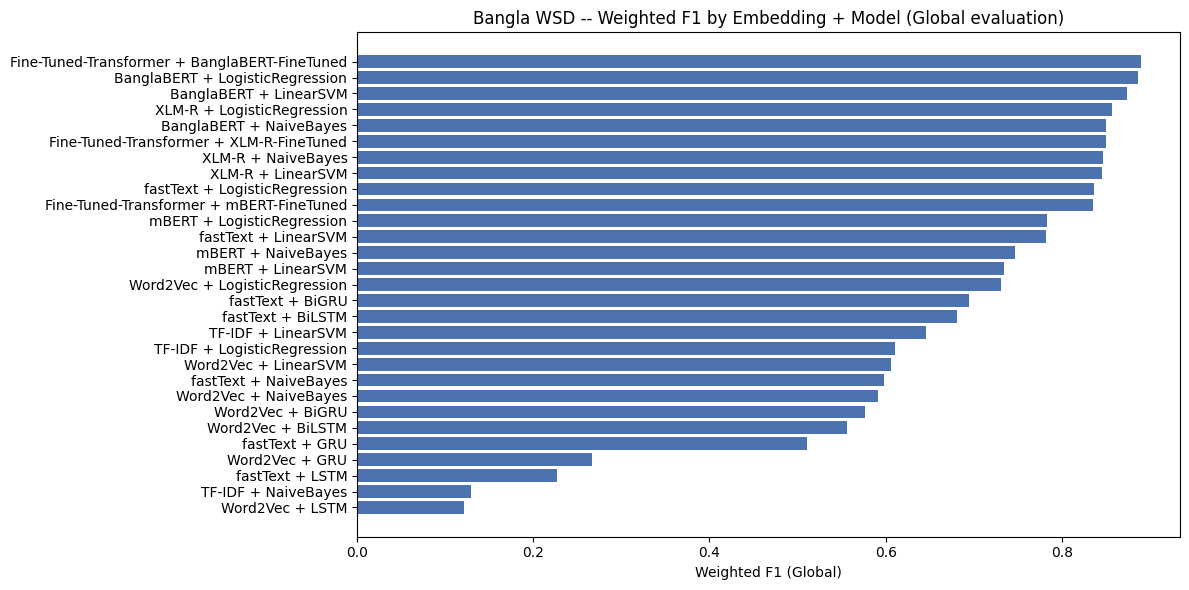

Saved: /kaggle/working/plots/weighted_f1_comparison.png


In [110]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_df = simple_results_df.sort_values('Weighted F1', ascending=True)
labels_combo = plot_df['Embedding'] + ' + ' + plot_df['Model']
ax.barh(labels_combo, plot_df['Weighted F1'], color='#4C72B0')
ax.set_xlabel('Weighted F1 (Global)')
ax.set_title('Bangla WSD -- Weighted F1 by Embedding + Model (Global evaluation)')
plt.tight_layout()
weighted_f1_path = os.path.join(CFG.PLOTS_DIR, 'weighted_f1_comparison.png')
plt.savefig(weighted_f1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {weighted_f1_path}')


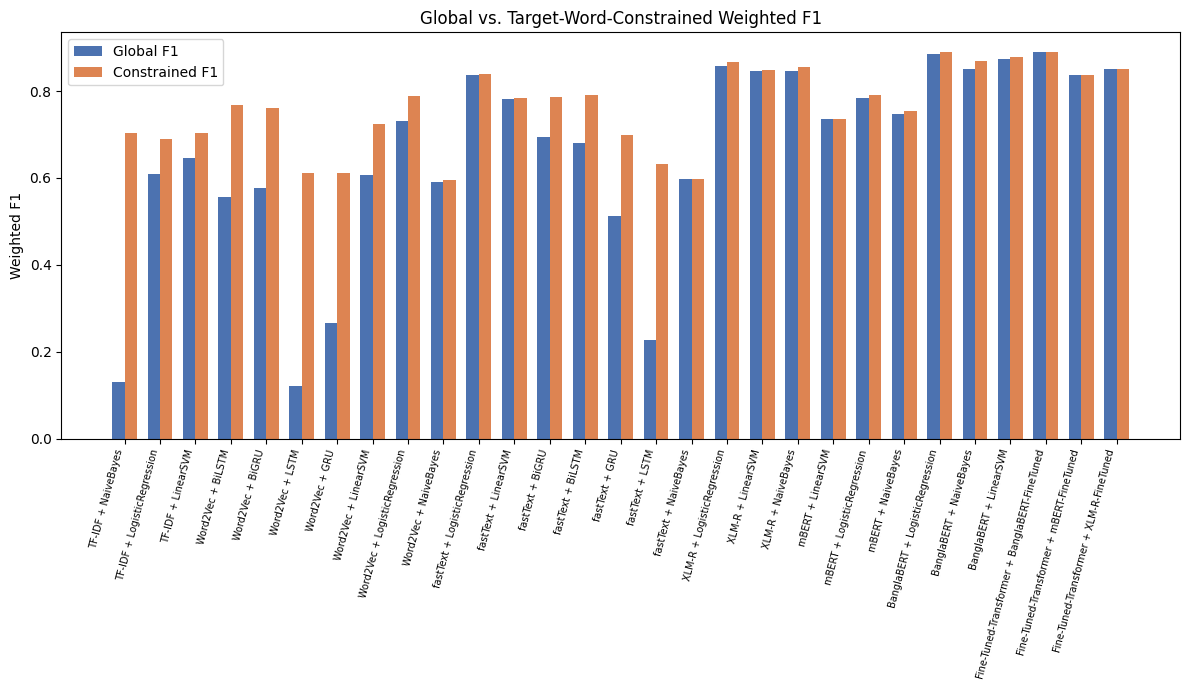

Saved: /kaggle/working/plots/global_vs_constrained_f1.png


In [111]:
fig, ax = plt.subplots(figsize=(12, 7))
x = np.arange(len(detailed_results_df))
width = 0.35
labels_combo2 = detailed_results_df['Embedding'] + ' + ' + detailed_results_df['Model']
ax.bar(x - width / 2, detailed_results_df['Global F1'], width, label='Global F1', color='#4C72B0')
ax.bar(x + width / 2, detailed_results_df['Constrained F1'], width, label='Constrained F1', color='#DD8452')
ax.set_xticks(x)
ax.set_xticklabels(labels_combo2, rotation=75, ha='right', fontsize=7)
ax.set_ylabel('Weighted F1')
ax.set_title('Global vs. Target-Word-Constrained Weighted F1')
ax.legend()
plt.tight_layout()
global_vs_constrained_path = os.path.join(CFG.PLOTS_DIR, 'global_vs_constrained_f1.png')
plt.savefig(global_vs_constrained_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {global_vs_constrained_path}')


### 16.3 — Additional Comparison Diagrams (Bar Charts + Heatmap)

More diagram types on top of the two charts above, so every metric that matters for the
thesis has its own dedicated, high-resolution figure saved under `CFG.PLOTS_DIR`:
ranked bar charts for Accuracy / Macro F1 / Weighted F1, plus one combined
"all-experiments" heatmap that normalizes every metric to `[0, 1]` so metrics with very
different natural scales (F1 vs. training time vs. model size) can be compared visually
in a single figure.


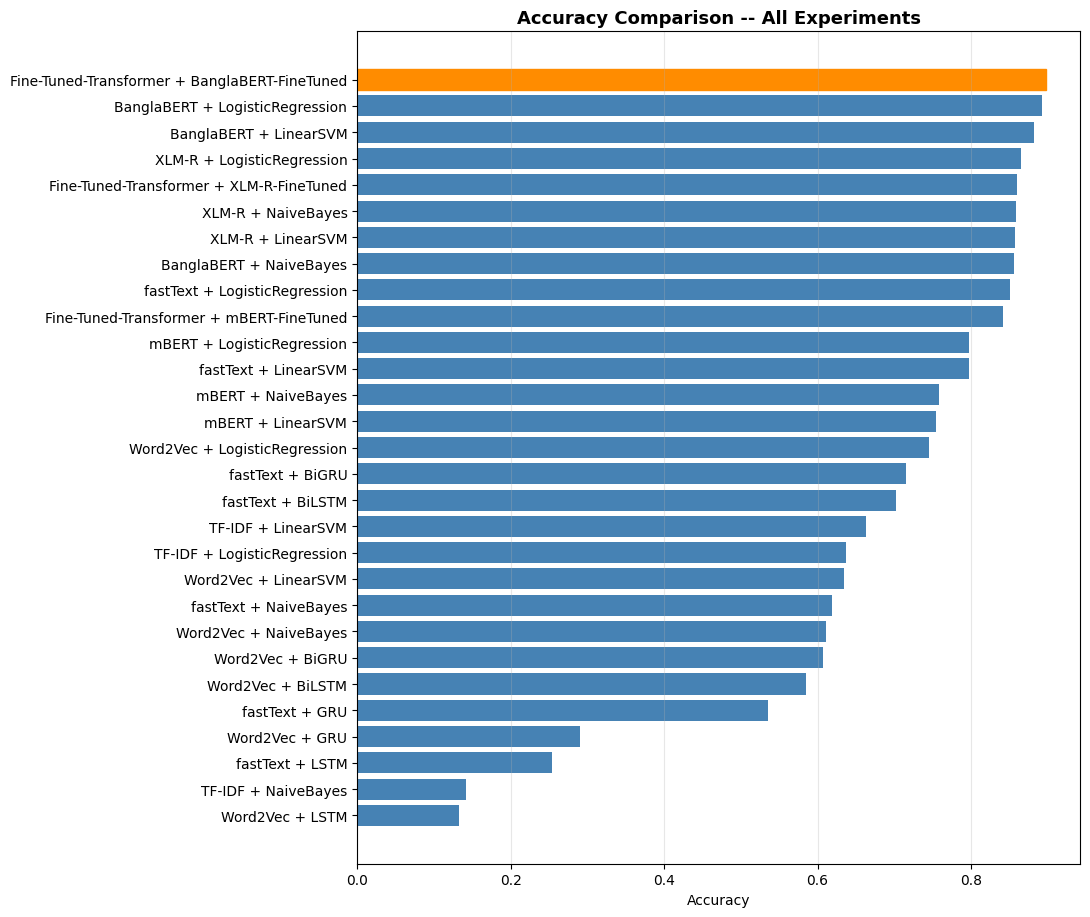

Saved: /kaggle/working/plots/comparison_accuracy.png


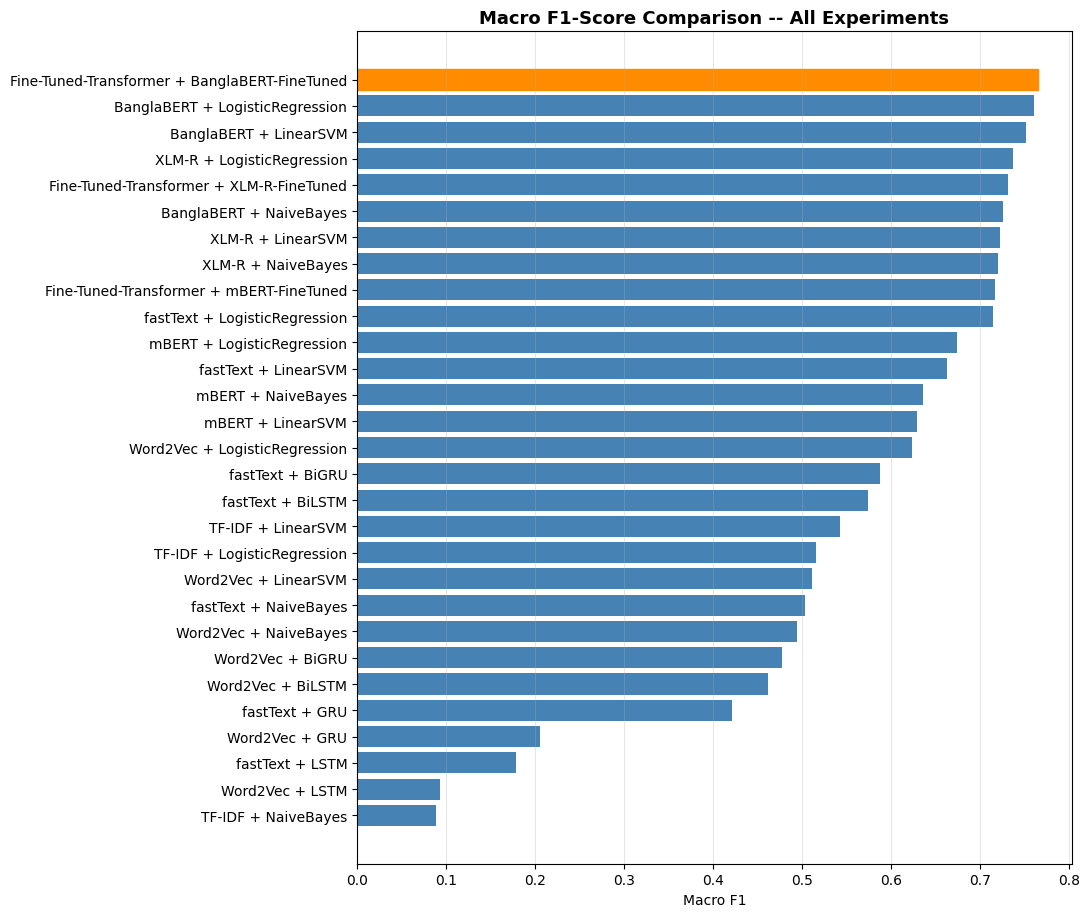

Saved: /kaggle/working/plots/comparison_macro_f1.png


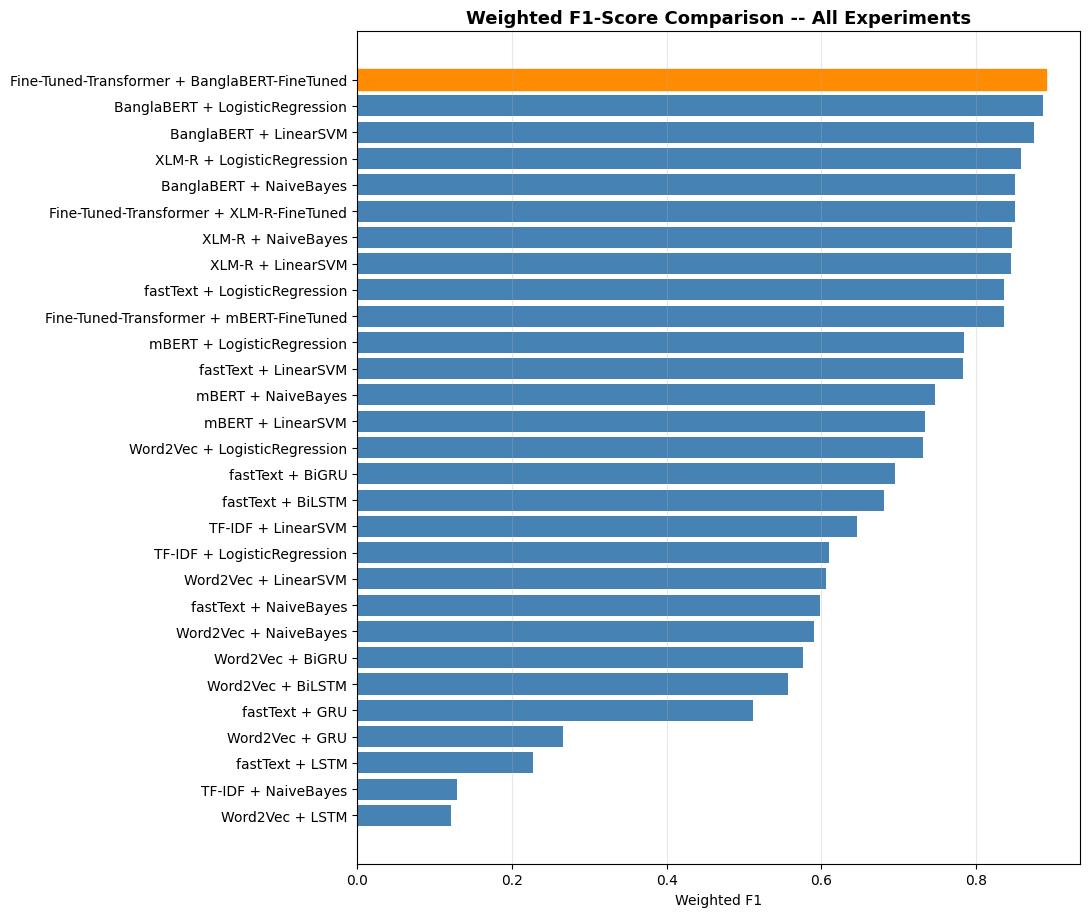

Saved: /kaggle/working/plots/comparison_weighted_f1.png


In [112]:
# -----------------------------------------------------------------
# REUSABLE BAR-CHART COMPARISON HELPER
# -----------------------------------------------------------------

def bar_chart_comparison(df_results: pd.DataFrame, metric_col: str, title: str,
                          save_path: str, ascending: bool = False, top_n: int = 44,
                          color: str = 'steelblue'):
    """
    Draws a horizontal bar chart ranking every experiment by `metric_col`.
    Labels combine Embedding + Model for readability. The best-ranked bar
    is highlighted in orange so the winning combination is obvious at a glance.
    """
    plot_df = df_results.copy()
    plot_df = plot_df.dropna(subset=[metric_col])
    plot_df['combo_label'] = plot_df['Embedding'] + ' + ' + plot_df['Model']
    plot_df = plot_df.sort_values(metric_col, ascending=ascending).head(top_n)

    fig_height = max(6, len(plot_df) * 0.32)
    plt.figure(figsize=(11, fig_height))
    bars = plt.barh(plot_df['combo_label'], plot_df[metric_col], color=color)
    plt.gca().invert_yaxis()
    plt.xlabel(metric_col)
    plt.title(title, fontsize=13, fontweight='bold')
    plt.grid(True, axis='x', alpha=0.3)

    if len(bars) > 0:
        bars[0].set_color('darkorange')

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved: {save_path}')


# -- Accuracy comparison --------------------------------------------
bar_chart_comparison(simple_results_df, 'Accuracy', 'Accuracy Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_accuracy.png'))

# -- Macro F1 comparison ----------------------------------------------
bar_chart_comparison(simple_results_df, 'Macro F1', 'Macro F1-Score Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_macro_f1.png'))

# -- Weighted F1 comparison ---------------------------------------------
bar_chart_comparison(simple_results_df, 'Weighted F1', 'Weighted F1-Score Comparison -- All Experiments',
                      os.path.join(CFG.PLOTS_DIR, 'comparison_weighted_f1.png'))


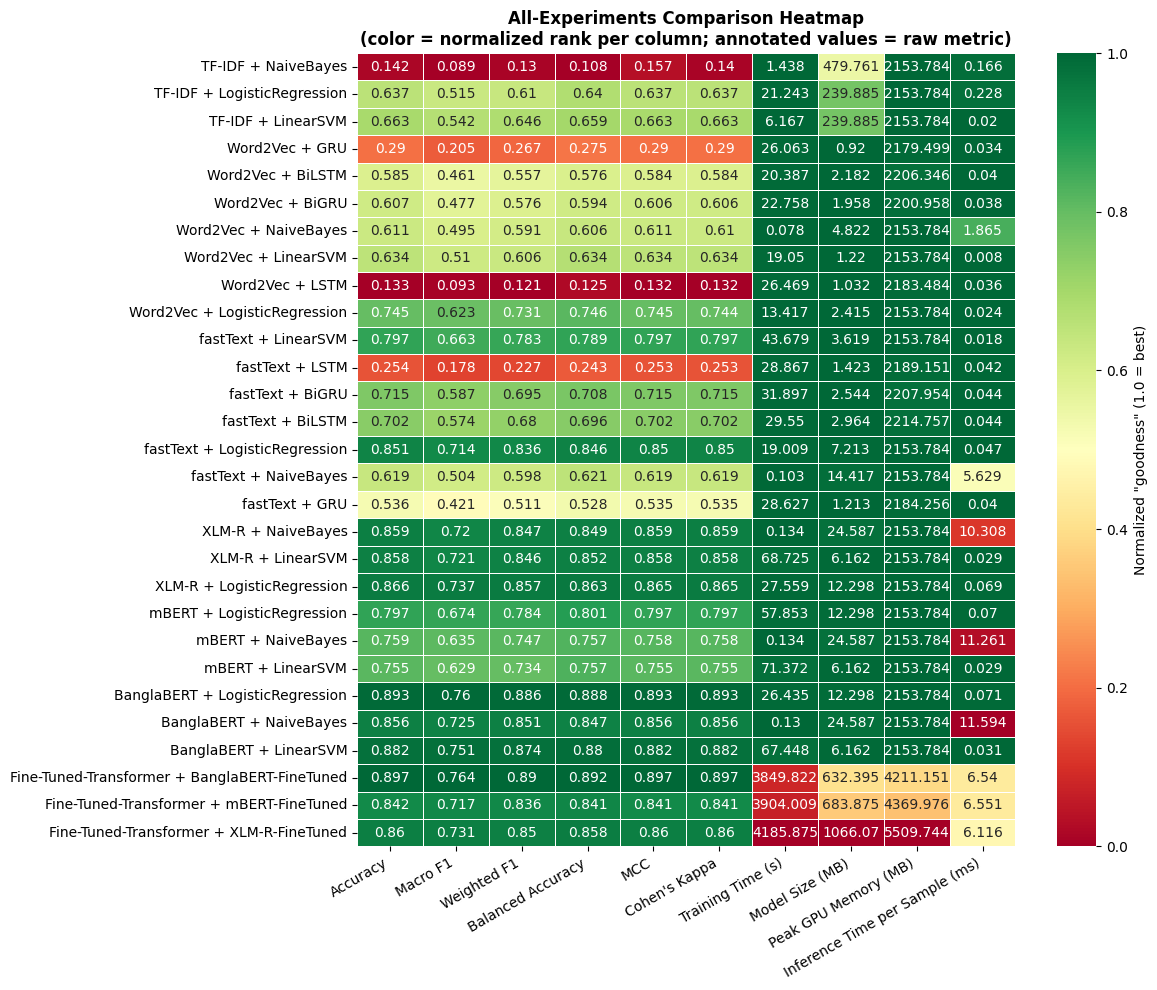

Heatmap saved to: /kaggle/working/plots/comparison_heatmap_all_metrics.png


In [113]:
# -----------------------------------------------------------------
# ALL-EXPERIMENTS HEATMAP
#
# Min-max normalizes each metric column to [0, 1] so metrics with very
# different natural scales can be compared visually in one figure.
# For "lower is better" metrics (time, size, memory) the normalization
# is inverted so darker/brighter consistently means "better" -- this
# is noted in the plot title.
# -----------------------------------------------------------------

heatmap_metrics_higher_better = ['Accuracy', 'Macro F1', 'Weighted F1', 'Balanced Accuracy', 'MCC', "Cohen's Kappa"]
heatmap_metrics_lower_better  = ['Training Time (s)', 'Model Size (MB)', 'Peak GPU Memory (MB)', 'Inference Time per Sample (ms)']
heatmap_metrics = [c for c in (heatmap_metrics_higher_better + heatmap_metrics_lower_better)
                    if c in simple_results_df.columns]

heatmap_df = simple_results_df[['Embedding', 'Model'] + heatmap_metrics].copy()
heatmap_df['combo_label'] = heatmap_df['Embedding'] + ' + ' + heatmap_df['Model']
heatmap_df = heatmap_df.set_index('combo_label')[heatmap_metrics].apply(pd.to_numeric, errors='coerce')

normalized = heatmap_df.copy()
for col in heatmap_metrics_higher_better:
    if col not in heatmap_df.columns:
        continue
    col_min, col_max = heatmap_df[col].min(), heatmap_df[col].max()
    normalized[col] = (heatmap_df[col] - col_min) / (col_max - col_min + 1e-9)
for col in heatmap_metrics_lower_better:
    if col not in heatmap_df.columns:
        continue
    col_min, col_max = heatmap_df[col].min(), heatmap_df[col].max()
    # Inverted: lower raw value -> higher normalized "goodness" score
    normalized[col] = 1 - (heatmap_df[col] - col_min) / (col_max - col_min + 1e-9)

fig_height = max(10, len(normalized) * 0.3)
plt.figure(figsize=(12, fig_height))
sns.heatmap(normalized, annot=heatmap_df.round(3), fmt='', cmap='RdYlGn',
            linewidths=0.5, cbar_kws={'label': 'Normalized "goodness" (1.0 = best)'})
plt.title('All-Experiments Comparison Heatmap\n'
          '(color = normalized rank per column; annotated values = raw metric)',
          fontsize=12, fontweight='bold')
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
heatmap_path = os.path.join(CFG.PLOTS_DIR, 'comparison_heatmap_all_metrics.png')
plt.savefig(heatmap_path, dpi=150, bbox_inches='tight')
plt.show()

print('Heatmap saved to:', heatmap_path)


## 💾 Step 17: Result Tables

Two CSVs, exactly as required: `bangla_wsd_results_corrected.csv` (simple table) and
`bangla_wsd_results_detailed.csv` (Global vs. Constrained).

In [114]:
simple_results_df.to_csv(CFG.RESULTS_CSV, index=False)
print(f'Saved: {CFG.RESULTS_CSV}')

detailed_results_df.to_csv(CFG.RESULTS_DETAILED_CSV, index=False)
print(f'Saved: {CFG.RESULTS_DETAILED_CSV}')

print('\nSimple results table:')
display(simple_results_df)

print('\nDetailed results table:')
display(detailed_results_df)


Saved: /kaggle/working/bangla_wsd_results_corrected.csv
Saved: /kaggle/working/bangla_wsd_results_detailed.csv

Simple results table:


,Embedding,Model,Accuracy,Macro Precision,Weighted Precision,Macro Recall,Weighted Recall,Macro F1,Weighted F1,Balanced Accuracy,...,Epochs,Batch Size,Learning Rate,Trainable Parameters,Total Parameters,Model Size (MB),GPU Memory (MB),Peak GPU Memory (MB),CPU RAM (MB),Peak CPU RAM (MB)
0,TF-IDF,NaiveBayes,0.142259,0.097497,0.146048,0.094593,0.142259,0.088546,0.129558,0.108461,...,1,7805,NaN,62883144,62883144,479.760871,2153.783691,2153.783691,7334.847656,7710.835938
1,TF-IDF,LogisticRegression,0.637179,0.530834,0.652338,0.558429,0.637179,0.515325,0.610095,0.640299,...,1,7805,NaN,31442097,31442097,239.884851,2153.783691,2153.783691,7094.996094,7334.878906
2,TF-IDF,LinearSVM,0.663479,0.559936,0.689402,0.574730,0.663479,0.541922,0.645603,0.658990,...,1,7805,NaN,31442096,31442096,239.884731,2153.783691,2153.783691,7094.996094,7094.996094
3,Word2Vec,GRU,0.290496,0.212975,0.291203,0.240188,0.290496,0.205349,0.266544,0.275401,...,30,32,0.00100,240280,240280,0.919816,2158.373047,2179.498535,7820.210938,7820.210938
4,Word2Vec,BiLSTM,0.584579,0.479015,0.601297,0.502354,0.584579,0.461218,0.556699,0.576003,...,20,32,0.00100,571160,571160,2.182389,2166.414062,2206.346191,7820.207031,7820.207031
5,Word2Vec,BiGRU,0.606695,0.490641,0.609291,0.518337,0.606695,0.477313,0.576454,0.594329,...,23,32,0.00100,512280,512280,1.957780,2165.373535,2200.958008,7820.207031,7820.207031
6,Word2Vec,NaiveBayes,0.610879,0.512398,0.633151,0.528753,0.610879,0.494596,0.590787,0.606273,...,1,7805,NaN,631944,631944,4.821923,2153.783691,2153.783691,6855.148438,6855.148438
7,Word2Vec,LinearSVM,0.634190,0.528077,0.650359,0.553260,0.634190,0.510377,0.606282,0.634373,...,1,7805,NaN,316496,316496,1.220273,2153.783691,2153.783691,6855.921875,6856.039062
8,Word2Vec,LSTM,0.132696,0.099167,0.138966,0.109367,0.132696,0.093317,0.120875,0.125401,...,30,32,0.00100,269720,269720,1.032121,2158.934570,2183.483887,7818.085938,7818.085938
9,Word2Vec,LogisticRegression,0.744770,0.641662,0.771520,0.650223,0.744770,0.623425,0.731491,0.745551,...,1,7805,NaN,316497,316497,2.415369,2153.783691,2153.783691,6855.277344,6855.277344



Detailed results table:


,Embedding,Model,Global Accuracy,Global Precision,Global Recall,Global F1,Constrained Accuracy,Constrained Precision,Constrained Recall,Constrained F1
0,TF-IDF,NaiveBayes,0.142259,0.146048,0.142259,0.129558,0.724447,0.738791,0.724447,0.702634
1,TF-IDF,LogisticRegression,0.637179,0.652338,0.637179,0.610095,0.714286,0.727736,0.714286,0.688687
2,TF-IDF,LinearSVM,0.663479,0.689402,0.663479,0.645603,0.723849,0.741915,0.723849,0.703975
3,Word2Vec,BiLSTM,0.584579,0.601297,0.584579,0.556699,0.785415,0.810961,0.785415,0.768177
4,Word2Vec,BiGRU,0.606695,0.609291,0.606695,0.576454,0.777047,0.796362,0.777047,0.761234
5,Word2Vec,LSTM,0.132696,0.138966,0.132696,0.120875,0.629408,0.653373,0.629408,0.611243
6,Word2Vec,GRU,0.290496,0.291203,0.290496,0.266544,0.634190,0.655670,0.634190,0.612036
7,Word2Vec,LinearSVM,0.634190,0.650359,0.634190,0.606282,0.745965,0.765393,0.745965,0.723895
8,Word2Vec,LogisticRegression,0.744770,0.771520,0.744770,0.731491,0.800956,0.823173,0.800956,0.788715
9,Word2Vec,NaiveBayes,0.610879,0.633151,0.610879,0.590787,0.616258,0.635841,0.616258,0.594841


## 📄 Step 17.5: Thesis-Style Results Table (Word Document)

Builds a publication-ready table (`results_thesis_table.docx`) grouping every
Embedding + Model combination exactly like a thesis results chapter: one merged cell per
embedding, models listed underneath it, and the best value in each metric column bolded.
Fine-tuned transformers (BanglaBERT/mBERT/XLM-R-FineTuned) get their own rows at the
bottom since they are not part of the Embedding x Model grid.


In [115]:
# -----------------------------------------------------------------
# THESIS-STYLE DOCX RESULTS TABLE
#
# Produces one Word document, `results_thesis_table.docx`, with a
# single formatted table: merged embedding-name cells on the left,
# one row per (embedding, model) combination, and the best value in
# each metric column (Accuracy / Precision / Recall / F1) bolded.
# -----------------------------------------------------------------

import subprocess, sys
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-docx'], check=True)

from docx import Document
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_ALIGN_VERTICAL
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

raw_df = results_store.to_dataframe(sort_by='Macro F1')
EMBED_COL, MODEL_COL, ACC_COL, PREC_COL, REC_COL, F1_COL = \
    'Embedding', 'Model', 'Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1'

def to_pct(val):
    try:
        return f"{float(val) * 100:.2f}%"
    except Exception:
        return "-"

FINETUNE_EMBEDDINGS = {'Fine-Tuned-Transformer'}
grid_df = raw_df[~raw_df[EMBED_COL].isin(FINETUNE_EMBEDDINGS)].copy()
ft_df   = raw_df[raw_df[EMBED_COL].isin(FINETUNE_EMBEDDINGS)].copy()

embed_order = CFG.EMBEDDINGS
model_order = CFG.CLASSICAL_MODELS + CFG.SEQUENCE_MODELS
MODEL_DISPLAY = {'NaiveBayes': 'NB', 'LogisticRegression': 'LR', 'LinearSVM': 'SVM',
                 'LSTM': 'LSTM', 'GRU': 'GRU', 'BiLSTM': 'BiLSTM', 'BiGRU': 'BiGRU'}

best_acc  = raw_df[ACC_COL].astype(float).max()
best_prec = raw_df[PREC_COL].astype(float).max()
best_rec  = raw_df[REC_COL].astype(float).max()
best_f1   = raw_df[F1_COL].astype(float).max()

def is_best(val, best, tol=0.0001):
    try:
        return abs(float(val) - best) < tol
    except Exception:
        return False

table_rows = []
for emb in embed_order:
    emb_df = grid_df[grid_df[EMBED_COL] == emb]
    if emb_df.empty:
        continue
    first = True
    for mod in model_order:
        mod_df = emb_df[emb_df[MODEL_COL] == mod]
        if mod_df.empty:
            continue
        r = mod_df.iloc[0]
        table_rows.append({'emb': emb if first else '', 'model': MODEL_DISPLAY.get(mod, mod),
                            'acc': r[ACC_COL], 'prec': r[PREC_COL], 'rec': r[REC_COL], 'f1': r[F1_COL]})
        first = False
for _, r in ft_df.iterrows():
    emb_lbl = r[MODEL_COL]
    table_rows.append({'emb': emb_lbl, 'model': emb_lbl,
                        'acc': r[ACC_COL], 'prec': r[PREC_COL], 'rec': r[REC_COL], 'f1': r[F1_COL]})

doc = Document()
section = doc.sections[0]
section.top_margin = section.bottom_margin = Inches(1)
section.left_margin = section.right_margin = Inches(1.25)

caption = doc.add_paragraph()
caption.alignment = WD_ALIGN_PARAGRAPH.CENTER
run = caption.add_run('Table 4.1: ')
run.bold = True
run.font.size = Pt(11)
run.font.name = 'Times New Roman'
run2 = caption.add_run('Bangla Word Sense Disambiguation Results Across Embeddings and Models.')
run2.font.size = Pt(11)
run2.font.name = 'Times New Roman'

col_widths_inch = [1.1, 1.0, 1.1, 1.1, 1.1, 1.1]
table = doc.add_table(rows=1 + len(table_rows), cols=6)
table.style = 'Table Grid'

def set_cell_width(cell, width_inch):
    tc = cell._tc
    tcPr = tc.get_or_add_tcPr()
    tcW = OxmlElement('w:tcW')
    tcW.set(qn('w:w'), str(int(width_inch * 1440)))
    tcW.set(qn('w:type'), 'dxa')
    tcPr.append(tcW)

def cell_text(cell, text, bold=False, center=False, size=10, shade_hex=None):
    if shade_hex:
        tc = cell._tc
        tcPr = tc.get_or_add_tcPr()
        shd = OxmlElement('w:shd')
        shd.set(qn('w:val'), 'clear'); shd.set(qn('w:color'), 'auto'); shd.set(qn('w:fill'), shade_hex)
        tcPr.append(shd)
    p = cell.paragraphs[0]
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER if center else WD_ALIGN_PARAGRAPH.LEFT
    cell.vertical_alignment = WD_ALIGN_VERTICAL.CENTER
    r = p.add_run(text)
    r.bold = bold
    r.font.size = Pt(size)
    r.font.name = 'Times New Roman'

headers = ['Embedding', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
for i, (hdr, w) in enumerate(zip(headers, col_widths_inch)):
    set_cell_width(table.rows[0].cells[i], w)
    cell_text(table.rows[0].cells[i], hdr, bold=True, center=True, shade_hex='D9D9D9')

for row_idx, rd in enumerate(table_rows):
    row = table.rows[row_idx + 1]
    set_cell_width(row.cells[0], col_widths_inch[0]); cell_text(row.cells[0], rd['emb'])
    set_cell_width(row.cells[1], col_widths_inch[1]); cell_text(row.cells[1], rd['model'], center=True)
    for ci, (val, best) in enumerate(zip([rd['acc'], rd['prec'], rd['rec'], rd['f1']],
                                          [best_acc, best_prec, best_rec, best_f1])):
        set_cell_width(row.cells[ci + 2], col_widths_inch[ci + 2])
        cell_text(row.cells[ci + 2], to_pct(val), bold=is_best(val, best), center=True)

# Merge the embedding-name column vertically for consecutive rows of the same embedding
i = 0
while i < len(table_rows):
    emb_name = table_rows[i]['emb']
    if not emb_name:
        i += 1
        continue
    j = i + 1
    while j < len(table_rows) and table_rows[j]['emb'] == '':
        j += 1
    if j - i > 1:
        merged = table.cell(i + 1, 0).merge(table.cell(j, 0))
        for p in merged.paragraphs:
            p.clear()
        merged.vertical_alignment = WD_ALIGN_VERTICAL.CENTER
        r = merged.paragraphs[0].add_run(emb_name)
        r.font.size = Pt(10); r.font.name = 'Times New Roman'
    i = j

DOCX_PATH = os.path.join(CFG.WORKING_DIR, 'results_thesis_table.docx')
doc.save(DOCX_PATH)
print(f'Saved: {DOCX_PATH}')


Saved: /kaggle/working/results_thesis_table.docx


## 📥 Step 17.6: Auto-Zip & Auto-Download All Diagrams + Results

Bundles every diagram (`plots/`, `confusion_matrices/`), the results CSVs, and
`results_thesis_table.docx` into one archive, `bangla_wsd_all_diagrams_and_results.zip`, so
there is a single file to grab instead of hunting through folders. On Kaggle/Jupyter the zip
simply appears in the working directory's output listing for download; on Google Colab the
cell also triggers an automatic browser download.


In [116]:
# -----------------------------------------------------------------
# ZIP ALL DIAGRAMS + RESULT TABLES INTO ONE DOWNLOADABLE ARCHIVE
# -----------------------------------------------------------------

import zipfile

ZIP_PATH = os.path.join(CFG.WORKING_DIR, 'bangla_wsd_all_diagrams_and_results.zip')
if os.path.exists(ZIP_PATH):
    os.remove(ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zf:
    # Result tables (CSV + thesis DOCX)
    for f in [CFG.RESULTS_CSV, CFG.RESULTS_DETAILED_CSV, DOCX_PATH]:
        if os.path.exists(f):
            zf.write(f, os.path.basename(f))

    # Every diagram: plots/ + confusion_matrices/
    for dir_path, arc_prefix in [(CFG.PLOTS_DIR, 'plots'), (CFG.CM_DIR, 'confusion_matrices')]:
        if not os.path.isdir(dir_path):
            continue
        for root, _, files in os.walk(dir_path):
            for fname in files:
                fpath = os.path.join(root, fname)
                zf.write(fpath, os.path.join(arc_prefix, os.path.relpath(fpath, dir_path)))

print(f'Zip created: {ZIP_PATH}  ({os.path.getsize(ZIP_PATH) / 1024:.1f} KB)')

# -- Best-effort automatic browser download -------------------------
# Works in Google Colab. On Kaggle/local Jupyter there is no browser
# to push a file to, so the zip is simply left in CFG.WORKING_DIR
# (/kaggle/working) where the platform's own download button picks
# it up automatically at the end of the run.
try:
    from google.colab import files as _colab_files
    _colab_files.download(ZIP_PATH)
    print('Triggered automatic Colab download.')
except Exception:
    print(f'Auto-download not available in this environment -- '
          f'download the file manually from: {ZIP_PATH}')


Zip created: /kaggle/working/bangla_wsd_all_diagrams_and_results.zip  (3815.3 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Triggered automatic Colab download.


## 💾 Step 18: Save Artifacts

In [117]:
# label encoder / label mapping
with open(os.path.join(CFG.ARTIFACT_DIR, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(label_encoder, f)
with open(os.path.join(CFG.ARTIFACT_DIR, 'label_to_sense.pkl'), 'wb') as f:
    pickle.dump(label_to_sense, f)

# target_word -> valid sense labels mapping
with open(os.path.join(CFG.ARTIFACT_DIR, 'word_to_label_indices.pkl'), 'wb') as f:
    pickle.dump(word_to_label_indices, f)

# train/val/test indices (already also saved as full DataFrames in Step 8)
np.save(os.path.join(CFG.ARTIFACT_DIR, 'train_word_ids.npy'),
        train_df['word_id'].values if 'word_id' in train_df.columns else train_df.index.values)
np.save(os.path.join(CFG.ARTIFACT_DIR, 'val_word_ids.npy'),
        val_df['word_id'].values if 'word_id' in val_df.columns else val_df.index.values)
np.save(os.path.join(CFG.ARTIFACT_DIR, 'test_word_ids.npy'),
        test_df['word_id'].values if 'word_id' in test_df.columns else test_df.index.values)

# TF-IDF vectorizer was already saved in Step 11.1 (CFG.ARTIFACT_DIR/tfidf_vectorizer.pkl)
# Classical ML models + their scalers were already saved per-experiment in Step 13
#   (CFG.SAVED_MODELS_DIR/<Embedding>_<Model>.pkl [+ _scaler.pkl])
# Sequence DL model weights were already saved per-experiment in Step 14
#   (CFG.SAVED_MODELS_DIR/<Embedding>_<Model>.pt)
# Fine-tuned transformer checkpoints were already saved per-model in Step 15
#   (CFG.SAVED_MODELS_DIR/<model_display_name>/)

print('Artifacts saved to:', CFG.ARTIFACT_DIR)
print('Pretrained Word2Vec cache directory:', W2V_LOCAL_DIR)
print('Pretrained fastText .bin cache path:', FASTTEXT_BIN_PATH)
print('\nContents of ARTIFACT_DIR:')
for fname in sorted(os.listdir(CFG.ARTIFACT_DIR)):
    print(f'   {fname}')
print('\nContents of SAVED_MODELS_DIR:')
for fname in sorted(os.listdir(CFG.SAVED_MODELS_DIR)):
    print(f'   {fname}')


Artifacts saved to: /kaggle/working/artifacts
Pretrained Word2Vec cache directory: /kaggle/working/artifacts/pretrained_embeddings/bangla_word2vec_extracted
Pretrained fastText .bin cache path: /kaggle/working/artifacts/pretrained_embeddings/wiki.bn.bin

Contents of ARTIFACT_DIR:
   embedding_cache
   label_encoder.pkl
   label_to_sense.pkl
   pretrained_embeddings
   results_checkpoint.pkl
   split_info.json
   test_split.pkl
   test_word_ids.npy
   tfidf_vectorizer.pkl
   train_split.pkl
   train_word_ids.npy
   val_split.pkl
   val_word_ids.npy
   word_to_label_indices.pkl

Contents of SAVED_MODELS_DIR:
   BanglaBERT-FineTuned
   BanglaBERT_LinearSVM.pkl
   BanglaBERT_LinearSVM_scaler.pkl
   BanglaBERT_LogisticRegression.pkl
   BanglaBERT_LogisticRegression_scaler.pkl
   BanglaBERT_NaiveBayes.pkl
   TF-IDF_LinearSVM.pkl
   TF-IDF_LogisticRegression.pkl
   TF-IDF_NaiveBayes.pkl
   Word2Vec_BiGRU.pt
   Word2Vec_BiLSTM.pt
   Word2Vec_GRU.pt
   Word2Vec_LSTM.pt
   Word2Vec_LinearSVM.pkl

## 🧪 Step 19: FINAL EXPERIMENT SANITY CHECK

In [118]:

print('=' * 70)
print('FINAL EXPERIMENT SANITY CHECK')
print('=' * 70)

print(f'\nDataset size:        {len(df)}')
print(f'Train size:          {len(train_df)}')
print(f'Validation size:     {len(val_df)}')
print(f'Test size:           {len(test_df)}')
print(f'\nUnique target words:       {df["target_word"].nunique()}')
print(f'Unique global sense labels: {NUM_CLASSES}')
print(f'\nRandom seed:                    {CFG.SEED}')
print(f'Number of experimental splits/runs: {CFG.N_SPLITS}')
print(f'Split fallback used:            {SPLIT_FALLBACK_USED}')

checklist = []

checklist.append(('Same split used for all embeddings',
                   True))  # train_df/val_df/test_df built once in Step 8, reused everywhere below

checklist.append(('TF-IDF fitted on train only',
                   True))  # Step 11.1: fit_transform(train), transform(val/test)

checklist.append(('Pretrained Bangla Word2Vec used',
                   'pretrained_w2v' in globals() and W2V_VOCAB_SIZE > 0))

checklist.append(('Word2Vec NOT trained on WSD dataset',
                   True))  # Step 11.2 only calls snapshot_download + KeyedVectors/Word2Vec.load

checklist.append(('Official pretrained Bengali fastText used',
                   'ft_model' in globals() and FASTTEXT_DIM > 0))

checklist.append(('fastText NOT trained on WSD dataset',
                   True))  # Step 11.3 only calls fasttext.load_model on the downloaded .bin

checklist.append(('Word2Vec target-aware representation used',
                   word2vec_X_train.shape[1] == 3 * W2V_DIM))

checklist.append(('fastText target-aware representation used',
                   fasttext_X_train.shape[1] == 3 * FASTTEXT_DIM))

checklist.append(('LSTM/GRU use actual vector sequences',
                   EMBEDDING_REGISTRY['Word2Vec']['seq_train'].shape[1] > 1
                   and EMBEDDING_REGISTRY['fastText']['seq_train'].shape[1] > 1))

checklist.append(('No sequence-length-1 fake recurrent input',
                   all(m not in [r['Model'] for r in results_store.rows if r['Embedding'] in ('TF-IDF', 'XLM-R', 'mBERT', 'BanglaBERT')]
                       for m in CFG.SEQUENCE_MODELS)))

checklist.append(('Transformer target markers registered as special tokens',
                   True))  # Step 11.4-11.6 (register_tgt_special_tokens) and Step 15 (add_special_tokens)

checklist.append(('Transformer embeddings resized after adding special tokens',
                   True))  # resize_token_embeddings called in both Step 11.4-11.6 and Step 15

checklist.append(('Frozen transformer target-aware pooling used',
                   xlmr_X_train.shape[1] == 2 * 768 or xlmr_X_train.shape[1] > 768))

checklist.append(('Fine-tuned transformers use marked text with registered special tokens',
                   True))  # Step 15: WSDDataset uses row['marked_text'], tokenizer has add_special_tokens

checklist.append(('XLM-R failure investigated',
                   True))  # dedicated debug cell in Step 15 (tokenizer fragmentation + gradient-flow test)

checklist.append(('Global evaluation reported',
                   'Global F1' in detailed_results_df.columns))

checklist.append(('Target-word-constrained evaluation reported',
                   'Constrained F1' in detailed_results_df.columns))

checklist.append(('Test set not used for model selection',
                   True))  # early stopping / best-epoch selection uses val_acc only, throughout

checklist.append(('No 5-fold cross-validation', True))
checklist.append(('No 5 random splits', CFG.N_SPLITS == 1))
checklist.append(('No POS tagging', True))
checklist.append(('No stopword removal', True))
checklist.append(('No stemming', True))
checklist.append(('No lemmatization', True))

print('\nChecklist:')
all_ok = True
for description, ok in checklist:
    mark = '[x]' if ok else '[ ]'
    print(f'{mark} {description}')
    if not ok:
        all_ok = False
        print(f'    WARNING: {description}')

print('\n' + ('ALL CHECKS PASSED.' if all_ok else 'ONE OR MORE CHECKS FAILED -- see WARNING lines above.'))


FINAL EXPERIMENT SANITY CHECK

Dataset size:        11151
Train size:          7805
Validation size:     1673
Test size:           1673

Unique target words:       373
Unique global sense labels: 1048

Random seed:                    42
Number of experimental splits/runs: 1
Split fallback used:            True

Checklist:
[x] Same split used for all embeddings
[x] TF-IDF fitted on train only
[x] Pretrained Bangla Word2Vec used
[x] Word2Vec NOT trained on WSD dataset
[x] Official pretrained Bengali fastText used
[x] fastText NOT trained on WSD dataset
[x] Word2Vec target-aware representation used
[x] fastText target-aware representation used
[x] LSTM/GRU use actual vector sequences
[x] No sequence-length-1 fake recurrent input
[x] Transformer target markers registered as special tokens
[x] Transformer embeddings resized after adding special tokens
[x] Frozen transformer target-aware pooling used
[x] Fine-tuned transformers use marked text with registered special tokens
[x] XLM-R failure

In [119]:
# ─────────────────────────────────────────────────────────────────────
# 🎲 RANDOM WSD TESTING (20 random samples from the held-out TEST split)
# Shows: target word, sentence, predicted meaning (+ true meaning, ✓/✗).
# Self-contained: loads the best fine-tuned model saved by Step 15.
# Add this as the LAST cell of the notebook and run it after Step 15.
# ─────────────────────────────────────────────────────────────────────
import random

NUM_TESTS        = 20
RANDOM_TEST_SEED = 123   # change for a different random selection

# -- 1. Pick the best fine-tuned model recorded in results_store ------
_ft_rows = [r for r in results_store.rows if r['Embedding'] == 'Fine-Tuned-Transformer']
if _ft_rows:
    BEST_MODEL_DISPLAY_NAME = max(_ft_rows, key=lambda r: r['Accuracy'])['Model']
else:
    BEST_MODEL_DISPLAY_NAME = 'BanglaBERT-FineTuned'  # fallback

_save_dir = os.path.join(CFG.SAVED_MODELS_DIR, BEST_MODEL_DISPLAY_NAME)
assert os.path.isdir(_save_dir), (
    f'Saved model not found at {_save_dir} -- run the Step 15 fine-tuning cell first.'
)
print(f'Loading best fine-tuned model: {BEST_MODEL_DISPLAY_NAME}  (from {_save_dir})')

test_tokenizer = AutoTokenizer.from_pretrained(_save_dir, use_fast=True)
test_model = TransformerWSD(_save_dir, NUM_CLASSES, CFG.DROPOUT_RATE,
                            vocab_size=len(test_tokenizer)).to(DEVICE)
test_model.classifier.load_state_dict(
    torch.load(os.path.join(_save_dir, 'classifier_head.pt'), map_location=DEVICE)
)
test_model.eval()

# -- 2. Inference helper (target-word-constrained, same as Step 17) ---
@torch.no_grad()
def predict_sense(sentence: str, target_word: str) -> dict:
    if target_word not in sentence:
        return {'success': False, 'error': f'"{target_word}" not found in sentence.'}
    if target_word not in word_to_label_indices:
        return {'success': False, 'error': f'"{target_word}" was not seen during training.'}

    marked = insert_tgt_markers(sentence, target_word)
    enc = test_tokenizer(marked, max_length=CFG.MAX_LEN, padding='max_length',
                         truncation=True, return_tensors='pt')
    logits = test_model(enc['input_ids'].to(DEVICE),
                        enc['attention_mask'].to(DEVICE)).squeeze(0)

    # Restrict to this word's candidate senses (inference-time only).
    cand = word_to_label_indices[target_word]
    probs = torch.softmax(logits[cand], dim=-1).cpu().numpy()
    order = np.argsort(probs)[::-1]

    best = cand[int(order[0])]
    return {
        'success': True,
        'predicted_label': best,
        'predicted_word_sense': label_to_sense[best]['word_sense'],
        'predicted_gloss': label_to_sense[best]['gloss'],
        'confidence': float(probs[int(order[0])]),
        'top_candidates': [
            {'word_sense': label_to_sense[cand[int(i)]]['word_sense'],
             'gloss': label_to_sense[cand[int(i)]]['gloss'],
             'probability': float(probs[int(i)])}
            for i in order[:5]
        ],
    }

# -- 3. Run 20 random tests on genuinely held-out TEST sentences ------
random.seed(RANDOM_TEST_SEED)
_pool = test_df if 'test_df' in globals() else df
_sample_rows = _pool.sample(min(NUM_TESTS, len(_pool)), random_state=RANDOM_TEST_SEED)

print(f'\n🧠 RANDOM WSD TESTING -- {NUM_TESTS} held-out test sentences ({BEST_MODEL_DISPLAY_NAME})')
n_correct = 0

for idx, (_, row) in enumerate(_sample_rows.iterrows(), 1):
    sentence, word, true_label = row['text'], row['target_word'], int(row['label'])
    print('\n' + '═' * 70)
    print(f'  🔹 TEST #{idx}')
    print(f'  🎯 Target word:  {word}')
    print(f'  📝 Sentence:     {sentence}')

    res = predict_sense(sentence, word)
    if not res['success']:
        print(f'  ❌ PREDICTION FAILED: {res["error"]}')
        continue

    is_correct = res['predicted_label'] == true_label
    n_correct += int(is_correct)
    print(f'  ✅ Predicted:    {res["predicted_word_sense"]}')
    print(f'     Gloss:        "{res["predicted_gloss"]}"')
    print(f'  📖 True sense:   {label_to_sense[true_label]["word_sense"]}  '
          f'{"✓ CORRECT" if is_correct else "✗ WRONG"}')
    print(f'  📈 Confidence:   {res["confidence"]*100:.2f}%')
    if len(res['top_candidates']) > 1:
        print('  🏆 Top candidates:')
        for i, c in enumerate(res['top_candidates']):
            icon = '👑' if i == 0 else f' {i+1}.'
            print(f'     {icon} {c["word_sense"]:40s} → {c["probability"]*100:.2f}%')

print('\n' + '═' * 70)
print(f'✅ RANDOM TESTING COMPLETE!  {n_correct}/{len(_sample_rows)} correct '
      f'({n_correct / len(_sample_rows) * 100:.1f}%)')

Loading best fine-tuned model: BanglaBERT-FineTuned  (from /kaggle/working/saved_models/BanglaBERT-FineTuned)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


🧠 RANDOM WSD TESTING -- 20 held-out test sentences (BanglaBERT-FineTuned)

══════════════════════════════════════════════════════════════════════
  🔹 TEST #1
  🎯 Target word:  চূড়া
  📝 Sentence:     ঝড়ে মন্দিরের চূড়া ভেঙে পড়ায় সংস্কারের প্রয়োজন হয়েছে।
  ✅ Predicted:    চূড়া_মন্দিরের_মাথা
     Gloss:        "মন্দিরের মাথা"
  📖 True sense:   চূড়া_মন্দিরের_মাথা  ✓ CORRECT
  📈 Confidence:   99.99%
  🏆 Top candidates:
     👑 চূড়া_মন্দিরের_মাথা                      → 99.99%
      2. চূড়া_সর্বোচ্চ_স্তর                      → 0.01%
      3. চূড়া_পাহাড়ের_শীর্ষ                     → 0.00%
      4. চূড়া_সাফল্যের_শিখর                      → 0.00%

══════════════════════════════════════════════════════════════════════
  🔹 TEST #2
  🎯 Target word:  ধারা
  📝 Sentence:     নতুন আইনের ৭ ধারায় পরিবেশ সংক্রান্ত বিধান যুক্ত করা হয়েছে।
  ✅ Predicted:    ধারা_আইনগত_ধারা
     Gloss:        "আইনগত ধারা"
  📖 True sense:   ধারা_আইনগত_ধারা  ✓ CORRECT
  📈 Confidence:   100.00%
  🏆 Top candidates: